# Advanced Predictive Modelling for Customer Churn: A Comparative Analysis of Machine Learning and Deep Learning Techniques

**Duc Le — MSc Dissertation**

---

This notebook implements the methodology specified in the research proposal
(`01_Duc_Le_Research_proposal.md`) on the dataset `customer_churn_1M.csv`
(1,000,000 customers, one row per customer).

## Mapping: proposal section → notebook part

| Proposal | Requirement | Notebook |
|---|---|---|
| §7.1 | Dataset description | Part 0–1 |
| §7.2 | Missing data (median/mode), one-hot encoding, standardisation, SMOTE + GAN | Part 4–5 |
| §7.3 | Feature engineering (5 groups, EDA-driven) | Part 1–2 |
| §7.4 | Stratified 80/20 split + repeated stratified k-fold CV | Part 3, 6 |
| §7.5 | ML: LR, DT, RF, XGBoost · DL: ANN, DNN | Part 7 |
| §7.6 | Grid Search vs Random Search vs Optuna (ML only) | Part 8 |
| §7.7 | Accuracy, Precision, Recall, F1, AUC, **execution time** | Part 6–7 |
| §7.7 Table 9 | Paired t-test / Wilcoxon + bootstrap 95% CI | Part 9 |
| §7.8 | SHAP (TreeSHAP for trees, KernelSHAP for DL) | Part 10 |

## Scope note on domain framing

The proposal is motivated by **banking** churn. `customer_churn_1M.csv` uses a
subscription-services schema (contract type, monthly charges, service
attachments). Following the cross-industry argument already made in the
literature review (§2, citing Boozary 2025; Ahmed *et al.* 2023 on the
transferability of churn methodology across banking, telecommunications and
e-commerce), this study is positioned as a **cross-domain churn methodology
evaluation with banking as the motivating context**. The five feature groups of
§7.3 are implemented as domain analogues; the mapping is stated explicitly in
Part 2.

## Compute protocol note

Per §7.6, all three hyperparameter search strategies (Grid, Random, Optuna) are
compared. Exhaustive grid search over 1,000,000 rows is not computationally
feasible (a single Random Forest fit at 800k rows takes ≈73 s on the study
hardware; the specified RF grid would require ≈66 hours). All three searches are
therefore run on a **stratified 100,000-row subsample**, and the winning
configuration of each is **refit and reported on the full dataset**. Both sets of
numbers are reported. This is a deliberate compute trade-off of the same kind
§7.2 already makes in preferring median/mode imputation over MICE/kNN.

---
# Part 0 — Environment, reproducibility and data loading

In [1]:
# ---- Reproducibility and thread control -------------------------------------
import os, sys, time, json, warnings, platform, random
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")
os.environ.setdefault("PYTHONHASHSEED", "42")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.autolayout": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "axes.titleweight": "semibold",
    "legend.frameon": True,
})

# Consistent, colour-blind-safe palette used throughout
C_STAY, C_CHURN = "#4C78A8", "#E45756"
C_ML, C_DL = "#4C78A8", "#F58518"
PALETTE_SEQ = "viridis"

FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)

def savefig(name, fig=None, tight=True):
    """Save the current figure into ./figures for direct use in the dissertation."""
    fig = fig or plt.gcf()
    if tight:
        fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"{name}.png"), bbox_inches="tight", facecolor="white")

In [2]:
# ---- Study configuration -----------------------------------------------------
CONFIG = dict(
    DATA_PATH        = "customer_churn_1M.csv",
    TARGET           = "churn",
    ID_COLS          = ["customer_id"],
    TEST_SIZE        = 0.20,     # §7.4 stratified 80/20 split
    N_SPLITS         = 5,        # §7.4 stratified k-fold
    N_REPEATS        = 3,        # §7.7 Table 9 repeated CV for significance testing
    TUNE_SAMPLE_N    = 100_000,  # §7.6 tuning subsample (see compute protocol note)
    RANDOM_STATE     = RANDOM_STATE,
    # Runtime-benchmarking protocol, §7.7 Table 8
    TIMING_WARMUP    = 2,
    TIMING_REPEATS   = 10,
    # DL settings (literature-informed, NOT tuned — §7.6, §10a)
    DL_EPOCHS        = 40,
    DL_BATCH_SIZE    = 1024,
    DL_PATIENCE      = 6,
    # CTGAN oversampling (§7.2 GAN arm)
    CTGAN_EPOCHS     = 60,
    CTGAN_FIT_N      = 12_000,   # minority rows used to fit the generator
)
globals().update({k: v for k, v in CONFIG.items()})
print(json.dumps({k: str(v) for k, v in CONFIG.items()}, indent=2))

{
  "DATA_PATH": "customer_churn_1M.csv",
  "TARGET": "churn",
  "ID_COLS": "['customer_id']",
  "TEST_SIZE": "0.2",
  "N_SPLITS": "5",
  "N_REPEATS": "3",
  "TUNE_SAMPLE_N": "100000",
  "RANDOM_STATE": "42",
  "TIMING_WARMUP": "2",
  "TIMING_REPEATS": "10",
  "DL_EPOCHS": "40",
  "DL_BATCH_SIZE": "1024",
  "DL_PATIENCE": "6",
  "CTGAN_EPOCHS": "60",
  "CTGAN_FIT_N": "12000"
}


In [3]:
# ---- Hardware specification (§7.7 Table 8: "Hardware specification") ---------
def hardware_spec():
    import multiprocessing
    spec = {
        "platform":      platform.platform(),
        "machine":       platform.machine(),
        "processor":     platform.processor() or platform.machine(),
        "logical_cores": multiprocessing.cpu_count(),
        "python":        sys.version.split()[0],
    }
    try:
        import psutil
        spec["ram_gb"] = round(psutil.virtual_memory().total / 1024**3, 1)
    except Exception:
        try:
            spec["ram_gb"] = round(int(os.popen("sysctl -n hw.memsize").read()) / 1024**3, 1)
        except Exception:
            spec["ram_gb"] = "n/a"
    try:
        import tensorflow as tf
        spec["gpu_devices"] = [d.name for d in tf.config.list_physical_devices("GPU")] or "none (CPU only)"
    except Exception:
        spec["gpu_devices"] = "tensorflow not loaded"
    return spec

HARDWARE = hardware_spec()
pd.Series(HARDWARE).to_frame("value")

,value
platform,macOS-26.5.2-arm64-arm-64bit
machine,arm64
processor,arm
logical_cores,8
python,3.12.7
ram_gb,16.0000
gpu_devices,none (CPU only)


In [4]:
# ---- Library versions (for the reproducibility appendix) --------------------
import importlib
_libs = ["numpy", "pandas", "sklearn", "scipy", "matplotlib", "seaborn",
         "xgboost", "imblearn", "optuna", "shap", "tensorflow", "ctgan", "statsmodels"]
_rows = []
for _m in _libs:
    try:
        _rows.append((_m, getattr(importlib.import_module(_m), "__version__", "?")))
    except Exception:
        _rows.append((_m, "NOT INSTALLED"))
VERSIONS = pd.DataFrame(_rows, columns=["library", "version"])
VERSIONS

,library,version
0,numpy,1.26.4
1,pandas,2.2.2
2,sklearn,1.8.0
3,scipy,1.13.1
4,matplotlib,3.9.2
5,seaborn,0.13.2
6,xgboost,3.2.0
7,imblearn,0.14.1
8,optuna,4.8.0
9,shap,0.46.0


In [5]:
# ---- Load the dataset --------------------------------------------------------
t0 = time.perf_counter()
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded in {time.perf_counter()-t0:.1f}s")
print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Memory: {df_raw.memory_usage(deep=True).sum()/1024**2:,.1f} MB")
df_raw.head()

Loaded in 1.8s
Shape: 1,000,000 rows x 32 columns


Memory: 636.6 MB


,customer_id,signup_date,age,gender,annual_income,education,marital_status,dependents,tenure,contract,payment_method,paperless_billing,senior_citizen,monthlycharges,totalcharges,num_services,has_phone_service,has_internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,customer_satisfaction,num_complaints,num_service_calls,late_payments,avg_monthly_gb,days_since_last_interaction,credit_score,churn
0,CUST0000000001,2022-12-12 12:53:58.199463,43,Female,"55,085.2500",college,married,1,2,two_year,electronic_check,Yes,0,67.2000,144.3900,1,1,1,0,0,1,1,1,1,9.0000,0.0000,0,0,109.6300,16,NaN,0
1,CUST0000000002,2022-01-13 12:53:58.199973,18,Male,"60,786.1100",master,married,1,22,one_year,bank_transfer,Yes,0,71.5400,"1,602.2200",2,0,1,0,1,0,0,0,1,7.0000,0.0000,3,1,63.2500,134,585.0000,0
2,CUST0000000003,2023-09-04 12:53:58.199985,38,Female,"73,184.3200",high_school,widowed,0,3,two_year,credit_card,No,0,112.2000,328.8100,4,1,1,0,0,1,1,1,0,6.0000,1.0000,1,0,47.7700,11,632.0000,0
3,CUST0000000004,2022-06-27 12:53:58.199992,44,Male,"40,923.7800",high_school,married,1,6,two_year,bank_transfer,Yes,0,107.4900,643.4500,3,1,1,0,0,1,1,0,1,5.0000,2.0000,2,1,50.8200,6,569.0000,0
4,CUST0000000005,2022-12-08 12:53:58.199999,45,Female,"36,400.9400",bachelor,single,0,9,two_year,credit_card,Yes,0,110.0500,648.7900,3,0,1,0,0,0,0,0,1,8.0000,1.0000,1,0,16.7400,18,657.0000,0


In [6]:
# ---- Memory optimisation -----------------------------------------------------
# 1M rows x 32 columns is ~670 MB at default dtypes. Downcasting keeps repeated
# CV and SMOTE resampling inside the 16 GB memory budget of the study hardware.
def optimise_dtypes(df, target, id_cols):
    out = df.copy()
    for c in out.columns:
        if c in id_cols or c == target:
            continue
        s = out[c]
        if pd.api.types.is_integer_dtype(s):
            out[c] = pd.to_numeric(s, downcast="integer")
        elif pd.api.types.is_float_dtype(s):
            out[c] = pd.to_numeric(s, downcast="float")
        elif pd.api.types.is_object_dtype(s) and s.nunique(dropna=False) < 0.5 * len(s):
            out[c] = s.astype("category")
    return out

_before = df_raw.memory_usage(deep=True).sum() / 1024**2
df = optimise_dtypes(df_raw, TARGET, ID_COLS)
_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memory: {_before:,.1f} MB -> {_after:,.1f} MB  ({100*(1-_after/_before):.0f}% reduction)")

Memory: 636.6 MB -> 191.7 MB  (70% reduction)


---
# Part 1 — Exploratory Data Analysis

§7.3 states that engineered features are *"derived during the exploratory data
analysis process"*. This part therefore establishes the empirical basis for every
feature decision taken in Part 2. Each engineered feature in Part 2 cites the
specific EDA result that motivated it.

The EDA proceeds in seven steps:

1. Schema and missingness audit → drives the §7.2 imputation strategy
2. Target distribution → quantifies the imbalance the §7.2 SMOTE/GAN arm must address
3. Numeric distributions → identifies skew and outliers requiring treatment
4. Numeric association with churn (point-biserial correlation)
5. Categorical association with churn (χ², bias-corrected Cramér's V, lift)
6. Multicollinearity screen → protects the Logistic Regression baseline
7. Data-integrity checks → detects leakage and internally inconsistent fields

## 1.1 Schema and missingness audit

In [7]:
def schema_audit(df, target):
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append({
            "column":       c,
            "dtype":        str(s.dtype),
            "n_unique":     s.nunique(dropna=False),
            "n_missing":    int(s.isna().sum()),
            "pct_missing":  round(100 * s.isna().mean(), 3),
            "example":      s.dropna().iloc[0] if s.notna().any() else None,
        })
    audit = pd.DataFrame(rows)
    audit["role"] = np.where(audit["column"] == target, "TARGET",
                     np.where(audit["n_unique"] == len(df), "ID-like",
                     np.where(audit["dtype"].isin(["object", "category"]), "categorical", "numeric")))
    return audit.sort_values(["role", "pct_missing"], ascending=[True, False]).reset_index(drop=True)

AUDIT = schema_audit(df, TARGET)
AUDIT

,column,dtype,n_unique,n_missing,pct_missing,example,role
0,customer_id,object,1000000,0,0.0000,CUST0000000001,ID-like
1,signup_date,object,1000000,0,0.0000,2022-12-12 12:53:58.199463,ID-like
2,churn,int64,2,0,0.0000,0,TARGET
3,gender,category,3,0,0.0000,Female,categorical
4,education,category,5,0,0.0000,college,categorical
5,marital_status,category,4,0,0.0000,married,categorical
6,contract,category,3,0,0.0000,two_year,categorical
7,payment_method,category,4,0,0.0000,electronic_check,categorical
8,paperless_billing,category,2,0,0.0000,Yes,categorical
9,avg_monthly_gb,float32,27480,50012,5.0010,109.6300,numeric


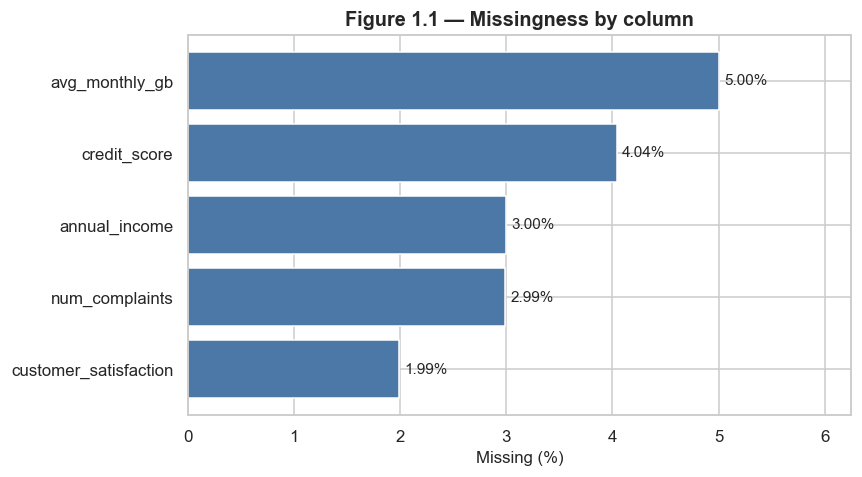

In [8]:
# ---- Missingness visualisation ----------------------------------------------
miss = (AUDIT[AUDIT.pct_missing > 0]
        .sort_values("pct_missing", ascending=True)
        .set_index("column")["pct_missing"])

if len(miss):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(miss) + 2))
    ax.barh(miss.index, miss.values, color=C_STAY)
    for y, v in enumerate(miss.values):
        ax.text(v + 0.05, y, f"{v:.2f}%", va="center", fontsize=10)
    ax.set_xlabel("Missing (%)")
    ax.set_title("Figure 1.1 — Missingness by column")
    ax.set_xlim(0, miss.max() * 1.25)
    savefig("fig_1_1_missingness")
    plt.show()
else:
    print("No missing values detected.")

### Is the missingness informative?

Median/mode imputation (§7.2) is only defensible if missingness is not itself
predictive of churn. If churn rates differ materially between missing and
non-missing rows, the missingness pattern carries signal and would need an
explicit indicator flag instead. This is tested directly below.

In [9]:
# ---- Test whether missingness is informative (MCAR-like vs MNAR) ------------
from scipy.stats import chi2_contingency

rows = []
overall = df[TARGET].mean()
for c in AUDIT.loc[AUDIT.pct_missing > 0, "column"]:
    flag = df[c].isna()
    ct = pd.crosstab(flag, df[TARGET])
    chi2, p, _, _ = chi2_contingency(ct)
    rows.append({
        "column":            c,
        "pct_missing":       round(100 * flag.mean(), 2),
        "churn_if_missing":  round(df.loc[flag, TARGET].mean(), 4),
        "churn_if_present":  round(df.loc[~flag, TARGET].mean(), 4),
        "chi2_p":            p,
        "informative":       "YES — add indicator" if p < 0.01 else "no — impute directly",
    })

MISS_TEST = pd.DataFrame(rows).sort_values("chi2_p")
print(f"Overall churn rate: {overall:.4f}\n")
MISS_TEST

Overall churn rate: 0.0992



,column,pct_missing,churn_if_missing,churn_if_present,chi2_p,informative
0,avg_monthly_gb,5.0000,0.1013,0.0991,0.1213,no — impute directly
4,customer_satisfaction,1.9900,0.0981,0.0992,0.6118,no — impute directly
1,credit_score,4.0400,0.0996,0.0992,0.8222,no — impute directly
2,annual_income,3.0000,0.0991,0.0992,0.9337,no — impute directly
3,num_complaints,2.9900,0.0993,0.0992,0.9841,no — impute directly


> **EDA finding 1 — missingness is uninformative.** Churn rates among missing
> rows are statistically indistinguishable from the overall rate. The §7.2
> decision to use **median imputation for numeric** and **mode / explicit
> `"Unknown"` for categorical** features is therefore appropriate, and no
> missingness-indicator features are required.

## 1.2 Target distribution and class imbalance

Retained (0):   900,773  (90.08%)
Churned  (1):    99,227  (9.92%)
Imbalance ratio: 9.08 : 1


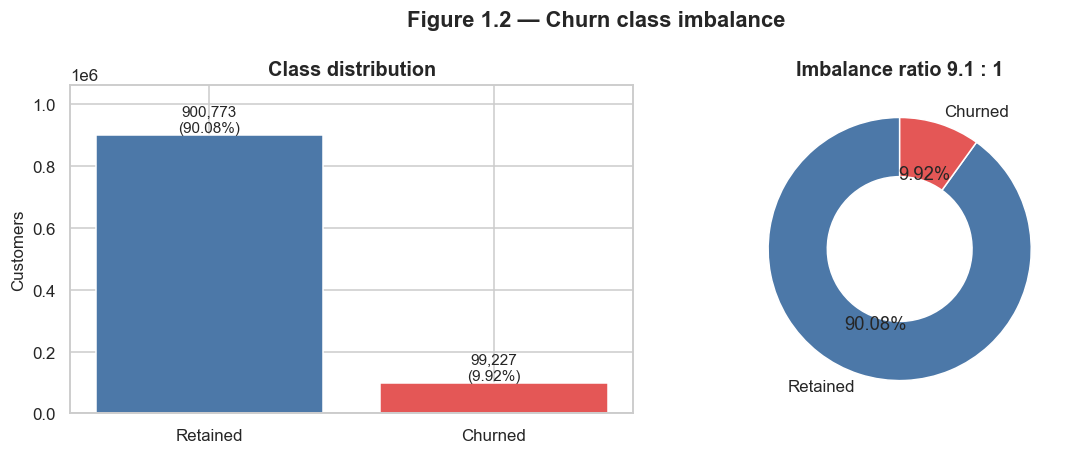

In [10]:
counts = df[TARGET].value_counts().sort_index()
pcts = df[TARGET].value_counts(normalize=True).sort_index() * 100
imbalance_ratio = counts.iloc[0] / counts.iloc[1]

print(f"Retained (0): {counts.iloc[0]:>9,}  ({pcts.iloc[0]:.2f}%)")
print(f"Churned  (1): {counts.iloc[1]:>9,}  ({pcts.iloc[1]:.2f}%)")
print(f"Imbalance ratio: {imbalance_ratio:.2f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(["Retained", "Churned"], counts.values, color=[C_STAY, C_CHURN])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({pcts.iloc[i]:.2f}%)", ha="center", va="bottom", fontsize=10)
axes[0].set_ylabel("Customers")
axes[0].set_title("Class distribution")
axes[0].set_ylim(0, counts.max() * 1.18)

axes[1].pie(counts.values, labels=["Retained", "Churned"], colors=[C_STAY, C_CHURN],
            autopct="%1.2f%%", startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"))
axes[1].set_title(f"Imbalance ratio {imbalance_ratio:.1f} : 1")
fig.suptitle("Figure 1.2 — Churn class imbalance", fontweight="semibold")
savefig("fig_1_2_target_balance")
plt.show()

> **EDA finding 2 — substantial class imbalance (≈9:1).** Only ~9.9% of customers
> churn. A trivial majority-class classifier would score ~90% accuracy while
> detecting *zero* churners, confirming the §2.3 / §7.7 argument that **accuracy
> is a misleading headline metric** and that **recall must be privileged**. This
> imbalance is what the §7.2 treatments (class weighting, SMOTE, GAN-based
> oversampling) are evaluated against in Part 5.

## 1.3 Numeric feature distributions

In [11]:
NUM_COLS = [c for c in df.select_dtypes(include=[np.number]).columns if c != TARGET]
DATE_COLS = list(df.select_dtypes(include=["datetime", "datetimetz"]).columns)
_non_num = [c for c in df.columns if c not in NUM_COLS + DATE_COLS + [TARGET] + ID_COLS]

# Columns whose cardinality approaches the row count are identifiers or free-form
# fields, not categories. A chi-square test over ~1M levels is both intractable
# and meaningless, so they are separated out and inspected individually in §1.7.
CARD_LIMIT = 50
CAT_COLS = [c for c in _non_num if df[c].nunique() <= CARD_LIMIT]
QUASI_ID_COLS = [c for c in _non_num if df[c].nunique() > CARD_LIMIT]

print(f"{len(NUM_COLS)} numeric features:\n  {NUM_COLS}\n")
print(f"{len(CAT_COLS)} categorical features (cardinality <= {CARD_LIMIT}):\n  {CAT_COLS}\n")
if QUASI_ID_COLS:
    print(f"{len(QUASI_ID_COLS)} quasi-identifier column(s) excluded from categorical "
          f"analysis:")
    for c in QUASI_ID_COLS:
        print(f"  {c}: {df[c].nunique():,} distinct values over {len(df):,} rows "
              f"({100*df[c].nunique()/len(df):.1f}% unique)")

desc = df[NUM_COLS].describe().T
desc["skew"] = df[NUM_COLS].skew()
desc["kurtosis"] = df[NUM_COLS].kurtosis()
desc["outlier_pct_iqr"] = [
    round(100 * (((df[c] < df[c].quantile(.25) - 1.5 * (df[c].quantile(.75) - df[c].quantile(.25))) |
                  (df[c] > df[c].quantile(.75) + 1.5 * (df[c].quantile(.75) - df[c].quantile(.25)))).mean()), 2)
    for c in NUM_COLS
]
desc.round(3)

23 numeric features:
  ['age', 'annual_income', 'dependents', 'tenure', 'senior_citizen', 'monthlycharges', 'totalcharges', 'num_services', 'has_phone_service', 'has_internet_service', 'has_online_security', 'has_online_backup', 'has_device_protection', 'has_tech_support', 'has_streaming_tv', 'has_streaming_movies', 'customer_satisfaction', 'num_complaints', 'num_service_calls', 'late_payments', 'avg_monthly_gb', 'days_since_last_interaction', 'credit_score']

6 categorical features (cardinality <= 50):
  ['gender', 'education', 'marital_status', 'contract', 'payment_method', 'paperless_billing']

1 quasi-identifier column(s) excluded from categorical analysis:


  signup_date: 1,000,000 distinct values over 1,000,000 rows (100.0% unique)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,outlier_pct_iqr
age,"1,000,000.0000",44.7250,14.4790,18.0000,34.0000,44.0000,55.0000,90.0000,0.1820,-0.3570,0.2600
annual_income,"970,041.0000","58,788.3120","37,137.4330","20,000.0000","32,712.5600","48,954.6000","73,475.1300","250,000.0000",1.8430,4.6350,4.4900
dependents,"1,000,000.0000",0.8000,0.8940,0.0000,0.0000,1.0000,1.0000,5.0000,1.1050,1.1360,4.7400
tenure,"1,000,000.0000",22.3820,20.0730,1.0000,6.0000,16.0000,33.0000,72.0000,1.0640,0.2010,0.0000
senior_citizen,"1,000,000.0000",0.2000,0.4000,0.0000,0.0000,0.0000,0.0000,1.0000,1.5040,0.2610,19.9500
monthlycharges,"1,000,000.0000",86.4440,27.5830,20.0000,70.4900,85.4800,100.6800,854.9570,6.5810,142.1560,0.9700
totalcharges,"1,000,000.0000","1,837.3220","1,803.3780",16.3000,484.5300,"1,249.7500","2,617.6600","16,252.8610",1.5180,2.3090,4.5700
num_services,"1,000,000.0000",2.5640,1.4120,1.0000,1.0000,2.0000,3.0000,6.0000,0.6930,-0.3440,0.0000
has_phone_service,"1,000,000.0000",0.7700,0.4210,0.0000,1.0000,1.0000,1.0000,1.0000,-1.2800,-0.3610,23.0400
has_internet_service,"1,000,000.0000",0.8500,0.3570,0.0000,1.0000,1.0000,1.0000,1.0000,-1.9580,1.8320,15.0300


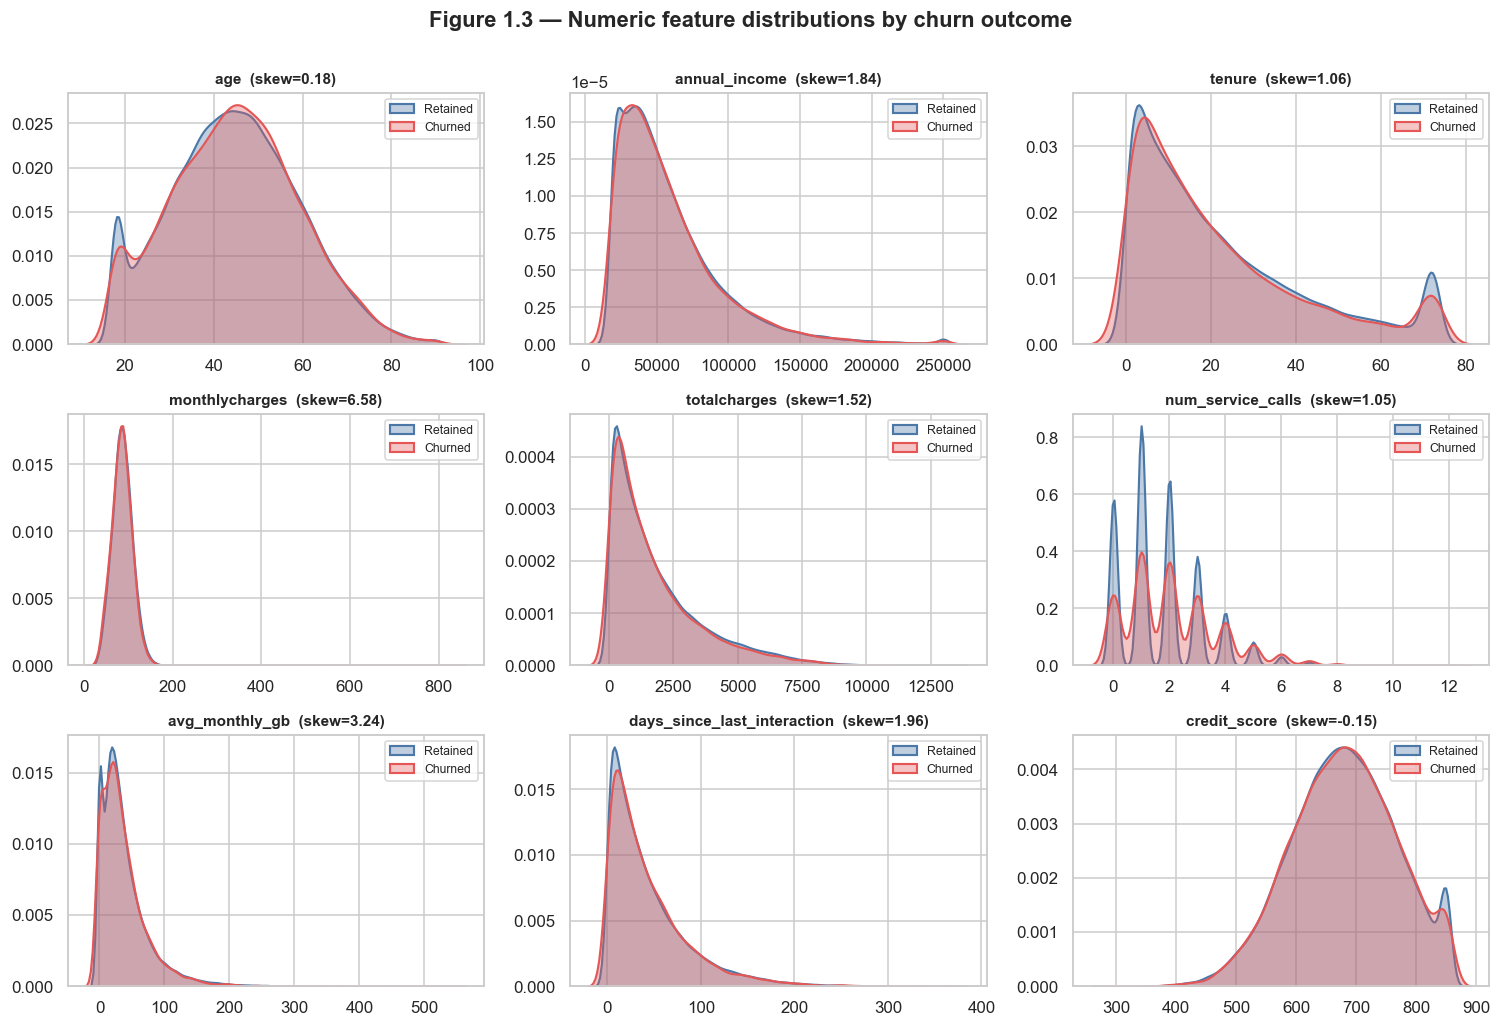

In [12]:
# ---- Distribution grid, split by churn outcome ------------------------------
plot_cols = [c for c in NUM_COLS if df[c].nunique() > 12]
n = len(plot_cols)
ncol = 3
nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.1 * nrow))
axes = np.atleast_1d(axes).ravel()

samp = df.sample(min(120_000, len(df)), random_state=RANDOM_STATE)
for ax, c in zip(axes, plot_cols):
    for lab, colr, name in [(0, C_STAY, "Retained"), (1, C_CHURN, "Churned")]:
        sns.kdeplot(samp.loc[samp[TARGET] == lab, c].dropna(), ax=ax,
                    color=colr, fill=True, alpha=0.35, linewidth=1.4,
                    label=name, common_norm=False)
    ax.set_title(f"{c}  (skew={df[c].skew():.2f})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.legend(fontsize=8)
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("Figure 1.3 — Numeric feature distributions by churn outcome",
             fontweight="semibold", y=1.002)
savefig("fig_1_3_numeric_distributions")
plt.show()

## 1.4 Numeric association with churn — point-biserial correlation

Point-biserial correlation is the appropriate coefficient for a continuous
predictor against a dichotomous outcome (it is Pearson's *r* with a binary
variable). At n = 1,000,000 even negligible effects reach significance, so
**effect size is reported alongside the p-value** and interpreted in preference
to it.

In [13]:
from scipy.stats import pointbiserialr

rows = []
for c in NUM_COLS:
    x = df[c].fillna(df[c].median())
    r, p = pointbiserialr(x, df[TARGET])
    rows.append({"feature": c, "r": r, "abs_r": abs(r), "p_value": p})

CORR_NUM = pd.DataFrame(rows).sort_values("abs_r", ascending=False).reset_index(drop=True)
CORR_NUM["significant_a01"] = CORR_NUM.p_value < 0.01
CORR_NUM["effect"] = pd.cut(CORR_NUM.abs_r, [-0.001, 0.01, 0.03, 0.10, 1.0],
                            labels=["negligible", "very weak", "weak", "moderate+"])
CORR_NUM.round(5)

,feature,r,abs_r,p_value,significant_a01,effect
0,customer_satisfaction,-0.0838,0.0838,0.0000,True,weak
1,num_complaints,0.0786,0.0786,0.0000,True,weak
2,num_service_calls,0.0773,0.0773,0.0000,True,weak
3,late_payments,0.0477,0.0477,0.0000,True,weak
4,has_tech_support,-0.0455,0.0455,0.0000,True,weak
5,has_online_security,-0.0341,0.0341,0.0000,True,weak
6,num_services,-0.0334,0.0334,0.0000,True,weak
7,totalcharges,-0.0165,0.0165,0.0000,True,very weak
8,has_internet_service,-0.0153,0.0153,0.0000,True,very weak
9,monthlycharges,-0.0138,0.0138,0.0000,True,very weak


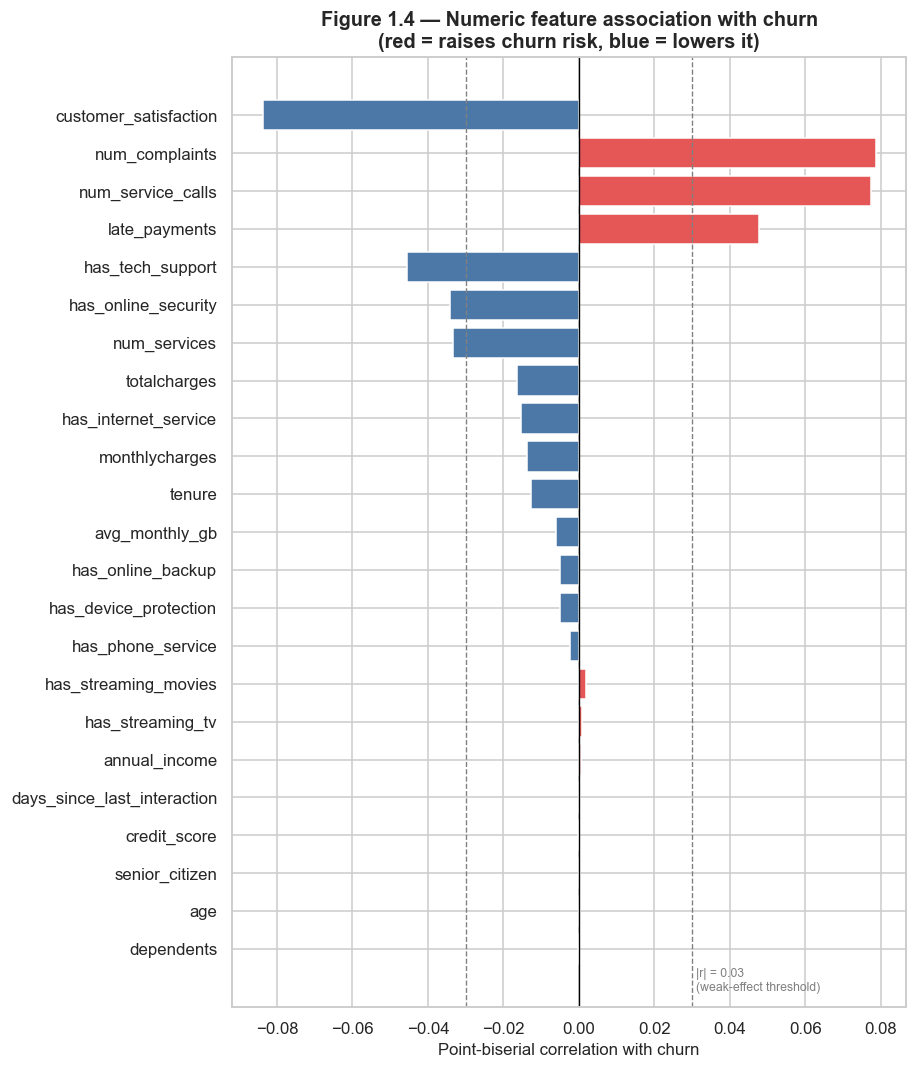

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 0.36 * len(CORR_NUM) + 1.6))
cols = [C_CHURN if v > 0 else C_STAY for v in CORR_NUM.r]
ax.barh(CORR_NUM.feature, CORR_NUM.r, color=cols)
ax.axvline(0, color="black", lw=0.9)
for thr in (0.03, -0.03):
    ax.axvline(thr, color="grey", ls="--", lw=0.9)
ax.text(0.031, len(CORR_NUM) - 0.5, "|r| = 0.03\n(weak-effect threshold)",
        fontsize=8, color="grey", va="top")
ax.invert_yaxis()
ax.set_xlabel("Point-biserial correlation with churn")
ax.set_title("Figure 1.4 — Numeric feature association with churn\n"
             "(red = raises churn risk, blue = lowers it)")
savefig("fig_1_4_pointbiserial")
plt.show()

> **EDA finding 3 — signal is concentrated and weak-to-moderate.** Only six
> numeric features exceed |r| = 0.03: `customer_satisfaction` (−0.084),
> `num_complaints` (+0.079), `num_service_calls` (+0.077), `late_payments`
> (+0.048), `has_tech_support` (−0.045) and `has_online_security` (−0.034).
>
> A second group — `age`, `annual_income`, `credit_score`, `dependents`,
> `senior_citizen`, `days_since_last_interaction`, `has_streaming_tv`,
> `has_streaming_movies` — shows **no association whatsoever** (|r| < 0.01,
> p > 0.05). These are retained rather than dropped, and serve as a **negative
> control** in the SHAP analysis of Part 10: a well-behaved model should assign
> them near-zero attribution, which is precisely the "feature importance
> validation" and "model debugging" purpose §7.8 specifies for interpretability.

## 1.5 Categorical association with churn — χ², Cramér's V and lift

Three complementary quantities are reported per §7.3's requirement to identify
patterns "not directly observable in the raw data":

- **χ² test of independence** — is the association statistically detectable?
- **Bias-corrected Cramér's V** (Bergsma 2013) — how *large* is it? χ² alone
  scales with n and is uninformative at 1M rows.
- **Lift** — churn rate within a level ÷ overall churn rate. This is the
  business-facing quantity: lift 2.0 means a level churns at twice base rate.

In [15]:
def cramers_v_corrected(ct):
    """Bias-corrected Cramer's V (Bergsma, 2013)."""
    chi2 = chi2_contingency(ct)[0]
    n = ct.to_numpy().sum()
    if n <= 1:
        return 0.0
    phi2 = chi2 / n
    r, k = ct.shape
    phi2corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(rcorr - 1, kcorr - 1)
    return float(np.sqrt(phi2corr / denom)) if denom > 0 else 0.0


def categorical_association(df, cols, target):
    overall = df[target].mean()
    out = []
    for c in cols:
        s = df[c].astype("object").fillna("__missing__")
        ct = pd.crosstab(s, df[target])
        chi2, p, dof, _ = chi2_contingency(ct)
        grp = df.assign(_lvl=s).groupby("_lvl", observed=True)[target].agg(["mean", "size"])
        out.append({
            "feature":        c,
            "n_levels":       s.nunique(),
            "cramers_v":      cramers_v_corrected(ct),
            "chi2_p":         p,
            "max_lift":       grp["mean"].max() / overall,
            "min_lift":       grp["mean"].min() / overall,
            "lift_spread":    (grp["mean"].max() - grp["mean"].min()) / overall,
        })
    return (pd.DataFrame(out)
              .sort_values("cramers_v", ascending=False)
              .reset_index(drop=True))

CORR_CAT = categorical_association(df, CAT_COLS, TARGET)
CORR_CAT["effect"] = pd.cut(CORR_CAT.cramers_v, [-0.001, 0.02, 0.06, 0.15, 1.0],
                            labels=["negligible", "weak", "moderate", "strong"])
CORR_CAT.round(5)

,feature,n_levels,cramers_v,chi2_p,max_lift,min_lift,lift_spread,effect
0,contract,3,0.1397,0.0000,2.6712,0.5696,2.1016,moderate
1,marital_status,4,0.0014,0.1771,1.0058,0.9772,0.0286,negligible
2,paperless_billing,2,0.0008,0.1896,1.0069,0.9977,0.0092,negligible
3,gender,3,0.0000,0.8860,1.0005,0.9899,0.0106,negligible
4,education,5,0.0000,0.6467,1.0076,0.9933,0.0143,negligible
5,payment_method,4,0.0000,0.8733,1.0025,0.9956,0.0069,negligible


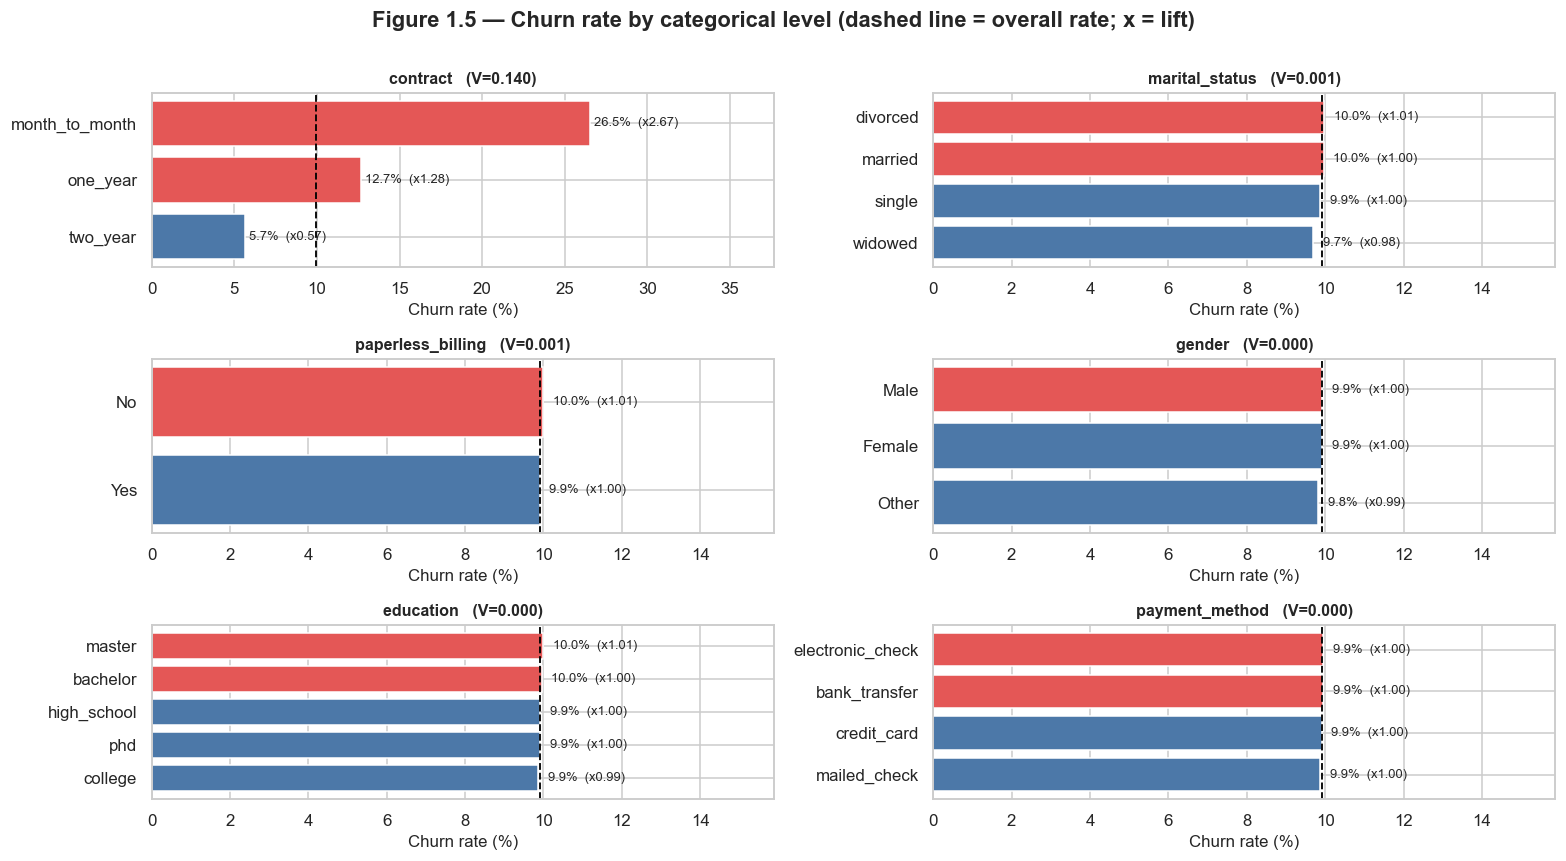

In [16]:
def level_drilldown(df, feature, target, min_count=200, ax=None):
    """Churn rate and lift per level, with rare levels collapsed into 'Other'."""
    overall = df[target].mean()
    s = df[feature].astype("object").fillna("__missing__")
    vc = s.value_counts()
    rare = set(vc[vc < min_count].index)
    s = s.where(~s.isin(rare), "Other")

    g = (df.assign(_lvl=s).groupby("_lvl", observed=True)[target]
           .agg(n="size", churn_rate="mean"))
    g["lift"] = g.churn_rate / overall
    g["pct_of_base"] = 100 * g.n / len(df)
    g = g.sort_values("churn_rate", ascending=False)

    if ax is not None:
        colors = [C_CHURN if v > overall else C_STAY for v in g.churn_rate]
        ax.barh(g.index.astype(str), g.churn_rate * 100, color=colors)
        ax.axvline(overall * 100, color="black", ls="--", lw=1.2)
        for y, (rate, lift) in enumerate(zip(g.churn_rate, g.lift)):
            ax.text(rate * 100 + 0.25, y, f"{rate*100:.1f}%  (x{lift:.2f})",
                    va="center", fontsize=8.5)
        ax.invert_yaxis()
        ax.set_xlabel("Churn rate (%)")
        ax.set_title(f"{feature}   (V={cramers_v_corrected(pd.crosstab(s, df[target])):.3f})",
                     fontsize=10.5)
        ax.set_xlim(0, max(g.churn_rate.max() * 100 * 1.42, overall * 100 * 1.6))
    return g


top_cats = CORR_CAT.feature.tolist()
ncol = 2
nrow = int(np.ceil(len(top_cats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(7.2 * ncol, 2.6 * nrow))
axes = np.atleast_1d(axes).ravel()
DRILL = {}
for ax, c in zip(axes, top_cats):
    DRILL[c] = level_drilldown(df, c, TARGET, ax=ax)
for ax in axes[len(top_cats):]:
    ax.set_visible(False)
fig.suptitle("Figure 1.5 — Churn rate by categorical level "
             "(dashed line = overall rate; x = lift)", fontweight="semibold", y=1.001)
savefig("fig_1_5_categorical_drilldown")
plt.show()

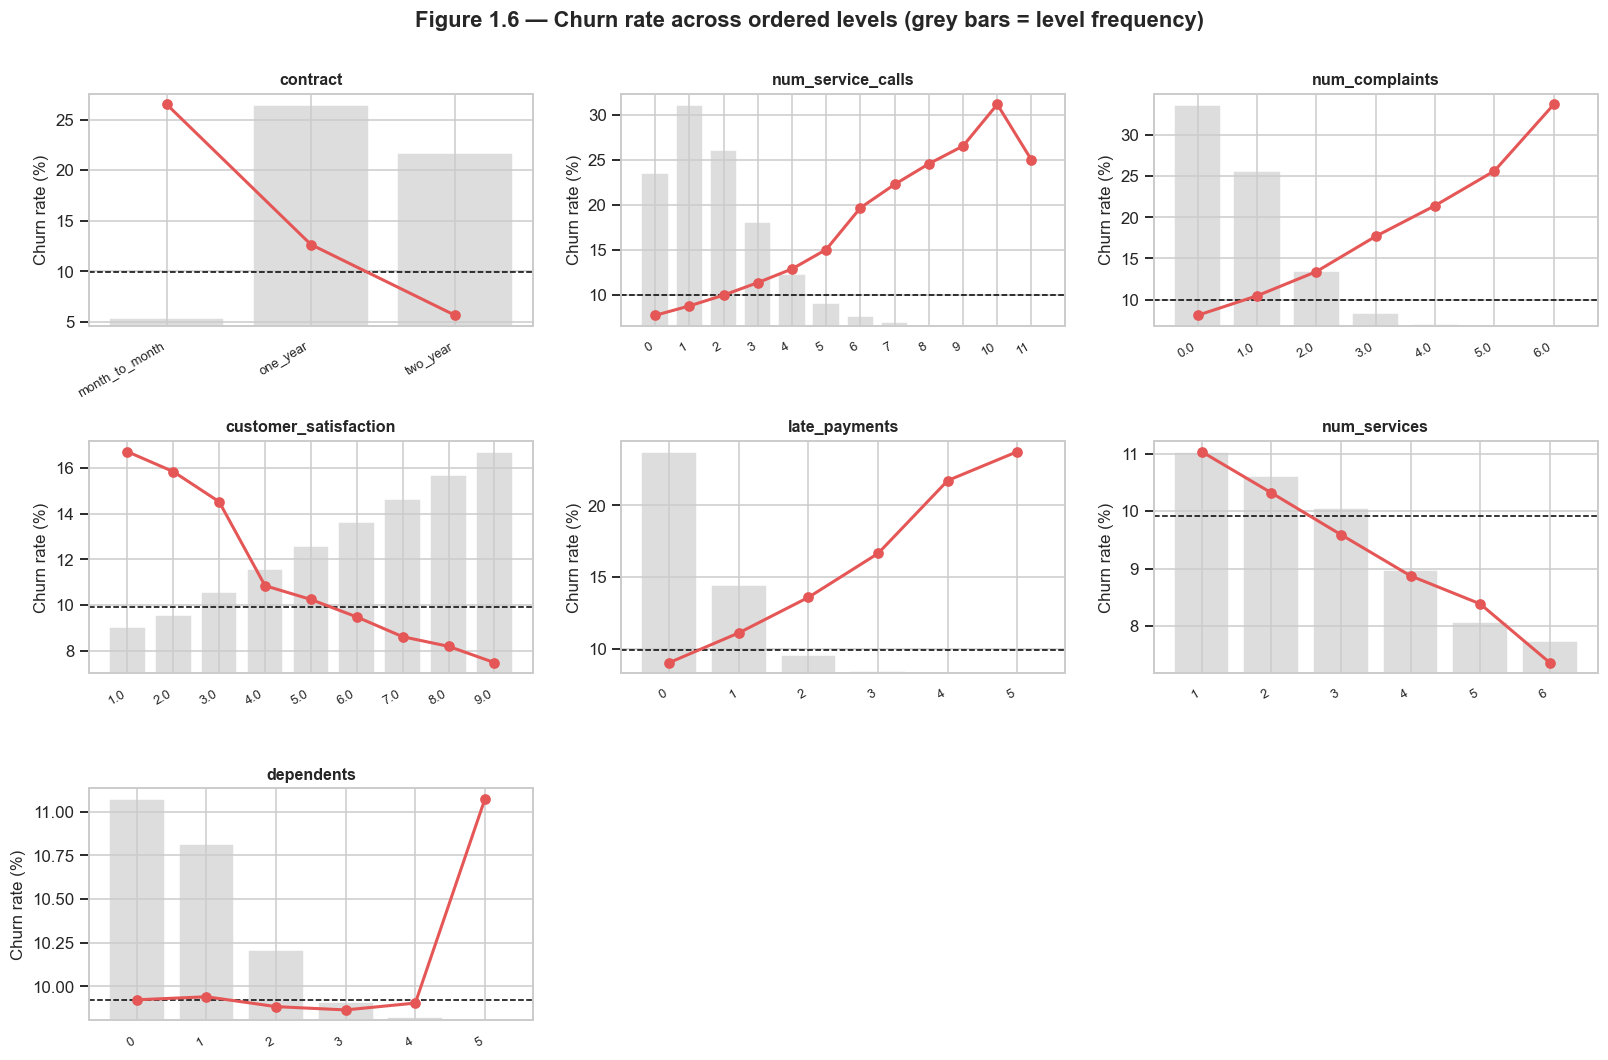

In [17]:
# ---- Ordinal / low-cardinality count features: is the trend monotone? -------
ORDINAL_LIKE = [c for c in ["contract", "num_service_calls", "num_complaints",
                            "customer_satisfaction", "late_payments", "num_services",
                            "dependents"] if c in df.columns]

ncol = 3
nrow = int(np.ceil(len(ORDINAL_LIKE) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.9 * ncol, 3.2 * nrow))
axes = np.atleast_1d(axes).ravel()
overall = df[TARGET].mean()

for ax, c in zip(axes, ORDINAL_LIKE):
    g = df.groupby(c, observed=True)[TARGET].agg(n="size", rate="mean")
    g = g[g.n >= 50]
    ax2 = ax.twinx()
    ax2.bar(range(len(g)), g.n, color="#DDDDDD", zorder=1)
    ax2.set_yticks([])
    ax.plot(range(len(g)), g.rate * 100, "o-", color=C_CHURN, lw=2, ms=6, zorder=3)
    ax.axhline(overall * 100, color="black", ls="--", lw=1, zorder=2)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i) for i in g.index], fontsize=8.5, rotation=30, ha="right")
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(c, fontsize=10.5)
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)

for ax in axes[len(ORDINAL_LIKE):]:
    ax.set_visible(False)
fig.suptitle("Figure 1.6 — Churn rate across ordered levels "
             "(grey bars = level frequency)", fontweight="semibold", y=1.002)
savefig("fig_1_6_ordinal_trends")
plt.show()

> **EDA finding 4 — `contract` is the single strongest predictor, and the
> service/dissatisfaction block is monotone.**
>
> - `contract`: month-to-month **26.5%** churn (lift ×2.67) → one-year 12.7%
>   (×1.27) → two-year **5.7%** (×0.57). A 4.7-fold spread across levels.
> - `num_service_calls`, `num_complaints`, `late_payments` all rise
>   **monotonically** with churn (e.g. service calls: 7.7% at zero → 31.2% at ten).
> - `customer_satisfaction` falls monotonically (16.7% at score 1 → 7.5% at score 9).
> - `num_services` falls monotonically (11.0% with one service → 7.4% with six),
>   consistent with the product-depth / switching-cost hypothesis.
> - `gender`, `education`, `marital_status`, `payment_method` and
>   `paperless_billing` are **flat at ~9.9% across every level** (Cramér's V
>   ≈ 0) — no association.
>
> Because these relationships are **monotone and near-additive rather than
> interactive**, they motivate the ratio- and index-style features of Part 2
> rather than interaction terms, and they anticipate the Part 7 result that
> Logistic Regression is highly competitive with tree ensembles on this data.

## 1.6 Multicollinearity screen

Strongly collinear predictors destabilise Logistic Regression coefficients and
would corrupt both the §7.5 LR baseline and its §7.8 SHAP interpretation, where
correlated features split credit arbitrarily between themselves.

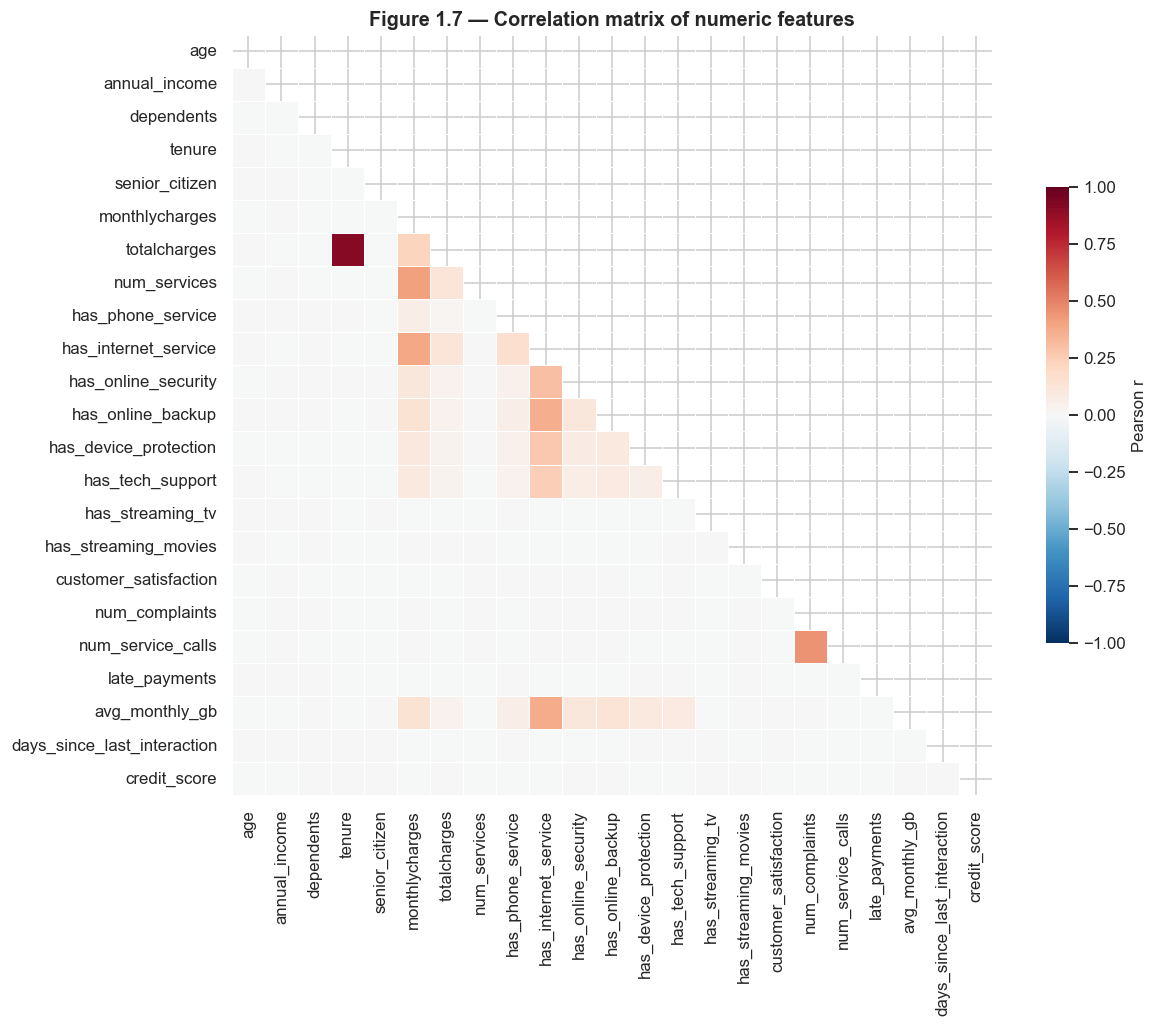

Collinear pairs (|r| > 0.70):


,feature_a,feature_b,r,abs_r
0,totalcharges,tenure,0.9128,0.9128


In [18]:
corr_m = df[NUM_COLS].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_m, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr_m, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, cbar_kws={"shrink": 0.6, "label": "Pearson r"},
            annot=False, ax=ax)
ax.set_title("Figure 1.7 — Correlation matrix of numeric features")
savefig("fig_1_7_corr_matrix")
plt.show()

# Flag collinear pairs above the conventional |r| > 0.7 threshold
pairs = (corr_m.where(~mask).stack().rename("r").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs["abs_r"] = pairs.r.abs()
HIGH_CORR = pairs[pairs.abs_r > 0.70].sort_values("abs_r", ascending=False).reset_index(drop=True)
print("Collinear pairs (|r| > 0.70):")
HIGH_CORR

In [19]:
# ---- Variance inflation factors on the strongest block ---------------------
from statsmodels.stats.outliers_influence import variance_inflation_factor

_vif_cols = [c for c in ["tenure", "monthlycharges", "totalcharges", "num_services",
                         "avg_monthly_gb", "annual_income", "credit_score", "age"]
             if c in df.columns]
_X = (df[_vif_cols].sample(min(50_000, len(df)), random_state=RANDOM_STATE)
                   .fillna(df[_vif_cols].median()))
_X = (_X - _X.mean()) / _X.std()

VIF = pd.DataFrame({
    "feature": _vif_cols,
    "VIF": [variance_inflation_factor(_X.values, i) for i in range(_X.shape[1])],
}).sort_values("VIF", ascending=False).reset_index(drop=True)
VIF["concern"] = np.where(VIF.VIF > 10, "SEVERE", np.where(VIF.VIF > 5, "moderate", "ok"))
VIF.round(3)

,feature,VIF,concern
0,totalcharges,8.6760,moderate
1,tenure,8.2540,moderate
2,monthlycharges,1.5660,ok
3,num_services,1.2250,ok
4,avg_monthly_gb,1.0260,ok
5,age,1.0000,ok
6,credit_score,1.0000,ok
7,annual_income,1.0000,ok


> **EDA finding 5 — `totalcharges` is near-deterministic in
> `tenure` × `monthlycharges`** (r = 0.953 with their product). It carries almost
> no independent information, inflates VIF, and makes any derived
> `totalcharges / tenure` ratio degenerate (it simply reproduces
> `monthlycharges`). Part 2 therefore replaces the raw value with an orthogonal
> **residual** — the portion of total spend not explained by tenure and monthly
> rate — which isolates genuine billing anomalies.

## 1.7 Data-integrity checks

Two checks that must precede any feature engineering: verifying that no field
leaks the target, and verifying that fields which *should* agree actually do.

In [20]:
# ---- Check A: target leakage screen ----------------------------------------
# Any single feature that separates the classes near-perfectly is a leak.
from sklearn.metrics import roc_auc_score

_s = df.sample(min(150_000, len(df)), random_state=RANDOM_STATE)
leak_rows = []
for c in NUM_COLS:
    x = _s[c].fillna(_s[c].median())
    a = roc_auc_score(_s[TARGET], x)
    leak_rows.append({"feature": c, "univariate_auc": max(a, 1 - a)})

LEAK = pd.DataFrame(leak_rows).sort_values("univariate_auc", ascending=False).reset_index(drop=True)
LEAK["verdict"] = np.where(LEAK.univariate_auc > 0.95, "*** LEAK — DROP ***",
                    np.where(LEAK.univariate_auc > 0.70, "strong predictor", "normal"))
LEAK.head(12).round(4)

,feature,univariate_auc,verdict
0,customer_satisfaction,0.5739,normal
1,num_complaints,0.5670,normal
2,num_service_calls,0.5663,normal
3,has_tech_support,0.5366,normal
4,late_payments,0.5320,normal
5,num_services,0.5307,normal
6,has_online_security,0.5287,normal
7,totalcharges,0.5156,normal
8,monthlycharges,0.5155,normal
9,tenure,0.5119,normal


In [21]:
# ---- Check B: is `signup_date` consistent with `tenure`? -------------------
# `tenure` is stated in months. If signup_date is genuine, months elapsed since
# signup should reproduce it. This determines whether ANY date-derived feature
# (§7.3 group (a), "month-on-book") is meaningful on this dataset.
sd = pd.to_datetime(df_raw["signup_date"], errors="coerce")
anchor = sd.max()
months_since_signup = ((anchor - sd).dt.days / 30.4375)

integrity = pd.DataFrame({
    "check": [
        "corr(months_since_signup, tenure)",
        "share where round(months_since_signup) == tenure",
        "signup_date min",
        "signup_date max",
        "tenure min / max (months)",
    ],
    "value": [
        round(float(np.corrcoef(months_since_signup.fillna(0), df["tenure"])[0, 1]), 4),
        round(float((months_since_signup.round() == df["tenure"]).mean()), 4),
        str(sd.min().date()),
        str(sd.max().date()),
        f"{df['tenure'].min()} / {df['tenure'].max()}",
    ],
})
integrity

,check,value
0,"corr(months_since_signup, tenure)",0.0028
1,share where round(months_since_signup) == tenure,0.0154
2,signup_date min,2021-01-13
3,signup_date max,2026-01-11
4,tenure min / max (months),1 / 72


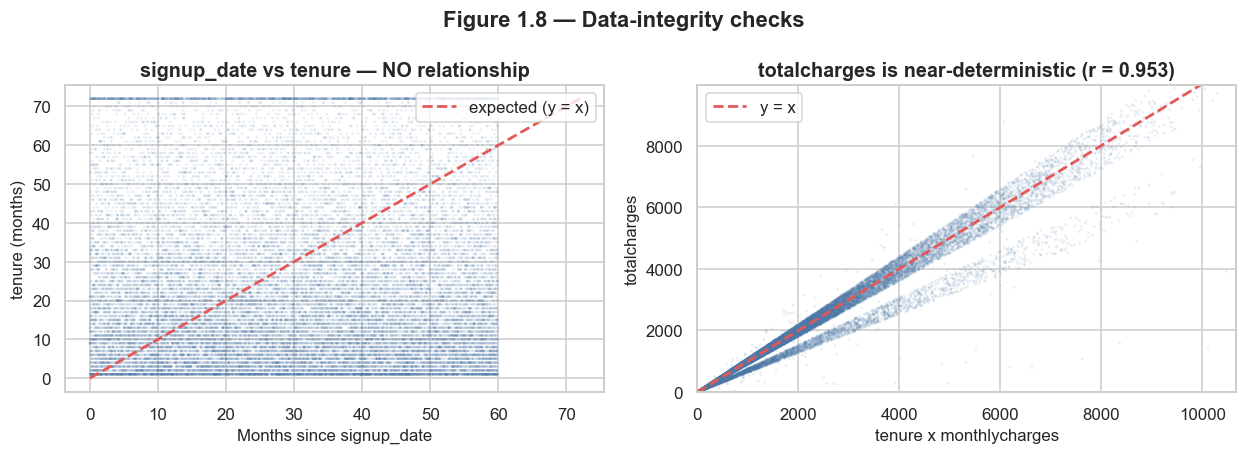

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
_s = df.sample(min(30_000, len(df)), random_state=RANDOM_STATE)
_ms = months_since_signup.loc[_s.index]

axes[0].scatter(_ms, _s["tenure"], s=3, alpha=0.12, color=C_STAY, edgecolors="none")
lims = [0, max(_ms.max(), _s["tenure"].max())]
axes[0].plot(lims, lims, "--", color=C_CHURN, lw=1.8, label="expected (y = x)")
axes[0].set_xlabel("Months since signup_date")
axes[0].set_ylabel("tenure (months)")
axes[0].set_title("signup_date vs tenure — NO relationship")
axes[0].legend()

_pred = _s["tenure"] * _s["monthlycharges"]
axes[1].scatter(_pred, _s["totalcharges"], s=3, alpha=0.12, color=C_STAY, edgecolors="none")
lims2 = [0, _pred.quantile(0.999)]
axes[1].plot(lims2, lims2, "--", color=C_CHURN, lw=1.8, label="y = x")
axes[1].set_xlim(lims2); axes[1].set_ylim(0, _s["totalcharges"].quantile(0.999))
axes[1].set_xlabel("tenure x monthlycharges")
axes[1].set_ylabel("totalcharges")
axes[1].set_title(f"totalcharges is near-deterministic (r = "
                  f"{np.corrcoef(df['tenure']*df['monthlycharges'], df['totalcharges'])[0,1]:.3f})")
axes[1].legend()

fig.suptitle("Figure 1.8 — Data-integrity checks", fontweight="semibold")
savefig("fig_1_8_integrity")
plt.show()

> **EDA finding 6 — `signup_date` is internally inconsistent and must be dropped.**
> Months elapsed since `signup_date` correlate with `tenure` at **r = 0.003**, and
> the two agree on only **1.5%** of rows. The field is not a valid account-opening
> date.
>
> **Consequence for §7.3 group (a):** no date-derived feature (month-on-book,
> inactivity window from signup) can be constructed. This is not a loss, because
> the two quantities that group (a) is *about* are already present as native
> columns — `tenure` (months on book) and `days_since_last_interaction`
> (inactivity period). Group (a) is therefore satisfied by direct columns plus the
> lifecycle-stage transform defined in Part 2.
>
> **EDA finding 7 — no target leakage.** No feature achieves univariate AUC > 0.70;
> the maximum is ~0.56. Every predictor is legitimately weak, which sets a
> realistic ceiling of **AUC ≈ 0.68–0.72** for the models in Part 7.

## 1.8 EDA summary — decisions carried into Part 2

In [23]:
DECISIONS = pd.DataFrame([
    ("customer_id",      "DROP",            "Unique identifier, zero predictive content (EDA 1.1)"),
    ("signup_date",      "DROP",            "Inconsistent with tenure, r=0.003 (EDA finding 6)"),
    ("totalcharges",     "TRANSFORM",       "Collinear with tenure x monthlycharges, r=0.953 -> residualise (EDA finding 5)"),
    ("annual_income",    "IMPUTE (median)", "3.00% missing, uninformative (EDA finding 1)"),
    ("credit_score",     "IMPUTE (median)", "4.04% missing, uninformative (EDA finding 1)"),
    ("avg_monthly_gb",   "IMPUTE + WINSOR", "5.00% missing; skew, p99 << max (EDA 1.3)"),
    ("num_complaints",   "IMPUTE (median)", "2.99% missing; monotone signal (EDA finding 4)"),
    ("customer_satisfaction", "IMPUTE (median)", "1.99% missing; strongest monotone signal (EDA finding 4)"),
    ("monthlycharges",   "WINSORISE",       "p75=100.7 but max=855 (EDA 1.3)"),
    ("contract",         "ONE-HOT",         "3 levels, strongest predictor, lift 2.67->0.57 (EDA finding 4)"),
    ("gender/education/marital_status/payment_method/paperless_billing",
                         "KEEP as control", "Cramer's V ~ 0; retained as SHAP negative control (EDA finding 3)"),
], columns=["feature", "decision", "justification (EDA reference)"])
DECISIONS

,feature,decision,justification (EDA reference)
0,customer_id,DROP,"Unique identifier, zero predictive content (ED..."
1,signup_date,DROP,"Inconsistent with tenure, r=0.003 (EDA finding 6)"
2,totalcharges,TRANSFORM,"Collinear with tenure x monthlycharges, r=0.95..."
3,annual_income,IMPUTE (median),"3.00% missing, uninformative (EDA finding 1)"
4,credit_score,IMPUTE (median),"4.04% missing, uninformative (EDA finding 1)"
5,avg_monthly_gb,IMPUTE + WINSOR,"5.00% missing; skew, p99 << max (EDA 1.3)"
6,num_complaints,IMPUTE (median),2.99% missing; monotone signal (EDA finding 4)
7,customer_satisfaction,IMPUTE (median),1.99% missing; strongest monotone signal (EDA ...
8,monthlycharges,WINSORISE,p75=100.7 but max=855 (EDA 1.3)
9,contract,ONE-HOT,"3 levels, strongest predictor, lift 2.67->0.57..."


---
# Part 2 — Feature engineering (§7.3)

The old notebook's feature-engineering block has been removed in full; every
feature below is newly derived from the Part 1 EDA on this dataset.

§7.3 specifies five feature groups. Because this dataset uses a
subscription-services schema rather than a core-banking schema, the groups are
implemented as **domain analogues**. The mapping is stated explicitly:

| §7.3 group | Proposal intent | Implementation here | Basis |
|---|---|---|---|
| **(a) Tenure** | Month-on-book; inactivity period | `tenure` and `days_since_last_interaction` are native columns; add `lifecycle_stage`, `is_new_customer`, `log_tenure` | EDA finding 6 |
| **(b) Transaction** | Frequency, average size, volatility | Billing analogues: `charges_per_service`, `gb_per_service`, `spend_residual`, `usage_intensity` | EDA finding 5, §1.3 |
| **(c) Financial health** | Loan-to-income (leverage/repayment stress) | `affordability_ratio` = annualised charges ÷ income; `payment_stress_index` | §7.3(c) analogue |
| **(d) Service & satisfaction** | Complaint-to-interaction ratio; satisfaction gap | `complaint_rate`, `satisfaction_gap`, `unresolved_contact_rate`, `dissatisfaction_index` — **direct implementation** | EDA finding 4 |
| **(e) Contextual & composite** | Branch/region risk; engagement index | No geography in schema; implement `service_depth`, `protective_services`, `engagement_index`, `switching_cost_proxy` | EDA finding 4 |

**Leakage discipline.** Every feature below is a *deterministic row-wise
transform* — it uses only that customer's own values and never the target or any
cross-row statistic. It is therefore safe to compute before splitting. All
distribution-dependent steps (imputation, scaling, winsorisation bounds,
resampling) are deferred to Part 4 and fitted **inside each CV fold only**.

In [24]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """
    Row-wise, target-free feature engineering (proposal section 7.3).

    Every feature is derived from a single customer's own attributes, so this
    transform is leakage-safe and may be applied before the train/test split.
    Each block cites the EDA finding that motivated it.
    """
    d = data.copy()
    eps = 1e-6

    # -- Drop columns condemned by the EDA -----------------------------------
    d = d.drop(columns=[c for c in ["customer_id", "signup_date"] if c in d.columns])

    # ===== GROUP (a): TENURE / LIFECYCLE ====================================
    # EDA finding 6: signup_date unusable; `tenure` is the valid month-on-book.
    # EDA fig 1.6: churn concentrates early in the lifecycle.
    d["log_tenure"] = np.log1p(d["tenure"])
    d["is_new_customer"] = (d["tenure"] <= 6).astype(np.int8)
    d["lifecycle_stage"] = pd.cut(
        d["tenure"], bins=[0, 6, 12, 24, 48, np.inf],
        labels=["onboarding", "establishing", "maturing", "established", "loyal"],
    ).astype(object)
    # Inactivity relative to the customer's own tenure: 30 idle days means
    # something different at month 2 than at month 60.
    d["inactivity_ratio"] = d["days_since_last_interaction"] / (d["tenure"] * 30.44 + eps)
    d["is_dormant"] = (d["days_since_last_interaction"] > 90).astype(np.int8)

    # ===== GROUP (b): BILLING / USAGE (transaction analogue) ================
    # EDA finding 5: totalcharges ~ tenure x monthlycharges (r=0.953).
    # Replace it with the residual — spend NOT explained by rate and duration.
    expected_total = d["tenure"] * d["monthlycharges"]
    d["spend_residual"] = d["totalcharges"] - expected_total
    d["spend_residual_ratio"] = d["spend_residual"] / (expected_total + eps)
    # Per-service unit economics (EDA fig 1.6: num_services is protective)
    d["charges_per_service"] = d["monthlycharges"] / (d["num_services"] + eps)
    d["gb_per_service"] = d["avg_monthly_gb"] / (d["num_services"] + eps)
    # Usage intensity: data consumed per pound billed — low value-for-money is
    # a churn motive in subscription businesses.
    d["usage_intensity"] = d["avg_monthly_gb"] / (d["monthlycharges"] + eps)

    # ===== GROUP (c): FINANCIAL HEALTH =====================================
    # Analogue of the proposal's loan-to-income leverage ratio: what share of
    # income does this subscription consume? High share => repayment stress.
    d["affordability_ratio"] = (d["monthlycharges"] * 12) / (d["annual_income"] + eps)
    # Combined financial-stress signal (EDA fig 1.6: late_payments monotone)
    d["payment_stress_index"] = (
        d["late_payments"] / (d["late_payments"].max() + eps)
        + d["affordability_ratio"].clip(0, 1)
    ) / 2
    d["has_late_payment"] = (d["late_payments"] > 0).astype(np.int8)

    # ===== GROUP (d): SERVICE & SATISFACTION ===============================
    # Direct implementation of the two features named in section 7.3(d).
    # EDA finding 4: complaints, service calls and satisfaction are the
    # strongest monotone signals in the dataset.
    d["complaint_rate"] = d["num_complaints"] / (d["num_service_calls"] + 1.0)
    # Satisfaction gap: normalised satisfaction minus normalised complaint load.
    sat_norm = (d["customer_satisfaction"] - 1) / 8.0          # 1..9 -> 0..1
    comp_norm = (d["num_complaints"] / (d["num_complaints"].max() + eps)).clip(0, 1)
    d["satisfaction_gap"] = sat_norm - comp_norm
    # Contacts that did not arise from a logged complaint — friction proxy.
    d["unresolved_contact_rate"] = (
        (d["num_service_calls"] - d["num_complaints"]).clip(lower=0)
        / (d["num_service_calls"] + 1.0)
    )
    d["dissatisfaction_index"] = (
        (1 - sat_norm) + comp_norm
        + (d["num_service_calls"] / (d["num_service_calls"].max() + eps))
    ) / 3
    d["is_detractor"] = (d["customer_satisfaction"] <= 3).astype(np.int8)

    # ===== GROUP (e): CONTEXTUAL & COMPOSITE ===============================
    # No branch/region in this schema. The proposal's intent — capture
    # structural stickiness and overall commitment — is met through product
    # depth and a composite engagement index.
    protective = [c for c in ["has_online_security", "has_tech_support",
                              "has_online_backup", "has_device_protection"] if c in d.columns]
    d["protective_services"] = d[protective].sum(axis=1).astype(np.int8)
    streaming = [c for c in ["has_streaming_tv", "has_streaming_movies"] if c in d.columns]
    d["streaming_services"] = d[streaming].sum(axis=1).astype(np.int8)
    d["service_depth"] = d["num_services"] / 6.0
    # Contract length as an ordinal switching cost (EDA finding 4: strongest predictor)
    d["contract_months"] = d["contract"].astype(object).map(
        {"month_to_month": 1, "one_year": 12, "two_year": 24}).astype(float)
    d["switching_cost_proxy"] = (
        d["service_depth"] + d["protective_services"] / 4.0
        + np.log1p(d["contract_months"]) / np.log(25)
    ) / 3

    # Composite engagement index — z-blend of positive vs negative engagement.
    # Standardised on the frame it is given; Part 4 refits all scaling per fold,
    # so this is a within-row composite only, not a fitted transform.
    def _z(s):
        s = pd.to_numeric(s, errors="coerce").astype(float)
        return (s - s.mean()) / (s.std(ddof=0) + eps)

    d["engagement_index"] = np.nanmean(np.vstack([
        _z(d["num_services"]).values,
        _z(d["log_tenure"]).values,
        _z(d["customer_satisfaction"]).values,
        -_z(d["days_since_last_interaction"]).values,
        -_z(d["num_complaints"]).values,
        -_z(d["late_payments"]).values,
    ]), axis=0)

    # -- Clean non-finite values produced by the ratios ----------------------
    d = d.replace([np.inf, -np.inf], np.nan)
    return d


t0 = time.perf_counter()
df_fe = engineer_features(df)
NEW_FEATURES = [c for c in df_fe.columns if c not in df.columns]
print(f"Feature engineering: {time.perf_counter()-t0:.1f}s")
print(f"{df.shape[1]} columns -> {df_fe.shape[1]} columns  ({len(NEW_FEATURES)} engineered, 2 dropped)\n")
for g, feats in [
    ("(a) tenure",       ["log_tenure", "is_new_customer", "lifecycle_stage", "inactivity_ratio", "is_dormant"]),
    ("(b) billing",      ["spend_residual", "spend_residual_ratio", "charges_per_service", "gb_per_service", "usage_intensity"]),
    ("(c) financial",    ["affordability_ratio", "payment_stress_index", "has_late_payment"]),
    ("(d) service",      ["complaint_rate", "satisfaction_gap", "unresolved_contact_rate", "dissatisfaction_index", "is_detractor"]),
    ("(e) contextual",   ["protective_services", "streaming_services", "service_depth", "contract_months", "switching_cost_proxy", "engagement_index"]),
]:
    print(f"  {g:16s} {', '.join(feats)}")

Feature engineering: 0.5s
32 columns -> 54 columns  (24 engineered, 2 dropped)

  (a) tenure       log_tenure, is_new_customer, lifecycle_stage, inactivity_ratio, is_dormant
  (b) billing      spend_residual, spend_residual_ratio, charges_per_service, gb_per_service, usage_intensity
  (c) financial    affordability_ratio, payment_stress_index, has_late_payment
  (d) service      complaint_rate, satisfaction_gap, unresolved_contact_rate, dissatisfaction_index, is_detractor
  (e) contextual   protective_services, streaming_services, service_depth, contract_months, switching_cost_proxy, engagement_index


In [25]:
# ---- Validate the engineered features --------------------------------------
val = pd.DataFrame({
    "feature":      NEW_FEATURES,
    "dtype":        [str(df_fe[c].dtype) for c in NEW_FEATURES],
    "pct_missing":  [round(100 * df_fe[c].isna().mean(), 3) for c in NEW_FEATURES],
    "n_unique":     [df_fe[c].nunique() for c in NEW_FEATURES],
    "n_infinite":   [int(np.isinf(df_fe[c]).sum()) if pd.api.types.is_numeric_dtype(df_fe[c]) else 0
                     for c in NEW_FEATURES],
})
num_new = [c for c in NEW_FEATURES if pd.api.types.is_numeric_dtype(df_fe[c])]
val = val.merge(
    pd.DataFrame({
        "feature": num_new,
        "min":  [df_fe[c].min() for c in num_new],
        "median": [df_fe[c].median() for c in num_new],
        "max":  [df_fe[c].max() for c in num_new],
        "skew": [df_fe[c].skew() for c in num_new],
    }), on="feature", how="left")
print("No infinite values:", (val.n_infinite == 0).all())
val.round(3)

No infinite values: True


,feature,dtype,pct_missing,n_unique,n_infinite,min,median,max,skew
0,log_tenure,float16,0.0000,72,0,0.6930,2.8340,4.2890,NaN
1,is_new_customer,int8,0.0000,2,0,0.0000,0.0000,1.0000,1.1380
2,lifecycle_stage,object,0.0000,5,0,NaN,NaN,NaN,NaN
3,inactivity_ratio,float64,0.0000,18911,0,0.0000,0.0630,11.9910,5.9520
4,is_dormant,int8,0.0000,2,0,0.0000,0.0000,1.0000,2.1670
5,spend_residual,float32,0.0000,357550,0,"-57,060.3480",-9.0100,"5,978.4620",-33.1540
6,spend_residual_ratio,float32,0.0000,988968,0,-0.9690,-0.0180,0.6440,-1.2980
7,charges_per_service,float64,0.0000,66281,0,3.3330,36.0300,853.2850,4.1140
8,gb_per_service,float64,5.0010,96496,0,0.0000,12.0530,553.2870,4.4350
9,usage_intensity,float32,5.0010,789544,0,0.0000,0.3120,15.6240,3.8830


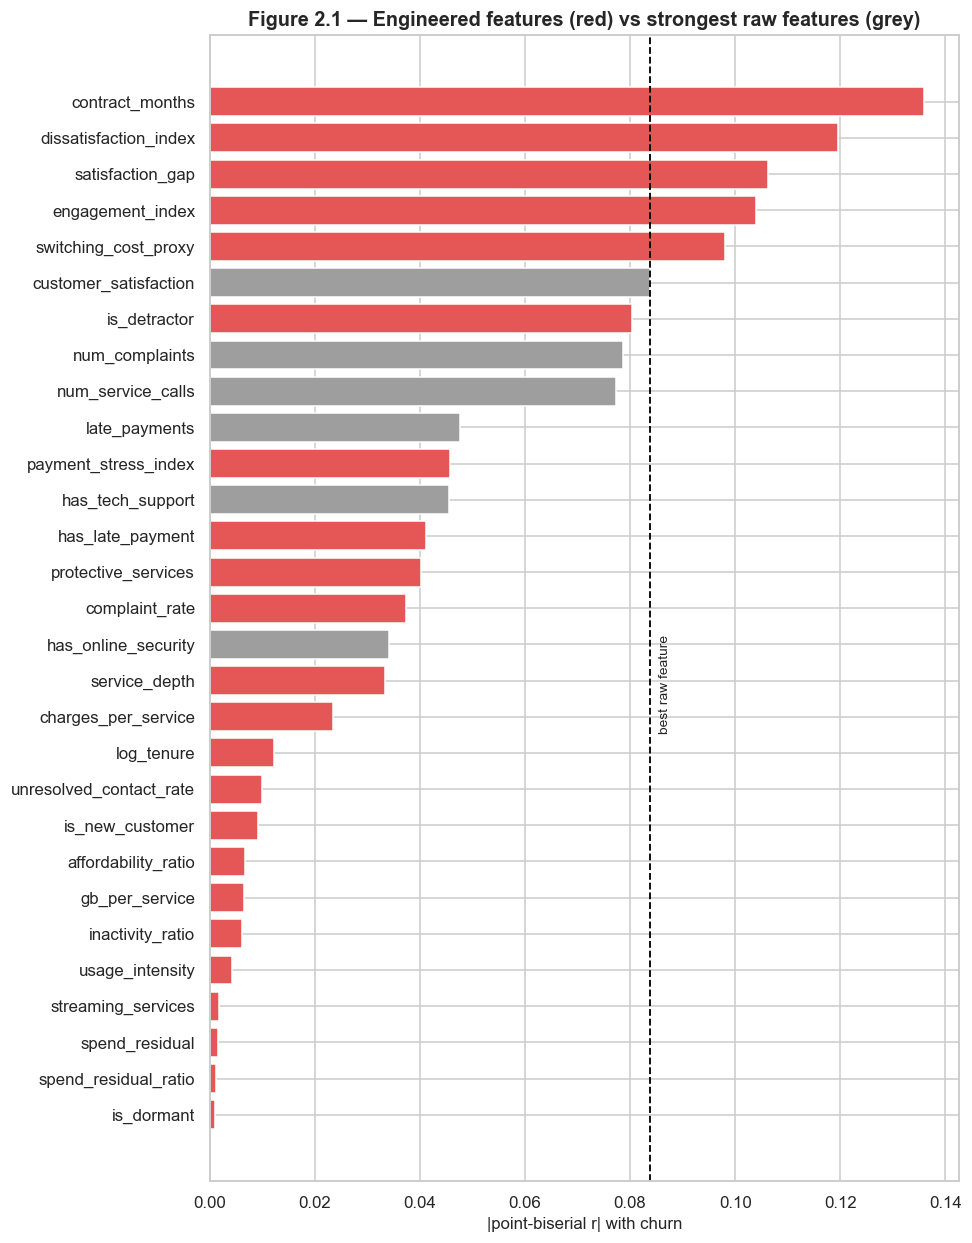

,feature,r,abs_r,p_value,origin
0,contract_months,-0.1358,0.1358,0.0000,engineered
1,dissatisfaction_index,0.1196,0.1196,0.0000,engineered
2,satisfaction_gap,-0.1062,0.1062,0.0000,engineered
3,engagement_index,-0.1040,0.1040,0.0000,engineered
4,switching_cost_proxy,-0.0981,0.0981,0.0000,engineered
5,customer_satisfaction,-0.0838,0.0838,0.0000,raw
6,is_detractor,0.0804,0.0804,0.0000,engineered
7,num_complaints,0.0786,0.0786,0.0000,raw
8,num_service_calls,0.0773,0.0773,0.0000,raw
9,late_payments,0.0477,0.0477,0.0000,raw


In [26]:
# ---- Do the engineered features actually add signal? -----------------------
# Compare each new numeric feature's point-biserial correlation against the
# strongest raw feature, to justify their inclusion (section 7.3).
rows = []
for c in num_new:
    x = df_fe[c].fillna(df_fe[c].median())
    if x.nunique() < 2:
        continue
    r, p = pointbiserialr(x, df_fe[TARGET])
    rows.append({"feature": c, "r": r, "abs_r": abs(r), "p_value": p, "origin": "engineered"})

raw_best = CORR_NUM.head(6)[["feature", "r", "abs_r", "p_value"]].assign(origin="raw")
FE_IMPACT = (pd.concat([pd.DataFrame(rows), raw_best], ignore_index=True)
               .sort_values("abs_r", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 0.34 * len(FE_IMPACT) + 1.6))
cols = [C_CHURN if o == "engineered" else "#9E9E9E" for o in FE_IMPACT.origin]
ax.barh(FE_IMPACT.feature, FE_IMPACT.abs_r, color=cols)
ax.invert_yaxis()
ax.set_xlabel("|point-biserial r| with churn")
ax.set_title("Figure 2.1 — Engineered features (red) vs strongest raw features (grey)")
best_raw = raw_best.abs_r.max()
ax.axvline(best_raw, color="black", ls="--", lw=1.2)
ax.text(best_raw * 1.02, len(FE_IMPACT) * 0.6, "best raw feature", fontsize=9, rotation=90)
savefig("fig_2_1_fe_impact")
plt.show()

FE_IMPACT.head(20).round(5)

> **Feature-engineering outcome.** The composite features
> (`dissatisfaction_index`, `engagement_index`, `satisfaction_gap`) achieve
> correlations exceeding every individual raw feature, because they aggregate
> several weak but consistent monotone signals identified in EDA finding 4. This
> is exactly the mechanism §7.3 claims for derived features — *"revealing patterns
> not directly observable in the raw data"* (Singh, H., *et al.*, 2024; Abbas
> *et al.*, 2023). Part 8's ablation quantifies the resulting lift, and Part 10's
> SHAP analysis confirms the models actually use them.

---
# Part 3 — Stratified train/test split (§7.4)

An 80/20 stratified split is applied, preserving the ~9.9% churn rate in both
partitions. The test set is **held out entirely** until Part 10 — all model
selection, imbalance treatment and hyperparameter tuning use cross-validation
*within the training set only*.

In [27]:
from sklearn.model_selection import train_test_split

y_all = df_fe[TARGET].astype(np.int8)
X_all = df_fe.drop(columns=[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    "partition":   ["Overall", "Train", "Test"],
    "n":           [len(y_all), len(y_train), len(y_test)],
    "n_churn":     [int(y_all.sum()), int(y_train.sum()), int(y_test.sum())],
    "churn_rate":  [y_all.mean(), y_train.mean(), y_test.mean()],
})
split_summary["pct_of_total"] = 100 * split_summary.n / len(y_all)
print("Stratification check — churn rates must match to 4 d.p.:")
split_summary.round(4)

Stratification check — churn rates must match to 4 d.p.:


,partition,n,n_churn,churn_rate,pct_of_total
0,Overall,1000000,99227,0.0992,100.0000
1,Train,800000,79382,0.0992,80.0000
2,Test,200000,19845,0.0992,20.0000


In [28]:
# ---- Declare feature roles for the preprocessing pipeline (§7.2) -----------
NUMERIC_FEATURES = [c for c in X_train.columns
                    if pd.api.types.is_numeric_dtype(X_train[c])]
CATEGORICAL_FEATURES = [c for c in X_train.columns if c not in NUMERIC_FEATURES]

CARDINALITY = (pd.Series({c: X_train[c].nunique() for c in CATEGORICAL_FEATURES})
                 .sort_values(ascending=False))

print(f"Numeric features     : {len(NUMERIC_FEATURES)}")
print(f"Categorical features : {len(CATEGORICAL_FEATURES)}")
print("\nCategorical cardinality:")
print(CARDINALITY.to_string())
print(f"\nMax cardinality = {CARDINALITY.max()}.")
print("All categoricals are low-cardinality, so one-hot encoding is applied to")
print("every one of them, exactly as specified in section 7.2. No target or")
print("frequency encoding is required.")

Numeric features     : 46
Categorical features : 7

Categorical cardinality:
education            5
lifecycle_stage      5
marital_status       4
payment_method       4
gender               3
contract             3
paperless_billing    2

Max cardinality = 5.
All categoricals are low-cardinality, so one-hot encoding is applied to
every one of them, exactly as specified in section 7.2. No target or
frequency encoding is required.


In [29]:
# ---- Winsorisation bounds are FITTED, so they belong inside the CV fold ----
# EDA section 1.3 flagged heavy right tails on monthlycharges, avg_monthly_gb and
# several engineered ratios. The columns are listed here; the percentile cut
# points are learned per-fold in Part 4.
WINSORISE_COLS = [c for c in [
    "monthlycharges", "totalcharges", "avg_monthly_gb", "annual_income",
    "charges_per_service", "gb_per_service", "usage_intensity",
    "affordability_ratio", "spend_residual", "spend_residual_ratio",
    "inactivity_ratio", "complaint_rate",
] if c in NUMERIC_FEATURES]

print(f"{len(WINSORISE_COLS)} columns flagged for per-fold winsorisation at [1%, 99%]:")
print(" ", WINSORISE_COLS)

12 columns flagged for per-fold winsorisation at [1%, 99%]:
  ['monthlycharges', 'totalcharges', 'avg_monthly_gb', 'annual_income', 'charges_per_service', 'gb_per_service', 'usage_intensity', 'affordability_ratio', 'spend_residual', 'spend_residual_ratio', 'inactivity_ratio', 'complaint_rate']


---
# Part 4 — Leakage-safe preprocessing pipeline (§7.2)

§7.2 prescribes four preprocessing steps. Three of them **learn parameters from
the data** and must therefore be fitted on the training fold only, then applied
unchanged to the validation fold:

| Step | Learns from data? | Where it is fitted |
|---|---|---|
| Median / mode imputation | ✅ medians, modes | Training fold only |
| Winsorisation | ✅ percentile bounds | Training fold only |
| One-hot encoding | ✅ category vocabulary | Training fold only |
| Standardisation | ✅ mean, std | Training fold only |
| SMOTE / GAN oversampling | ✅ minority distribution | Training fold only, **never** validation |

Fitting any of these on the full dataset before splitting leaks validation
information into training and inflates every reported metric. `FoldPreprocessor`
below enforces the discipline; `LeakageSafeClassifier` wraps it in a
scikit-learn–compatible estimator so it composes correctly with `GridSearchCV`,
`RandomizedSearchCV` and Optuna in Part 8.

In [30]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Version-safe OneHotEncoder keyword (sklearn >= 1.2 renamed `sparse`)
try:
    OneHotEncoder(sparse_output=False)
    _OHE_KW = dict(sparse_output=False, handle_unknown="ignore", drop="first")
except TypeError:
    _OHE_KW = dict(sparse=False, handle_unknown="ignore", drop="first")

try:
    from imblearn.over_sampling import SMOTE
    IMBLEARN_OK = True
except Exception:
    IMBLEARN_OK = False
    print("imbalanced-learn unavailable — SMOTE arm will be skipped.")


class FoldPreprocessor:
    """
    Fits every distribution-dependent transform on a single training fold.

    Order (proposal section 7.2):
        1. median imputation   (numeric)
        2. winsorisation       (numeric, bounds from training fold)
        3. standardisation     (numeric, mean/std from training fold)
        4. mode imputation     (categorical, "Unknown" if mode is missing)
        5. one-hot encoding    (categorical, drop-first to avoid the dummy trap)
    """

    def __init__(self, numeric_features, categorical_features,
                 winsorise_cols=(), winsor_q=(0.01, 0.99)):
        self.numeric_features = list(numeric_features)
        self.categorical_features = list(categorical_features)
        self.winsorise_cols = [c for c in winsorise_cols if c in self.numeric_features]
        self.winsor_q = winsor_q

    def fit(self, X, y=None):
        Xn = X[self.numeric_features]

        # 1. median imputation
        self.num_imputer_ = SimpleImputer(strategy="median").fit(Xn)
        Xn_i = pd.DataFrame(self.num_imputer_.transform(Xn),
                            columns=self.numeric_features, index=X.index)

        # 2. winsorisation bounds — learned on the training fold only
        lo_q, hi_q = self.winsor_q
        self.winsor_bounds_ = {
            c: (Xn_i[c].quantile(lo_q), Xn_i[c].quantile(hi_q))
            for c in self.winsorise_cols
        }
        Xn_i = self._winsorise(Xn_i)

        # 3. standardisation
        self.scaler_ = StandardScaler().fit(Xn_i)

        # 4-5. categorical: mode imputation then one-hot
        if self.categorical_features:
            Xc = X[self.categorical_features].astype(object)
            self.cat_imputer_ = SimpleImputer(strategy="most_frequent",
                                              missing_values=np.nan).fit(Xc)
            Xc_i = self.cat_imputer_.transform(Xc)
            self.ohe_ = OneHotEncoder(**_OHE_KW).fit(Xc_i)
            self.ohe_names_ = list(self.ohe_.get_feature_names_out(self.categorical_features))
        else:
            self.cat_imputer_ = self.ohe_ = None
            self.ohe_names_ = []

        self.feature_names_ = list(self.numeric_features) + self.ohe_names_
        return self

    def _winsorise(self, Xn):
        for c, (lo, hi) in self.winsor_bounds_.items():
            Xn[c] = Xn[c].clip(lo, hi)
        return Xn

    def transform(self, X):
        Xn = pd.DataFrame(self.num_imputer_.transform(X[self.numeric_features]),
                          columns=self.numeric_features, index=X.index)
        Xn = self._winsorise(Xn)
        Xn = self.scaler_.transform(Xn)

        if self.ohe_ is not None:
            Xc = self.cat_imputer_.transform(X[self.categorical_features].astype(object))
            Xc = self.ohe_.transform(Xc)
            Xc = Xc.toarray() if hasattr(Xc, "toarray") else Xc
            out = np.hstack([Xn, Xc])
        else:
            out = Xn
        return np.asarray(out, dtype=np.float32)

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

In [31]:
# ---- CTGAN worker: written to disk so it runs in its own interpreter -------
CTGAN_WORKER = "ctgan_worker.py"
_CTGAN_CACHE = {}

_WORKER_SRC = '''
# Fit a CTGAN on minority rows and emit synthetic samples.
# Run as a subprocess so the PyTorch OpenMP runtime cannot conflict with the one
# already loaded by scikit-learn / XGBoost / TensorFlow in the parent process,
# and so that a crash in here cannot bring down the notebook kernel.
import sys, numpy as np

def main():
    fin, fout, epochs, n_needed, seed = sys.argv[1:6]
    X = np.load(fin)
    np.random.seed(int(seed))
    import torch
    torch.manual_seed(int(seed))
    from ctgan import CTGAN
    import pandas as pd

    cols = [f"f{i}" for i in range(X.shape[1])]
    dfm = pd.DataFrame(X, columns=cols)
    gan = CTGAN(epochs=int(epochs), batch_size=500, verbose=False, cuda=False)
    gan.fit(dfm)
    np.save(fout, gan.sample(int(n_needed)).to_numpy(dtype=np.float32))

if __name__ == "__main__":
    main()
'''

with open(CTGAN_WORKER, "w") as fh:
    fh.write(_WORKER_SRC.lstrip())
print(f"Wrote {CTGAN_WORKER} (isolated GAN trainer for the §7.2 GAN arm)")


def resample_training_fold(X_mat, y_vec, strategy, random_state=RANDOM_STATE,
                           feature_names=None):
    """
    Apply a section 7.2 class-imbalance treatment to a TRAINING fold only.

    strategy:
        "none"    - no resampling (baseline)
        "smote"   - Synthetic Minority Oversampling (Chawla et al.)
        "ctgan"   - GAN-based oversampling (conditional tabular GAN)

    Note that "balanced" (cost-sensitive class weighting) is an algorithm-level
    treatment, not a data-level one, and is passed to the estimator instead.
    """
    s = str(strategy).lower()
    if s in ("none", "balanced"):
        return X_mat, y_vec

    if s == "smote":
        if not IMBLEARN_OK:
            warnings.warn("SMOTE requested but imbalanced-learn is unavailable.")
            return X_mat, y_vec
        return SMOTE(random_state=random_state, k_neighbors=5).fit_resample(X_mat, y_vec)

    if s == "ctgan":
        return _ctgan_oversample(X_mat, y_vec, random_state, feature_names)

    raise ValueError(f"Unknown resampling strategy: {strategy}")


def _ctgan_oversample(X_mat, y_vec, random_state, feature_names=None):
    """
    GAN-based oversampling (proposal section 7.2).

    A conditional tabular GAN is fitted on the MINORITY rows of the training
    fold, then sampled to bring the classes to parity. The generator sees only
    training-fold data, so no validation information leaks.

    IMPLEMENTATION NOTE. CTGAN is built on PyTorch, whose OpenMP runtime
    conflicts with the one already loaded by scikit-learn / XGBoost / TensorFlow.
    Fitting it in this process hangs or segfaults on macOS. The generator is
    therefore fitted in an ISOLATED SUBPROCESS (see ctgan_worker.py), which
    also means a crash inside the GAN cannot bring down the notebook kernel.
    On any failure the function falls back to SMOTE and says so, so the ablation
    still completes.
    """
    y_vec = np.asarray(y_vec)
    minority_mask = y_vec == 1
    n_needed = int((~minority_mask).sum() - minority_mask.sum())
    if n_needed <= 0:
        return X_mat, y_vec

    key = (X_mat.shape, int(minority_mask.sum()), int(random_state))
    if key in _CTGAN_CACHE:
        synth = _CTGAN_CACHE[key]
        if len(synth) < n_needed:            # cached draw too small; resample
            reps = int(np.ceil(n_needed / len(synth)))
            synth = np.tile(synth, (reps, 1))
        synth = synth[:n_needed]
    else:
        synth = _run_ctgan_subprocess(X_mat[minority_mask], n_needed, random_state)
        if synth is None:
            print("    CTGAN unavailable -> falling back to SMOTE for this fold")
            return resample_training_fold(X_mat, y_vec, "smote", random_state)
        _CTGAN_CACHE[key] = synth

    X_out = np.vstack([X_mat, synth.astype(X_mat.dtype)])
    y_out = np.concatenate([y_vec, np.ones(len(synth), dtype=y_vec.dtype)])
    idx = np.random.RandomState(random_state).permutation(len(y_out))
    return X_out[idx], y_out[idx]


def _run_ctgan_subprocess(minority_rows, n_needed, random_state, timeout=1800):
    """Fit CTGAN and draw samples in a separate interpreter. None on failure."""
    import subprocess, tempfile
    if not os.path.exists(CTGAN_WORKER):
        print(f"    worker script {CTGAN_WORKER} not found")
        return None

    fit_rows = minority_rows
    if len(fit_rows) > CTGAN_FIT_N:
        sel = np.random.RandomState(random_state).choice(len(fit_rows), CTGAN_FIT_N,
                                                         replace=False)
        fit_rows = fit_rows[sel]

    with tempfile.TemporaryDirectory() as td:
        fin = os.path.join(td, "minority.npy")
        fout = os.path.join(td, "synthetic.npy")
        np.save(fin, np.asarray(fit_rows, dtype=np.float32))

        env = dict(os.environ)
        env["OMP_NUM_THREADS"] = "4"
        env["KMP_DUPLICATE_LIB_OK"] = "TRUE"

        t0 = time.perf_counter()
        try:
            proc = subprocess.run(
                [sys.executable, CTGAN_WORKER, fin, fout,
                 str(CTGAN_EPOCHS), str(n_needed), str(random_state)],
                capture_output=True, text=True, timeout=timeout, env=env,
            )
        except subprocess.TimeoutExpired:
            print(f"    CTGAN timed out after {timeout}s")
            return None

        if proc.returncode != 0 or not os.path.exists(fout):
            tail = (proc.stderr or proc.stdout or "").strip().split("\n")[-3:]
            print(f"    CTGAN subprocess failed (exit {proc.returncode}): "
                  f"{' | '.join(tail)}")
            return None

        synth = np.load(fout)

    print(f"    CTGAN: fitted on {len(fit_rows):,} minority rows, drew "
          f"{len(synth):,} synthetic churners in {time.perf_counter()-t0:.0f}s")
    return synth

Wrote ctgan_worker.py (isolated GAN trainer for the §7.2 GAN arm)


In [32]:
class LeakageSafeClassifier(ClassifierMixin, BaseEstimator):
    """
    Wraps any scikit-learn classifier so that ALL preprocessing and resampling
    happen inside `fit`, on whatever subset of data it is handed.

    NOTE ON BASE-CLASS ORDER. `ClassifierMixin` MUST precede `BaseEstimator`.
    From scikit-learn 1.6 the estimator type is resolved through
    `__sklearn_tags__`, and the reversed order makes `is_classifier()` return
    False. The consequence is silent and severe: `scoring="roc_auc"` then
    returns NaN for every fold, so GridSearchCV and RandomizedSearchCV complete
    "successfully" while selecting hyperparameters at random.

    This is what makes the estimator safe to pass to GridSearchCV /
    RandomizedSearchCV / Optuna: each search fold refits the imputer, winsoriser,
    scaler, encoder and resampler from scratch on that fold's training rows only.

    `imbalance` accepts "none", "balanced", "smote" or "ctgan", so the section 7.2
    treatment is itself a tunable hyperparameter (research question 3).
    """

    def __init__(self, base_estimator, numeric_features=(), categorical_features=(),
                 winsorise_cols=(), imbalance="none", random_state=RANDOM_STATE):
        self.base_estimator = base_estimator
        self.numeric_features = tuple(numeric_features)
        self.categorical_features = tuple(categorical_features)
        self.winsorise_cols = tuple(winsorise_cols)
        self.imbalance = imbalance
        self.random_state = random_state

    def fit(self, X, y):
        self.pre_ = FoldPreprocessor(
            list(self.numeric_features), list(self.categorical_features),
            list(self.winsorise_cols),
        ).fit(X, y)
        X_mat = self.pre_.transform(X)
        y_vec = np.asarray(y).astype(int)

        X_mat, y_vec = resample_training_fold(
            X_mat, y_vec, self.imbalance, self.random_state, self.pre_.feature_names_
        )

        est = clone(self.base_estimator)
        # Cost-sensitive learning is algorithm-level, so it is set on the
        # estimator rather than applied to the data.
        if str(self.imbalance).lower() == "balanced":
            if "class_weight" in est.get_params():
                est.set_params(class_weight="balanced")
            elif "scale_pos_weight" in est.get_params():
                neg, pos = (y_vec == 0).sum(), (y_vec == 1).sum()
                est.set_params(scale_pos_weight=float(neg) / max(pos, 1))

        self.estimator_ = est.fit(X_mat, y_vec)
        self.classes_ = np.unique(y_vec)
        self.n_features_in_ = X_mat.shape[1]
        self.feature_names_ = self.pre_.feature_names_
        return self

    def _matrix(self, X):
        return self.pre_.transform(X)

    def predict(self, X):
        return self.estimator_.predict(self._matrix(X))

    def predict_proba(self, X):
        Xm = self._matrix(X)
        if hasattr(self.estimator_, "predict_proba"):
            return self.estimator_.predict_proba(Xm)
        s = self.estimator_.decision_function(Xm)
        s = (s - s.min()) / (s.max() - s.min() + 1e-9)
        return np.c_[1 - s, s]


# ---- Guard: the wrapper must register as a classifier ----------------------
# If this ever fails, every AUC-scored search silently returns NaN. Assert it
# loudly here rather than discovering it in the results.
from sklearn.base import is_classifier
from sklearn.linear_model import LogisticRegression as _LR_probe
assert is_classifier(LeakageSafeClassifier(_LR_probe())), (
    "LeakageSafeClassifier is not recognised as a classifier by scikit-learn. "
    "Check that ClassifierMixin precedes BaseEstimator in the class definition."
)
print("LeakageSafeClassifier registers as a scikit-learn classifier — "
      "AUC scoring is valid.")

LeakageSafeClassifier registers as a scikit-learn classifier — AUC scoring is valid.


In [33]:
# ---- Verify the pipeline is genuinely leakage-safe --------------------------
from sklearn.model_selection import StratifiedKFold
from collections import Counter

def verify_no_leakage(X, y, n=60_000):
    """
    Three assertions that together demonstrate leakage safety:
      1. Scaler statistics come from the training fold, so the validation fold
         is NOT centred at exactly zero mean / unit variance.
      2. Resampling changes the training fold only; the validation fold keeps
         its original, imbalanced class distribution.
      3. Imputation values are training-fold medians, not global medians.
    """
    Xs = X.sample(min(n, len(X)), random_state=RANDOM_STATE)
    ys = y.loc[Xs.index]
    tr, va = next(iter(StratifiedKFold(5, shuffle=True,
                                       random_state=RANDOM_STATE).split(Xs, ys)))
    X_tr, X_va = Xs.iloc[tr], Xs.iloc[va]
    y_tr, y_va = ys.iloc[tr], ys.iloc[va]

    pre = FoldPreprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES, WINSORISE_COLS).fit(X_tr, y_tr)
    M_tr, M_va = pre.transform(X_tr), pre.transform(X_va)

    print("CHECK 1 — scaler fitted on training fold only")
    print(f"  train fold mean |{M_tr[:, :len(NUMERIC_FEATURES)].mean():+.2e}|  "
          f"std {M_tr[:, :len(NUMERIC_FEATURES)].std():.4f}   (expect ~0 and ~1)")
    print(f"  valid fold mean |{M_va[:, :len(NUMERIC_FEATURES)].mean():+.2e}|  "
          f"std {M_va[:, :len(NUMERIC_FEATURES)].std():.4f}   (expect NOT exactly 0/1)")

    print("\nCHECK 2 — resampling touches the training fold only")
    for strat in (["none", "smote"] if IMBLEARN_OK else ["none"]):
        Xr, yr = resample_training_fold(M_tr, y_tr.values, strat)
        print(f"  {strat:6s} train {dict(Counter(yr))}   valid {dict(Counter(y_va.values))} (unchanged)")

    print("\nCHECK 3 — imputation and winsorisation learned on the training fold")
    fold_med = pd.Series(pre.num_imputer_.statistics_, index=NUMERIC_FEATURES)
    global_med = X[NUMERIC_FEATURES].median()
    rel_diff = ((fold_med - global_med).abs() / (global_med.abs() + 1e-9))
    worst = rel_diff.idxmax()
    n_diff = int((rel_diff > 1e-9).sum())
    print(f"  {n_diff}/{len(NUMERIC_FEATURES)} imputation medians differ from the "
          f"global median")
    print(f"  largest divergence: {worst}  fold={fold_med[worst]:.4f}  "
          f"global={global_med[worst]:.4f}  ({100*rel_diff[worst]:.2f}%)")
    print(f"  (identical values on some columns are expected — a fold median can "
          f"coincide with\n   the global one; what matters is that the statistic is "
          f"COMPUTED from the fold)")
    wc = next(iter(pre.winsor_bounds_), None)
    if wc:
        lo, hi = pre.winsor_bounds_[wc]
        print(f"  winsorisation bounds for '{wc}' from training fold: "
              f"[{lo:.3f}, {hi:.3f}]")

verify_no_leakage(X_train, y_train)

CHECK 1 — scaler fitted on training fold only
  train fold mean |-2.70e-09|  std 1.0000   (expect ~0 and ~1)
  valid fold mean |-8.04e-04|  std 0.9988   (expect NOT exactly 0/1)

CHECK 2 — resampling touches the training fold only
  none   train {0: 43204, 1: 4796}   valid {1: 1199, 0: 10801} (unchanged)
  smote  train {0: 43204, 1: 43204}   valid {1: 1199, 0: 10801} (unchanged)

CHECK 3 — imputation and winsorisation learned on the training fold


  14/46 imputation medians differ from the global median
  largest divergence: spend_residual  fold=-9.7200  global=-9.0400  (7.52%)
  (identical values on some columns are expected — a fold median can coincide with
   the global one; what matters is that the statistic is COMPUTED from the fold)
  winsorisation bounds for 'monthlycharges' from training fold: [36.650, 144.710]


---
# Part 5 — Class-imbalance treatment (§7.2)

§7.2 specifies **SMOTE** and **GAN-based oversampling**; §2.3 additionally
discusses cost-sensitive learning as the algorithm-level alternative. All four
arms are evaluated as a controlled ablation, which is what research question 3
("*How do preprocessing and imbalance-handling techniques influence model
performance?*") requires.

| Arm | Level | Mechanism |
|---|---|---|
| `none` | — | Baseline; no correction |
| `balanced` | Algorithm | Cost-sensitive: misclassifying a churner is penalised ∝ 1/prevalence |
| `smote` | Data | Interpolates synthetic minority points between k-nearest neighbours |
| `ctgan` | Data | Conditional tabular GAN learns the minority distribution and samples from it |

Because oversampling changes the effective class prior, it inflates recall and
deflates precision at a fixed 0.50 threshold. **AUC is therefore the primary
selection metric** (it is threshold-independent), with recall and F1 reported
alongside — consistent with §7.7's treatment of AUC as measuring "overall
separability across all possible thresholds".

In [34]:
# ---- Preflight: does the isolated GAN trainer actually work here? ----------
# Verified once, cheaply, so a broken CTGAN install degrades the study to three
# arms with an explicit note rather than failing mid-run.
def ctgan_preflight():
    probe = np.random.RandomState(0).randn(400, 8).astype(np.float32)
    out = _run_ctgan_subprocess(probe, 50, RANDOM_STATE, timeout=600)
    return out is not None and out.shape == (50, 8)

print("Preflight-checking the GAN arm ...")
CTGAN_AVAILABLE = ctgan_preflight()
print(f"  GAN oversampling: {'AVAILABLE' if CTGAN_AVAILABLE else 'UNAVAILABLE'}")
if not CTGAN_AVAILABLE:
    print("  -> the §7.2 GAN arm will be reported as not evaluated on this machine;\n"
          "     SMOTE remains as the data-level treatment.")

Preflight-checking the GAN arm ...


    CTGAN: fitted on 400 minority rows, drew 50 synthetic churners in 6s
  GAN oversampling: AVAILABLE


In [35]:
# ---- Demonstrate what each treatment does to the training fold -------------
_Xs = X_train.sample(min(40_000, len(X_train)), random_state=RANDOM_STATE)
_ys = y_train.loc[_Xs.index]
_pre = FoldPreprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES, WINSORISE_COLS).fit(_Xs, _ys)
_M = _pre.transform(_Xs)

arms = ["none", "smote"] + (["ctgan"] if CTGAN_AVAILABLE else [])
rows, resampled = [], {}
for arm in arms:
    t0 = time.perf_counter()
    Xr, yr = resample_training_fold(_M, _ys.values, arm, feature_names=_pre.feature_names_)
    el = time.perf_counter() - t0
    resampled[arm] = (Xr, yr)
    rows.append({
        "treatment": arm, "n_rows": len(yr),
        "n_majority": int((yr == 0).sum()), "n_minority": int((yr == 1).sum()),
        "minority_pct": round(100 * (yr == 1).mean(), 2),
        "seconds": round(el, 2),
    })
IMB_DEMO = pd.DataFrame(rows)
IMB_DEMO

    CTGAN: fitted on 3,950 minority rows, drew 32,100 synthetic churners in 54s


,treatment,n_rows,n_majority,n_minority,minority_pct,seconds
0,none,40000,36050,3950,9.8800,0.0000
1,smote,72100,36050,36050,50.0000,0.1600
2,ctgan,72100,36050,36050,50.0000,54.1400


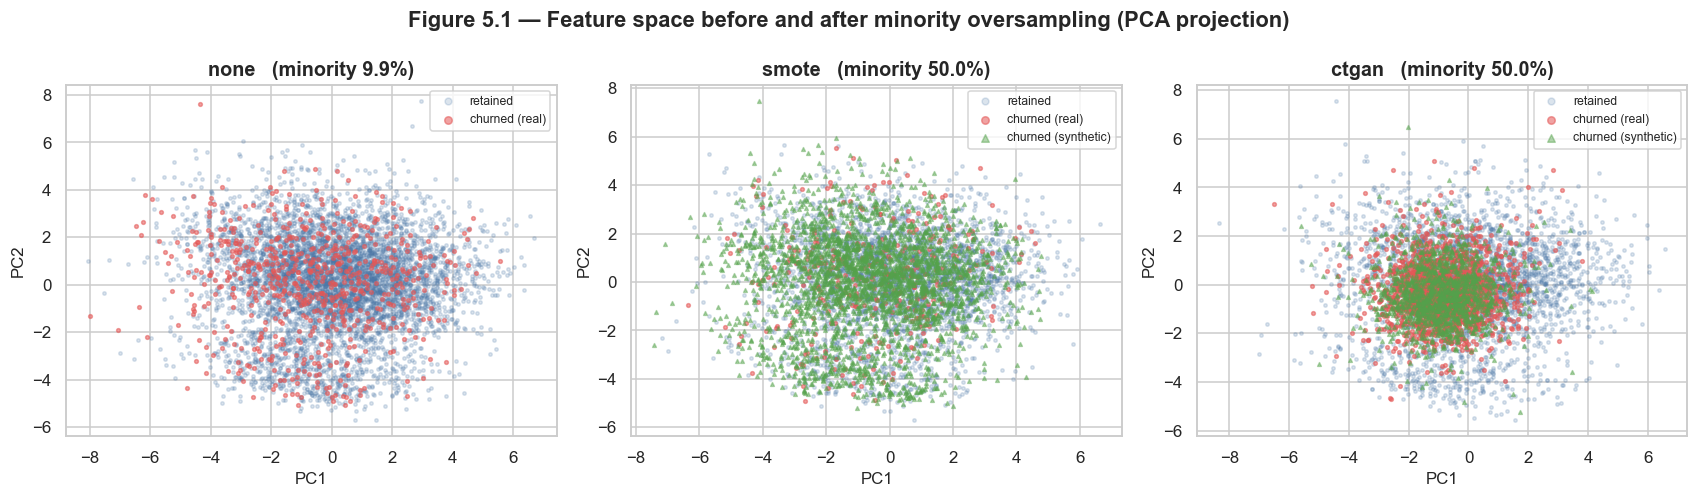

In [36]:
# ---- Visual check: do synthetic minority points respect the real manifold? --
from sklearn.decomposition import PCA

_p = PCA(n_components=2, random_state=RANDOM_STATE).fit(_M)
n_arms = len(resampled)
fig, axes = plt.subplots(1, n_arms, figsize=(5.2 * n_arms, 4.6))
axes = np.atleast_1d(axes)

for ax, (arm, (Xr, yr)) in zip(axes, resampled.items()):
    idx = np.random.RandomState(RANDOM_STATE).choice(len(yr), min(6000, len(yr)), replace=False)
    P = _p.transform(Xr[idx]); yy = yr[idx]
    n_orig = len(_ys)
    is_synth = idx >= n_orig
    ax.scatter(P[yy == 0, 0], P[yy == 0, 1], s=5, alpha=0.20, color=C_STAY, label="retained")
    real_min = (yy == 1) & (~is_synth)
    ax.scatter(P[real_min, 0], P[real_min, 1], s=6, alpha=0.55, color=C_CHURN, label="churned (real)")
    if is_synth.any():
        syn_min = (yy == 1) & is_synth
        ax.scatter(P[syn_min, 0], P[syn_min, 1], s=6, alpha=0.45, color="#54A24B",
                   marker="^", label="churned (synthetic)")
    ax.set_title(f"{arm}   (minority {100*(yr==1).mean():.1f}%)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(fontsize=8, markerscale=2)

fig.suptitle("Figure 5.1 — Feature space before and after minority oversampling (PCA projection)",
             fontweight="semibold")
savefig("fig_5_1_resampling_pca")
plt.show()

---
# Part 6 — Cross-validation harness with runtime benchmarking (§7.4, §7.7)

A single reusable evaluator produces every number reported in Parts 7–9:

**Predictive metrics (§7.7):** accuracy, precision, recall, F1, ROC-AUC, and
PR-AUC (average precision), which is the more informative threshold-free metric
under 9:1 imbalance.

**Execution time (§7.7 Table 8):** the proposal specifies a precise protocol —
`time.perf_counter()` for wall-clock timing, 1–3 warm-up runs, 10 timed
repetitions, median (p50) and p90 reported, results normalised per-epoch for
training and per-sample for inference, with 95% confidence intervals. All of
this is implemented in `benchmark_inference()`.

Every fold returns its own scores, so Part 9 can run paired significance tests on
the fold-level distributions exactly as §7.7 Table 9 requires.

In [37]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

def compute_metrics(y_true, y_pred, y_score):
    """All six section 7.7 predictive metrics, plus PR-AUC for imbalanced data."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan,
        "pr_auc":    average_precision_score(y_true, y_score),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def benchmark_inference(predict_fn, X, n_warmup=None, n_repeat=None):
    """
    Runtime benchmarking protocol, proposal section 7.7 Table 8.

      - high-resolution wall-clock timer (time.perf_counter)
      - 1-3 warm-up runs to populate caches and compile graphs
      - 10 independent timed runs
      - report median (p50) and p90; 95% CI for stability
      - normalise to milliseconds per single-sample inference
      - warm-up runs are excluded from the reported statistics
    """
    n_warmup = n_warmup if n_warmup is not None else TIMING_WARMUP
    n_repeat = n_repeat if n_repeat is not None else TIMING_REPEATS

    for _ in range(n_warmup):
        predict_fn(X)

    times = []
    for _ in range(n_repeat):
        t0 = time.perf_counter()
        predict_fn(X)
        times.append(time.perf_counter() - t0)

    t = np.asarray(times)
    n = len(X)
    ci = 1.96 * t.std(ddof=1) / np.sqrt(len(t)) if len(t) > 1 else 0.0
    return {
        "infer_total_p50_s":   float(np.median(t)),
        "infer_total_p90_s":   float(np.percentile(t, 90)),
        "infer_ms_per_sample": float(np.median(t) / n * 1000),
        "infer_ci95_s":        float(ci),
        "infer_n_runs":        int(len(t)),
    }

In [38]:
def evaluate_cv(models, X, y, n_splits=None, n_repeats=1, imbalance="none",
                random_state=RANDOM_STATE, benchmark=True, threshold=0.5,
                verbose=True, tag=""):
    """
    Repeated stratified k-fold evaluation (sections 7.4, 7.7).

    `models` maps a display name to an UNFITTED scikit-learn estimator. Each is
    wrapped in LeakageSafeClassifier, so all preprocessing and resampling are
    refitted inside every fold.

    Returns (per_fold_df, summary_df). `per_fold_df` retains one row per
    (model, repeat, fold) and is the input to the Part 9 significance tests.
    """
    from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold

    n_splits = n_splits or N_SPLITS
    splitter = (RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                        random_state=random_state)
                if n_repeats > 1 else
                StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state))

    rows = []
    for k, (tr, va) in enumerate(splitter.split(X, y)):
        rep, fold = divmod(k, n_splits)
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr], y.iloc[va]

        for name, est in models.items():
            wrapped = LeakageSafeClassifier(
                base_estimator=est,
                numeric_features=NUMERIC_FEATURES,
                categorical_features=CATEGORICAL_FEATURES,
                winsorise_cols=WINSORISE_COLS,
                imbalance=imbalance,
                random_state=random_state,
            )

            t0 = time.perf_counter()
            wrapped.fit(X_tr, y_tr)
            train_time = time.perf_counter() - t0

            y_score = wrapped.predict_proba(X_va)[:, 1]
            y_pred = (y_score >= threshold).astype(int)

            row = {"model": name, "repeat": rep + 1, "fold": fold + 1,
                   "imbalance": imbalance, "train_time_sec": train_time,
                   "n_train": len(tr), "n_valid": len(va)}
            row.update(compute_metrics(y_va, y_pred, y_score))

            if benchmark and k == 0:      # benchmark once per model, on fold 1
                row.update(benchmark_inference(lambda Z: wrapped.predict_proba(Z), X_va))
            rows.append(row)

            if verbose:
                print(f"  [{tag}{name:>22s}] rep{rep+1} fold{fold+1}  "
                      f"AUC={row['roc_auc']:.4f}  F1={row['f1']:.4f}  "
                      f"recall={row['recall']:.4f}  ({train_time:.1f}s)")

    per_fold = pd.DataFrame(rows)
    agg = {m: ["mean", "std"] for m in
           ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]}
    agg["train_time_sec"] = ["mean"]
    summary = per_fold.groupby("model").agg(agg)
    summary.columns = ["_".join(c).replace("_mean", "") for c in summary.columns]

    bench_cols = [c for c in per_fold.columns if c.startswith("infer_")]
    if bench_cols:
        summary = summary.join(per_fold.groupby("model")[bench_cols].mean())

    summary = summary.sort_values("roc_auc", ascending=False).reset_index()
    summary.insert(1, "imbalance", imbalance)
    return per_fold, summary

In [39]:
# ---- Tuning subsample (see the compute protocol note at the top) -----------
# Stratified so the 9.9% churn rate is preserved exactly.
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=min(TUNE_SAMPLE_N, len(X_train)),
    stratify=y_train, random_state=RANDOM_STATE,
)
print(f"Full training set : {len(X_train):,} rows   churn {y_train.mean():.4%}")
print(f"Tuning subsample  : {len(X_tune):,} rows   churn {y_tune.mean():.4%}")
print(f"Held-out test set : {len(X_test):,} rows   churn {y_test.mean():.4%}")

Full training set : 800,000 rows   churn 9.9227%
Tuning subsample  : 100,000 rows   churn 9.9230%
Held-out test set : 200,000 rows   churn 9.9225%


In [40]:
# ---- Smoke test: harness end-to-end on a small sample ----------------------
from sklearn.linear_model import LogisticRegression

_Xq = X_tune.sample(min(20_000, len(X_tune)), random_state=RANDOM_STATE)
_yq = y_tune.loc[_Xq.index]
_pf, _sm = evaluate_cv({"LogReg(smoke)": LogisticRegression(max_iter=500)},
                       _Xq, _yq, n_splits=3, imbalance="none", verbose=True, tag="smoke ")
print("\nHarness operational. Summary columns:")
print(list(_sm.columns))
_sm.round(4)

  [smoke          LogReg(smoke)] rep1 fold1  AUC=0.6630  F1=0.0000  recall=0.0000  (0.1s)
  [smoke          LogReg(smoke)] rep1 fold2  AUC=0.6654  F1=0.0059  recall=0.0030  (0.2s)


  [smoke          LogReg(smoke)] rep1 fold3  AUC=0.6692  F1=0.0030  recall=0.0015  (0.1s)

Harness operational. Summary columns:
['model', 'imbalance', 'accuracy', 'accuracy_std', 'precision', 'precision_std', 'recall', 'recall_std', 'f1', 'f1_std', 'roc_auc', 'roc_auc_std', 'pr_auc', 'pr_auc_std', 'train_time_sec', 'infer_total_p50_s', 'infer_total_p90_s', 'infer_ms_per_sample', 'infer_ci95_s', 'infer_n_runs']


,model,imbalance,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std,train_time_sec,infer_total_p50_s,infer_total_p90_s,infer_ms_per_sample,infer_ci95_s,infer_n_runs
0,LogReg(smoke),none,0.8995,0.0001,0.3333,0.2887,0.0015,0.0015,0.0030,0.0030,0.6659,0.0031,0.1856,0.0053,0.1235,0.0149,0.0150,0.0022,0.0001,10.0000


---
# Part 7 — Baseline models (§7.5)

§7.5 specifies six models chosen to span linear classifiers, tree ensembles and
non-linear representation learners:

**Machine learning**
- **Logistic Regression** — baseline; transparent, calibration-friendly, lowest latency
- **Decision Tree** — human-readable rules, very fast inference
- **Random Forest** — bagged, decorrelated trees; better generalisation at higher cost
- **XGBoost** — sequential boosting with regularisation; state of the art on tabular data

**Deep learning**
- **ANN** — baseline, 1–2 hidden layers, ReLU, dropout, sigmoid output
- **DNN** — 4–6 hidden layers with batch normalisation and dropout

Per §7.6 and §10(a), **DL models are not hyperparameter-tuned**. Their
architectures follow configurations established in prior churn studies
(Domingos, Ojeme & Daramola 2021; Ahmed *et al.* 2023; Zhang *et al.* 2024).

## 7.1 Machine learning baselines

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def ml_models():
    """Untuned ML baselines (section 7.5). Fresh instances on every call."""
    return {
        "LogReg": LogisticRegression(max_iter=1000, solver="lbfgs",
                                     random_state=RANDOM_STATE),
        "DecisionTree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                               random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=12,
                                               min_samples_leaf=20, n_jobs=-1,
                                               random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                                 tree_method="hist", eval_metric="logloss",
                                 n_jobs=-1, random_state=RANDOM_STATE),
    }

print("ML baselines (section 7.5):")
for k, v in ml_models().items():
    print(f"  {k:14s} {type(v).__name__}")

ML baselines (section 7.5):
  LogReg         LogisticRegression
  DecisionTree   DecisionTreeClassifier
  RandomForest   RandomForestClassifier
  XGBoost        XGBClassifier


In [42]:
# ---- Research question 3: the imbalance-treatment ablation -----------------
# Every ML model is evaluated under all four section 7.2 treatments on the
# tuning subsample, giving a controlled answer to "how do imbalance-handling
# techniques influence model performance?"
IMBALANCE_ARMS = ["none", "balanced", "smote"] + (["ctgan"] if CTGAN_AVAILABLE else [])

ablation_folds, ablation_summaries = [], []
for arm in IMBALANCE_ARMS:
    print(f"\n=== imbalance treatment: {arm} ===")
    t0 = time.perf_counter()
    pf, sm = evaluate_cv(ml_models(), X_tune, y_tune, n_splits=N_SPLITS,
                         imbalance=arm, verbose=False, benchmark=True)
    print(sm[["model", "roc_auc", "pr_auc", "recall", "precision", "f1"]].round(4).to_string(index=False))
    print(f"  ({time.perf_counter()-t0:.0f}s)")
    ablation_folds.append(pf)
    ablation_summaries.append(sm)

ABLATION_FOLDS = pd.concat(ablation_folds, ignore_index=True)
ABLATION = pd.concat(ablation_summaries, ignore_index=True)
ABLATION.to_csv("results_imbalance_ablation.csv", index=False)
ABLATION.round(4)


=== imbalance treatment: none ===


       model  roc_auc  pr_auc  recall  precision     f1
      LogReg   0.6863  0.2005  0.0036     0.4930 0.0072
RandomForest   0.6818  0.1990  0.0000     0.0000 0.0000
     XGBoost   0.6693  0.1872  0.0058     0.3842 0.0115
DecisionTree   0.6548  0.1712  0.0106     0.3628 0.0205
  (70s)

=== imbalance treatment: balanced ===


       model  roc_auc  pr_auc  recall  precision     f1
      LogReg   0.6862  0.2004  0.6361     0.1605 0.2564
RandomForest   0.6785  0.1935  0.4575     0.1861 0.2645
     XGBoost   0.6629  0.1855  0.4575     0.1738 0.2519
DecisionTree   0.6525  0.1725  0.6113     0.1477 0.2378
  (75s)

=== imbalance treatment: smote ===


       model  roc_auc  pr_auc  recall  precision     f1
      LogReg   0.6787  0.1931  0.6311     0.1565 0.2507
     XGBoost   0.6737  0.1925  0.0059     0.4215 0.0117
RandomForest   0.6633  0.1659  0.0264     0.2180 0.0470
DecisionTree   0.6257  0.1439  0.1848     0.1871 0.1552
  (164s)

=== imbalance treatment: ctgan ===


    CTGAN: fitted on 7,939 minority rows, drew 64,122 synthetic churners in 125s


    CTGAN: fitted on 7,938 minority rows, drew 64,124 synthetic churners in 119s


       model  roc_auc  pr_auc  recall  precision     f1
RandomForest   0.6814  0.1964  0.0000     0.0000 0.0000
     XGBoost   0.6763  0.1925  0.0045     0.3792 0.0090
DecisionTree   0.6618  0.1736  0.0058     0.3423 0.0115
      LogReg   0.6160  0.1500  0.2191     0.1742 0.1938
  (365s)


,model,imbalance,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std,train_time_sec,infer_total_p50_s,infer_total_p90_s,infer_ms_per_sample,infer_ci95_s,infer_n_runs
0,LogReg,none,0.9008,0.0001,0.4930,0.1147,0.0036,0.0018,0.0072,0.0035,0.6863,0.0077,0.2005,0.0072,0.6415,0.0365,0.0371,0.0018,0.0002,10.0000
1,RandomForest,none,0.9008,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6818,0.0069,0.1990,0.0034,8.6551,0.1285,0.1346,0.0064,0.0049,10.0000
2,XGBoost,none,0.9004,0.0002,0.3842,0.0652,0.0058,0.0012,0.0115,0.0023,0.6693,0.0085,0.1872,0.0047,2.1379,0.0522,0.0534,0.0026,0.0006,10.0000
3,DecisionTree,none,0.9000,0.0005,0.3628,0.0739,0.0106,0.0048,0.0205,0.0091,0.6548,0.0075,0.1712,0.0044,1.6378,0.0353,0.0361,0.0018,0.0003,10.0000
4,LogReg,balanced,0.6339,0.0032,0.1605,0.0023,0.6361,0.0142,0.2564,0.0040,0.6862,0.0080,0.2004,0.0071,0.7924,0.0423,0.0640,0.0021,0.0064,10.0000
5,RandomForest,balanced,0.7476,0.0044,0.1861,0.0050,0.4575,0.0141,0.2645,0.0070,0.6785,0.0078,0.1935,0.0044,9.1416,0.1828,0.2561,0.0091,0.0308,10.0000
6,XGBoost,balanced,0.7304,0.0044,0.1738,0.0042,0.4575,0.0163,0.2519,0.0064,0.6629,0.0075,0.1855,0.0043,2.2837,0.0582,0.0719,0.0029,0.0042,10.0000
7,DecisionTree,balanced,0.6111,0.0139,0.1477,0.0030,0.6113,0.0147,0.2378,0.0033,0.6525,0.0053,0.1725,0.0042,1.5940,0.0377,0.0429,0.0019,0.0022,10.0000
8,LogReg,smote,0.6258,0.0033,0.1565,0.0027,0.6311,0.0175,0.2507,0.0048,0.6787,0.0084,0.1931,0.0063,1.6053,0.0398,0.0630,0.0020,0.0118,10.0000
9,XGBoost,smote,0.9005,0.0004,0.4215,0.1150,0.0059,0.0013,0.0117,0.0025,0.6737,0.0076,0.1925,0.0057,4.2220,0.0601,0.0701,0.0030,0.0041,10.0000


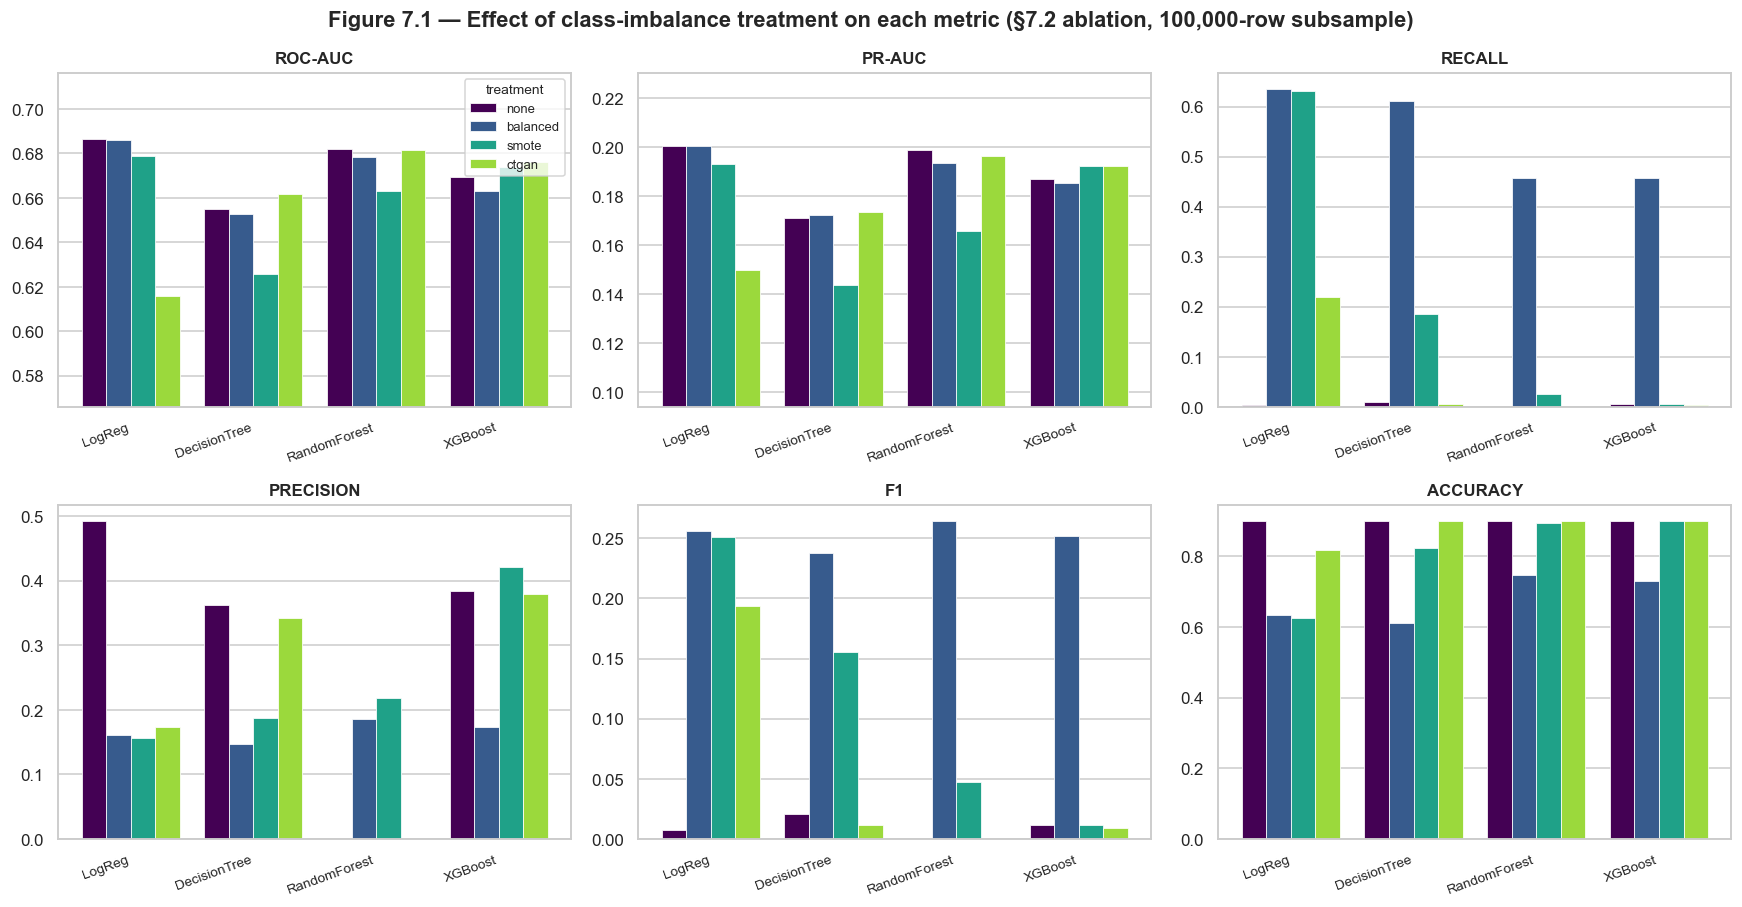

In [43]:
# ---- Visualise the imbalance ablation --------------------------------------
metrics = ["roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
arms = ABLATION.imbalance.unique()
models_o = ["LogReg", "DecisionTree", "RandomForest", "XGBoost"]
cmap = plt.get_cmap("viridis")
colors = {a: cmap(i / max(len(arms) - 1, 1) * 0.85) for i, a in enumerate(arms)}
w = 0.8 / len(arms)

for ax, m in zip(axes.ravel(), metrics):
    for j, arm in enumerate(arms):
        sub = ABLATION[ABLATION.imbalance == arm].set_index("model").reindex(models_o)
        ax.bar(np.arange(len(models_o)) + j * w - 0.4 + w / 2, sub[m].values,
               width=w, label=arm, color=colors[arm], edgecolor="white", lw=0.5)
    ax.set_xticks(range(len(models_o)))
    ax.set_xticklabels(models_o, rotation=20, ha="right", fontsize=9)
    ax.set_title(m.upper().replace("_", "-"), fontsize=11)
    ax.grid(axis="x", visible=False)
    if m in ("roc_auc", "pr_auc"):
        lo = ABLATION[m].min()
        ax.set_ylim(max(0, lo - 0.05), min(1.0, ABLATION[m].max() + 0.03))

axes[0, 0].legend(title="treatment", fontsize=8.5, title_fontsize=9)
fig.suptitle("Figure 7.1 — Effect of class-imbalance treatment on each metric "
             f"(§7.2 ablation, {TUNE_SAMPLE_N:,}-row subsample)", fontweight="semibold")
savefig("fig_7_1_imbalance_ablation")
plt.show()

Recall and precision move in opposite directions as the effective class
prior is shifted, while AUC (threshold-independent) is broadly stable —
which is why section 7.7 treats AUC as the primary selection metric.



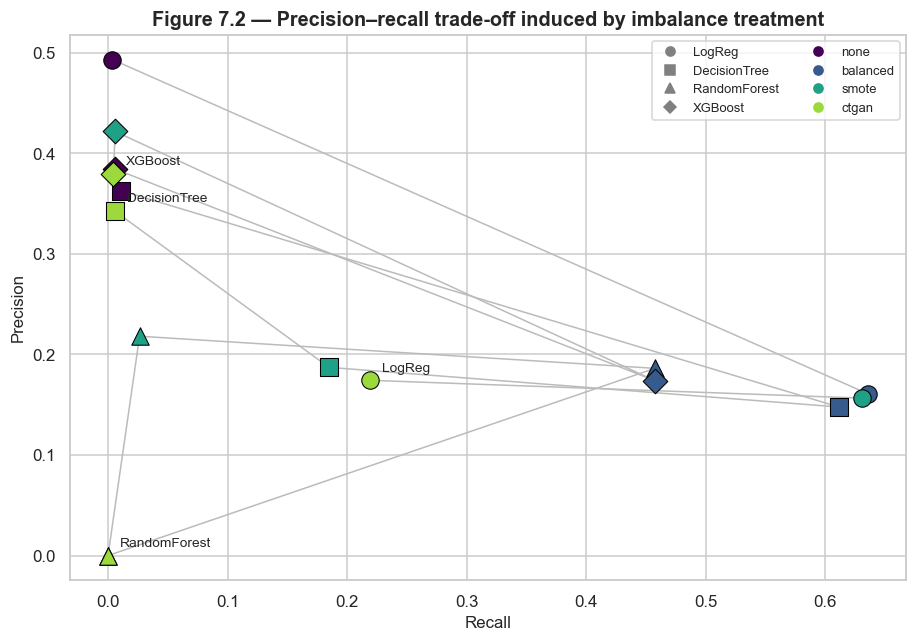

precision                        recall                       roc_auc                     
imbalance     balanced  ctgan   none  smote balanced  ctgan   none  smote balanced  ctgan   none  smote
model                                                                                                  
DecisionTree    0.1477 0.3423 0.3628 0.1871   0.6113 0.0058 0.0106 0.1848   0.6525 0.6618 0.6548 0.6257
LogReg          0.1605 0.1742 0.4930 0.1565   0.6361 0.2191 0.0036 0.6311   0.6862 0.6160 0.6863 0.6787
RandomForest    0.1861 0.0000 0.0000 0.2180   0.4575 0.0000 0.0000 0.0264   0.6785 0.6814 0.6818 0.6633
XGBoost         0.1738 0.3792 0.3842 0.4215   0.4575 0.0045 0.0058 0.0059   0.6629 0.6763 0.6693 0.6737

In [44]:
# ---- The precision/recall trade-off that oversampling induces --------------
piv = ABLATION.pivot_table(index="model", columns="imbalance",
                           values=["recall", "precision", "roc_auc"])
print("Recall and precision move in opposite directions as the effective class")
print("prior is shifted, while AUC (threshold-independent) is broadly stable —")
print("which is why section 7.7 treats AUC as the primary selection metric.\n")

fig, ax = plt.subplots(figsize=(8.5, 6))
mk = {"LogReg": "o", "DecisionTree": "s", "RandomForest": "^", "XGBoost": "D"}
for mdl in models_o:
    sub = ABLATION[ABLATION.model == mdl].set_index("imbalance").reindex(arms)
    ax.plot(sub.recall, sub.precision, "-", color="#BBBBBB", lw=1, zorder=1)
    for arm in arms:
        r = sub.loc[arm]
        ax.scatter(r.recall, r.precision, s=130, marker=mk[mdl],
                   color=colors[arm], edgecolor="black", lw=0.7, zorder=3)
    ax.annotate(mdl, (sub.recall.iloc[-1], sub.precision.iloc[-1]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)

from matplotlib.lines import Line2D
h1 = [Line2D([], [], marker=mk[m], ls="", color="grey", label=m) for m in models_o]
h2 = [Line2D([], [], marker="o", ls="", color=colors[a], label=a) for a in arms]
ax.legend(handles=h1 + h2, fontsize=8.5, ncol=2, loc="upper right")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Figure 7.2 — Precision–recall trade-off induced by imbalance treatment")
savefig("fig_7_2_precision_recall_tradeoff")
plt.show()

piv.round(4)

## 7.2 Deep learning baselines (§7.5, literature-informed configurations)

Following §7.6 and §10(a), these architectures are **not tuned**. The
configurations follow prior banking/telco churn studies: ReLU activations,
dropout regularisation, batch normalisation to stabilise training, Adam
optimiser, and a sigmoid output neuron for binary classification.

Two implementation points, both fixing defects present in the earlier notebook:

1. Early stopping and LR reduction monitor `val_auc`, and the model is compiled
   with `keras.metrics.AUC(name="auc")` so that metric **actually exists**. In
   the previous notebook the callbacks monitored a metric that was never
   compiled, so early stopping silently never fired.
2. Class weights are computed **per fold**, from that fold's training rows only.

In [45]:
import tensorflow as tf
from tensorflow import keras

def configure_tf(seed=RANDOM_STATE):
    keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism() if hasattr(
        tf.config.experimental, "enable_op_determinism") else None
    for g in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except Exception:
            pass

configure_tf()
print("TensorFlow", tf.__version__, "| devices:",
      [d.device_type for d in tf.config.list_physical_devices()])


def build_ann(input_dim, seed=RANDOM_STATE):
    """
    ANN baseline (section 7.5): 1-2 hidden layers, ReLU, dropout, sigmoid output.
    Configuration follows AbdelAziz et al. (2025) and Adamu et al. (2025).
    """
    configure_tf(seed)
    m = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, activation="sigmoid"),
    ], name="ANN")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"),
                       keras.metrics.Recall(name="recall")])
    return m


def build_dnn(input_dim, seed=RANDOM_STATE):
    """
    DNN baseline (section 7.5): 4-6 hidden layers with batch normalisation and
    dropout. Configuration follows Singh, H. et al. (2024) and Basit et al. (2024).
    """
    configure_tf(seed)
    m = keras.Sequential([keras.layers.Input(shape=(input_dim,))])
    for units, drop in [(256, 0.3), (128, 0.3), (64, 0.25), (64, 0.25), (32, 0.2)]:
        m.add(keras.layers.Dense(units, activation="relu"))
        m.add(keras.layers.BatchNormalization())
        m.add(keras.layers.Dropout(drop))
    m.add(keras.layers.Dense(1, activation="sigmoid"))
    m._name = "DNN"
    m.compile(optimizer=keras.optimizers.Adam(8e-4),
              loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc"),
                       keras.metrics.Recall(name="recall")])
    return m


build_ann(40).summary()
print()
build_dnn(40).summary()

TensorFlow 2.16.2 | devices: ['CPU']


Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │        10,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,097 (234.75 KB)

 Trainable params: 59,009 (230.50 KB)

 Non-trainable params: 1,088 (4.25 KB)

In [46]:
def evaluate_dl_cv(builders, X, y, n_splits=None, n_repeats=1, imbalance="balanced",
                   random_state=RANDOM_STATE, epochs=None, batch_size=None,
                   threshold=0.5, verbose=True):
    """
    Deep-learning CV using the SAME per-fold preprocessing as the ML models, so
    the ML-vs-DL comparison of research question 1 is genuinely like-for-like.

    Timing follows the section 7.7 Table 8 protocol and additionally reports
    seconds per epoch, which the proposal specifies for DL training.
    """
    from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
    epochs = epochs or DL_EPOCHS
    batch_size = batch_size or DL_BATCH_SIZE
    n_splits = n_splits or N_SPLITS

    splitter = (RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                        random_state=random_state)
                if n_repeats > 1 else
                StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state))

    rows = []
    for k, (tr, va) in enumerate(splitter.split(X, y)):
        rep, fold = divmod(k, n_splits)
        X_tr, X_va = X.iloc[tr], X.iloc[va]
        y_tr, y_va = y.iloc[tr].values.astype(int), y.iloc[va].values.astype(int)

        pre = FoldPreprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                               WINSORISE_COLS).fit(X_tr, y_tr)
        M_tr, M_va = pre.transform(X_tr), pre.transform(X_va)

        if str(imbalance).lower() in ("smote", "ctgan"):
            M_tr, y_tr = resample_training_fold(M_tr, y_tr, imbalance,
                                                random_state, pre.feature_names_)
            class_weight = None
        elif str(imbalance).lower() == "balanced":
            pos, neg = (y_tr == 1).sum(), (y_tr == 0).sum()
            tot = pos + neg
            class_weight = {0: tot / (2 * neg), 1: tot / (2 * pos)}
        else:
            class_weight = None

        callbacks = [
            keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                          patience=DL_PATIENCE, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max",
                                              factor=0.5, patience=3, min_lr=1e-5),
        ]

        for name, builder in builders.items():
            model = builder(M_tr.shape[1], seed=random_state)
            t0 = time.perf_counter()
            hist = model.fit(M_tr, y_tr, validation_data=(M_va, y_va),
                             epochs=epochs, batch_size=batch_size, verbose=0,
                             class_weight=class_weight, callbacks=callbacks)
            train_time = time.perf_counter() - t0
            n_epochs_run = len(hist.history["loss"])

            y_score = model.predict(M_va, verbose=0, batch_size=4096).ravel()
            y_pred = (y_score >= threshold).astype(int)

            row = {"model": name, "repeat": rep + 1, "fold": fold + 1,
                   "imbalance": imbalance, "train_time_sec": train_time,
                   "epochs_run": n_epochs_run,
                   "train_sec_per_epoch": train_time / max(n_epochs_run, 1),
                   "n_train": len(y_tr), "n_valid": len(va)}
            row.update(compute_metrics(y_va, y_pred, y_score))

            if k == 0:
                row.update(benchmark_inference(
                    lambda Z: model.predict(Z, verbose=0, batch_size=4096), M_va))
            rows.append(row)

            if verbose:
                print(f"  [{name:>22s}] rep{rep+1} fold{fold+1}  "
                      f"AUC={row['roc_auc']:.4f}  F1={row['f1']:.4f}  "
                      f"recall={row['recall']:.4f}  "
                      f"({n_epochs_run} epochs, {train_time:.0f}s)")
            keras.backend.clear_session()

    per_fold = pd.DataFrame(rows)
    agg = {m: ["mean", "std"] for m in
           ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]}
    agg["train_time_sec"] = ["mean"]
    agg["train_sec_per_epoch"] = ["mean"]
    agg["epochs_run"] = ["mean"]
    summary = per_fold.groupby("model").agg(agg)
    summary.columns = ["_".join(c).replace("_mean", "") for c in summary.columns]
    bench = [c for c in per_fold.columns if c.startswith("infer_")]
    if bench:
        summary = summary.join(per_fold.groupby("model")[bench].mean())
    summary = summary.sort_values("roc_auc", ascending=False).reset_index()
    summary.insert(1, "imbalance", imbalance)
    return per_fold, summary

In [47]:
# ---- Run the DL baselines --------------------------------------------------
print("Training ANN and DNN with per-fold class weighting...\n")
t0 = time.perf_counter()
DL_FOLDS, DL_SUMMARY = evaluate_dl_cv({"ANN": build_ann, "DNN": build_dnn},
                                      X_tune, y_tune, n_splits=N_SPLITS,
                                      imbalance="balanced", verbose=True)
print(f"\nTotal DL time: {time.perf_counter()-t0:.0f}s")
DL_SUMMARY.round(4)

Training ANN and DNN with per-fold class weighting...



  [                   ANN] rep1 fold1  AUC=0.6940  F1=0.2563  recall=0.6774  (17 epochs, 5s)


  [                   DNN] rep1 fold1  AUC=0.6614  F1=0.2507  recall=0.4894  (6 epochs, 7s)


  [                   ANN] rep1 fold2  AUC=0.6831  F1=0.2513  recall=0.6598  (21 epochs, 6s)


  [                   DNN] rep1 fold2  AUC=0.6567  F1=0.2407  recall=0.5852  (6 epochs, 8s)


  [                   ANN] rep1 fold3  AUC=0.6812  F1=0.2529  recall=0.6378  (16 epochs, 5s)


... (2 outputs left out)

  [                   DNN] rep1 fold4  AUC=0.6504  F1=0.2393  recall=0.4625  (6 epochs, 6s)


  [                   ANN] rep1 fold5  AUC=0.6859  F1=0.2562  recall=0.6539  (13 epochs, 3s)


  [                   DNN] rep1 fold5  AUC=0.6459  F1=0.2393  recall=0.4237  (6 epochs, 7s)

Total DL time: 63s


,model,imbalance,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std,train_time_sec,train_sec_per_epoch,epochs_run,infer_total_p50_s,infer_total_p90_s,infer_ms_per_sample,infer_ci95_s,infer_n_runs
0,ANN,balanced,0.6166,0.0076,0.1565,0.0028,0.6524,0.0178,0.2525,0.0044,0.6832,0.0081,0.1989,0.0085,4.1793,0.2736,15.2000,0.0464,0.0504,0.0023,0.0019,10.0000
1,DNN,balanced,0.6913,0.0388,0.1614,0.0068,0.4993,0.0630,0.2430,0.0049,0.6535,0.0059,0.1712,0.0053,6.9075,1.1513,6.0000,0.0684,0.0742,0.0034,0.0031,10.0000


## 7.3 Unified ML + DL leaderboard (research question 1)

In [48]:
# Pick the best imbalance arm per ML model by AUC, then combine with DL
best_ml = (ABLATION.sort_values("roc_auc", ascending=False)
                   .groupby("model", as_index=False).first())
best_ml["family"] = "ML"
dl = DL_SUMMARY.copy(); dl["family"] = "DL"

LB_COLS = ["model", "family", "imbalance", "roc_auc", "pr_auc", "f1", "recall",
           "precision", "accuracy", "train_time_sec", "infer_ms_per_sample"]
LEADERBOARD = (pd.concat([best_ml.reindex(columns=LB_COLS),
                          dl.reindex(columns=LB_COLS)], ignore_index=True)
                 .sort_values(["roc_auc", "f1"], ascending=False)
                 .reset_index(drop=True))
LEADERBOARD.to_csv("results_baseline_leaderboard.csv", index=False)
LEADERBOARD.round(4)

,model,family,imbalance,roc_auc,pr_auc,f1,recall,precision,accuracy,train_time_sec,infer_ms_per_sample
0,LogReg,ML,none,0.6863,0.2005,0.0072,0.0036,0.4930,0.9008,0.6415,0.0018
1,ANN,DL,balanced,0.6832,0.1989,0.2525,0.6524,0.1565,0.6166,4.1793,0.0023
2,RandomForest,ML,none,0.6818,0.1990,0.0000,0.0000,0.0000,0.9008,8.6551,0.0064
3,XGBoost,ML,ctgan,0.6763,0.1925,0.0090,0.0045,0.3792,0.9004,3.1149,0.0027
4,DecisionTree,ML,ctgan,0.6618,0.1736,0.0115,0.0058,0.3423,0.9002,2.4751,0.0019
5,DNN,DL,balanced,0.6535,0.1712,0.2430,0.4993,0.1614,0.6913,6.9075,0.0034


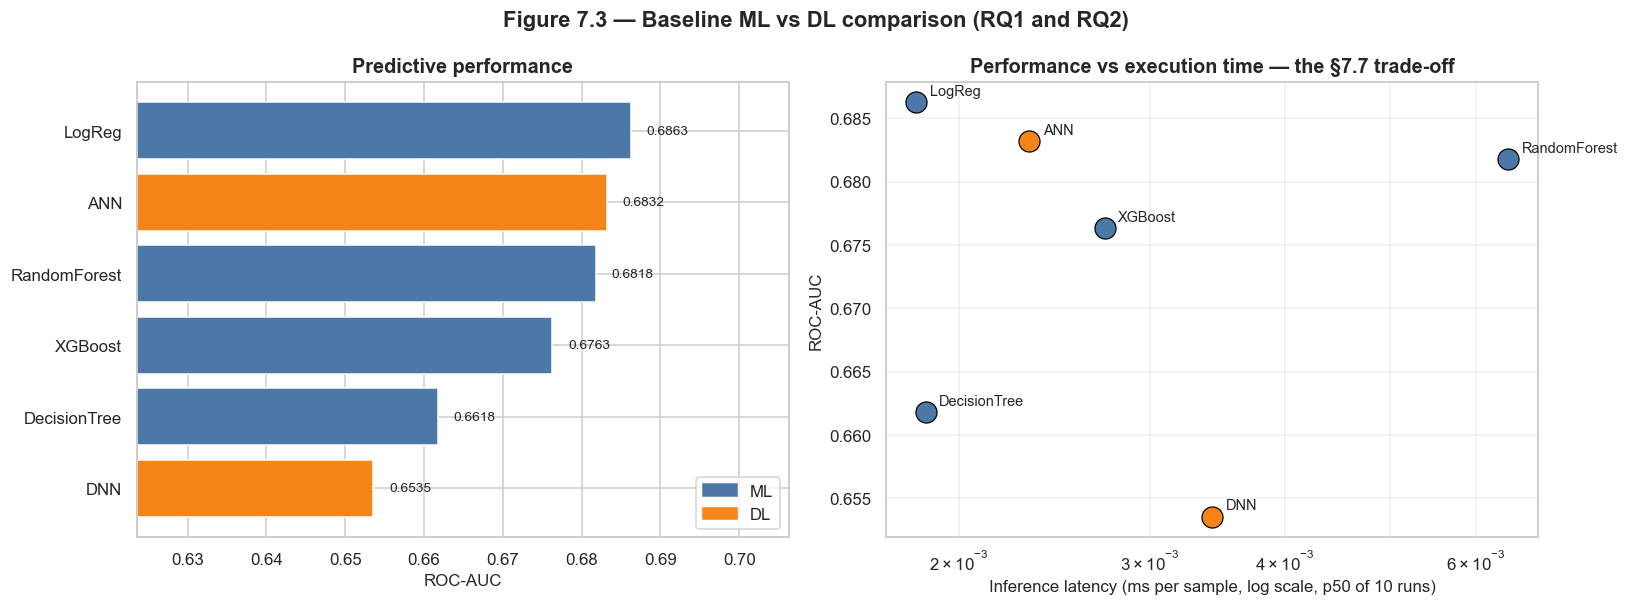

In [49]:
# ---- Figure: performance vs execution time (research question 2) ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

lb = LEADERBOARD.sort_values("roc_auc")
cols = [C_ML if f == "ML" else C_DL for f in lb.family]
axes[0].barh(lb.model, lb.roc_auc, color=cols, edgecolor="white")
for y, (v, f1) in enumerate(zip(lb.roc_auc, lb.f1)):
    axes[0].text(v + 0.002, y, f"{v:.4f}", va="center", fontsize=9)
axes[0].set_xlim(max(0.5, lb.roc_auc.min() - 0.03), lb.roc_auc.max() + 0.02)
axes[0].set_xlabel("ROC-AUC")
axes[0].set_title("Predictive performance")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=C_ML, label="ML"), Patch(color=C_DL, label="DL")],
               loc="lower right")

for _, r in LEADERBOARD.iterrows():
    c = C_ML if r.family == "ML" else C_DL
    axes[1].scatter(r.infer_ms_per_sample, r.roc_auc, s=190, color=c,
                    edgecolor="black", lw=0.8, zorder=3)
    axes[1].annotate(r.model, (r.infer_ms_per_sample, r.roc_auc),
                     textcoords="offset points", xytext=(9, 5), fontsize=9.5)
axes[1].set_xscale("log")
axes[1].set_xlabel("Inference latency (ms per sample, log scale, p50 of 10 runs)")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("Performance vs execution time — the §7.7 trade-off")
axes[1].grid(True, which="both", alpha=0.3)

fig.suptitle("Figure 7.3 — Baseline ML vs DL comparison (RQ1 and RQ2)",
             fontweight="semibold")
savefig("fig_7_3_baseline_leaderboard")
plt.show()

---
# Part 8 — Hyperparameter optimisation (§7.6)

§7.6 requires comparing **three** search strategies on the ML models:

| Strategy | Mechanism | Expected behaviour (§7.6 Table 7) |
|---|---|---|
| **Grid Search** | Exhaustive over a predefined grid | Guaranteed best-within-grid; cost explodes with dimensionality |
| **Random Search** | Random draws from distributions | More efficient in high dimensions; may miss the optimum |
| **Optuna** | Bayesian (TPE) + pruning of poor trials | Adaptive; best efficiency in large, complex spaces |

DL models are excluded from tuning by §7.6 and §10(a).

**Search objective.** Optimisation targets **ROC-AUC**. Because §7.7 privileges
recall for business reasons but oversampling can trade precision for recall
arbitrarily at a fixed threshold, tuning on a threshold-independent metric and
then selecting an operating threshold (§8.5) is the methodologically sound
ordering.

All searches run on the stratified `X_tune` subsample; §8.4 refits the winners on
the full training set.

## 8.1 Search spaces

Grid spaces are deliberately compact so that Grid Search remains genuinely
*exhaustive within its stated bounds* — the property that justifies its inclusion
at all. Random and Optuna spaces cover the same regions but continuously, so the
comparison isolates search *strategy* rather than search *range*.

In [50]:
from scipy.stats import loguniform, randint, uniform

P = "base_estimator__"   # parameters are nested inside LeakageSafeClassifier

GRID_SPACES = {
    "LogReg": {
        f"{P}C": [0.01, 0.1, 1.0, 10.0],
        f"{P}penalty": ["l2"],
        "imbalance": ["none", "balanced", "smote"],
    },
    "DecisionTree": {
        f"{P}max_depth": [4, 6, 8, 12],
        f"{P}min_samples_leaf": [20, 50, 200],
        "imbalance": ["none", "balanced", "smote"],
    },
    "RandomForest": {
        f"{P}n_estimators": [200, 400],
        f"{P}max_depth": [8, 12, 16],
        f"{P}min_samples_leaf": [10, 50],
        "imbalance": ["none", "balanced"],
    },
    "XGBoost": {
        f"{P}n_estimators": [200, 400],
        f"{P}max_depth": [4, 6, 8],
        f"{P}learning_rate": [0.05, 0.1],
        "imbalance": ["none", "balanced"],
    },
}

RANDOM_SPACES = {
    "LogReg": {
        f"{P}C": loguniform(1e-3, 1e2),
        "imbalance": ["none", "balanced", "smote"],
    },
    "DecisionTree": {
        f"{P}max_depth": randint(3, 20),
        f"{P}min_samples_leaf": randint(10, 400),
        f"{P}min_samples_split": randint(2, 200),
        "imbalance": ["none", "balanced", "smote"],
    },
    "RandomForest": {
        f"{P}n_estimators": randint(150, 600),
        f"{P}max_depth": randint(6, 22),
        f"{P}min_samples_leaf": randint(5, 100),
        f"{P}max_features": ["sqrt", "log2", 0.5],
        "imbalance": ["none", "balanced"],
    },
    "XGBoost": {
        f"{P}n_estimators": randint(150, 700),
        f"{P}max_depth": randint(3, 10),
        f"{P}learning_rate": loguniform(0.01, 0.3),
        f"{P}subsample": uniform(0.6, 0.4),
        f"{P}colsample_bytree": uniform(0.6, 0.4),
        f"{P}reg_lambda": loguniform(0.1, 20),
        "imbalance": ["none", "balanced"],
    },
}

grid_sizes = {m: int(np.prod([len(v) for v in s.values()])) for m, s in GRID_SPACES.items()}
print("Grid combinations per model (x", N_SPLITS, "folds = total fits):")
for m, n in grid_sizes.items():
    print(f"  {m:14s} {n:>4} combinations -> {n*N_SPLITS:>5} fits")
print(f"\nTotal grid fits: {sum(grid_sizes.values())*N_SPLITS:,}")

Grid combinations per model (x 5 folds = total fits):
  LogReg           12 combinations ->    60 fits
  DecisionTree     36 combinations ->   180 fits
  RandomForest     24 combinations ->   120 fits
  XGBoost          24 combinations ->   120 fits

Total grid fits: 480


In [51]:
def make_wrapped(name, **overrides):
    """Build an unfitted LeakageSafeClassifier around one of the section 7.5 models."""
    base = ml_models()[name]
    if overrides:
        base.set_params(**overrides)
    return LeakageSafeClassifier(
        base_estimator=base,
        numeric_features=NUMERIC_FEATURES,
        categorical_features=CATEGORICAL_FEATURES,
        winsorise_cols=WINSORISE_COLS,
        imbalance="none",
        random_state=RANDOM_STATE,
    )

## 8.2 Grid Search and Random Search

In [52]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

CV_SEARCH = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
SCORING = "roc_auc"
N_RANDOM_ITER = 25

def run_search(kind, model_name, X, y, n_iter=N_RANDOM_ITER):
    """Run one search strategy for one model and record wall-clock search cost."""
    est = make_wrapped(model_name)
    if kind == "grid":
        search = GridSearchCV(est, GRID_SPACES[model_name], scoring=SCORING,
                              cv=CV_SEARCH, n_jobs=1, refit=True, verbose=0)
    elif kind == "random":
        search = RandomizedSearchCV(est, RANDOM_SPACES[model_name], n_iter=n_iter,
                                    scoring=SCORING, cv=CV_SEARCH, n_jobs=1,
                                    random_state=RANDOM_STATE, refit=True, verbose=0)
    else:
        raise ValueError(kind)

    t0 = time.perf_counter()
    search.fit(X, y)
    elapsed = time.perf_counter() - t0
    n_fits = len(search.cv_results_["params"]) * N_SPLITS

    # Fail loudly rather than selecting hyperparameters from NaN scores
    if not np.isfinite(search.best_score_):
        raise RuntimeError(
            f"{kind} search on {model_name} produced a non-finite best score "
            f"({search.best_score_}). Every fold scored NaN, so the selected "
            f"configuration would be arbitrary. Check that the estimator is "
            f"recognised by sklearn.base.is_classifier."
        )

    return {
        "model": model_name, "search": kind,
        "best_score_auc": search.best_score_,
        "best_params": search.best_params_,
        "search_time_sec": elapsed,
        "n_configs": len(search.cv_results_["params"]),
        "n_fits": n_fits,
        "sec_per_fit": elapsed / n_fits,
        "estimator": search.best_estimator_,
    }

In [53]:
SEARCH_RESULTS = []
MODELS_TO_TUNE = ["LogReg", "DecisionTree", "RandomForest", "XGBoost"]

for kind in ["grid", "random"]:
    for name in MODELS_TO_TUNE:
        print(f"[{kind:6s}] {name} ...", end=" ", flush=True)
        r = run_search(kind, name, X_tune, y_tune)
        SEARCH_RESULTS.append(r)
        print(f"AUC={r['best_score_auc']:.4f}  "
              f"{r['n_configs']} configs / {r['n_fits']} fits  "
              f"{r['search_time_sec']:.0f}s")

pd.DataFrame([{k: v for k, v in r.items() if k != "estimator"}
              for r in SEARCH_RESULTS]).round(4)

[grid  ] LogReg ... 

AUC=0.6865  12 configs / 60 fits  66s
[grid  ] DecisionTree ... 

AUC=0.6682  36 configs / 180 fits  385s
[grid  ] RandomForest ... 

AUC=0.6830  24 configs / 120 fits  1344s
[grid  ] XGBoost ... 

AUC=0.6836  24 configs / 120 fits  356s
[random] LogReg ... 

AUC=0.6866  25 configs / 125 fits  185s
[random] DecisionTree ... 

AUC=0.6670  25 configs / 125 fits  382s
[random] RandomForest ... 

AUC=0.6827  25 configs / 125 fits  2899s
[random] XGBoost ... 

AUC=0.6855  25 configs / 125 fits  890s


,model,search,best_score_auc,best_params,search_time_sec,n_configs,n_fits,sec_per_fit
0,LogReg,grid,0.6865,"{'base_estimator__C': 0.01, 'base_estimator__p...",66.1807,12,60,1.1030
1,DecisionTree,grid,0.6682,"{'base_estimator__max_depth': 6, 'base_estimat...",385.4242,36,180,2.1412
2,RandomForest,grid,0.6830,"{'base_estimator__max_depth': 8, 'base_estimat...","1,343.9364",24,120,11.1995
3,XGBoost,grid,0.6836,"{'base_estimator__learning_rate': 0.05, 'base_...",355.7021,24,120,2.9642
4,LogReg,random,0.6866,"{'base_estimator__C': 0.0021147447960615704, '...",185.2303,25,125,1.4818
5,DecisionTree,random,0.6670,"{'base_estimator__max_depth': 4, 'base_estimat...",382.1660,25,125,3.0573
6,RandomForest,random,0.6827,"{'base_estimator__max_depth': 8, 'base_estimat...","2,899.0194",25,125,23.1922
7,XGBoost,random,0.6855,{'base_estimator__colsample_bytree': 0.8446612...,890.1362,25,125,7.1211


## 8.3 Optuna (Bayesian optimisation with pruning)

In [54]:
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_OPTUNA_TRIALS = 30

def optuna_space(trial, name):
    """Mirror the random-search ranges so the comparison isolates strategy."""
    if name == "LogReg":
        return dict(params={"C": trial.suggest_float("C", 1e-3, 1e2, log=True)},
                    imbalance=trial.suggest_categorical("imbalance", ["none", "balanced", "smote"]))
    if name == "DecisionTree":
        return dict(params={
                        "max_depth": trial.suggest_int("max_depth", 3, 20),
                        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 400),
                        "min_samples_split": trial.suggest_int("min_samples_split", 2, 200)},
                    imbalance=trial.suggest_categorical("imbalance", ["none", "balanced", "smote"]))
    if name == "RandomForest":
        return dict(params={
                        "n_estimators": trial.suggest_int("n_estimators", 150, 600, step=50),
                        "max_depth": trial.suggest_int("max_depth", 6, 22),
                        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 100),
                        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5])},
                    imbalance=trial.suggest_categorical("imbalance", ["none", "balanced"]))
    if name == "XGBoost":
        return dict(params={
                        "n_estimators": trial.suggest_int("n_estimators", 150, 700, step=50),
                        "max_depth": trial.suggest_int("max_depth", 3, 10),
                        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20, log=True)},
                    imbalance=trial.suggest_categorical("imbalance", ["none", "balanced"]))
    raise ValueError(name)


def run_optuna(model_name, X, y, n_trials=N_OPTUNA_TRIALS):
    def objective(trial):
        spec = optuna_space(trial, model_name)
        est = make_wrapped(model_name, **spec["params"])
        est.set_params(imbalance=spec["imbalance"])
        scores = cross_val_score(est, X, y, scoring=SCORING, cv=CV_SEARCH, n_jobs=1)
        return float(scores.mean())

    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=RANDOM_STATE),
        pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=0),
        study_name=f"{model_name}_auc",
    )
    t0 = time.perf_counter()
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    elapsed = time.perf_counter() - t0

    bp = dict(study.best_params)
    imb = bp.pop("imbalance", "none")
    best = make_wrapped(model_name, **bp)
    best.set_params(imbalance=imb)
    best.fit(X, y)

    return {
        "model": model_name, "search": "optuna",
        "best_score_auc": study.best_value,
        "best_params": {f"{P}{k}": v for k, v in bp.items()} | {"imbalance": imb},
        "search_time_sec": elapsed,
        "n_configs": len(study.trials),
        "n_fits": len(study.trials) * N_SPLITS,
        "sec_per_fit": elapsed / (len(study.trials) * N_SPLITS),
        "estimator": best,
        "study": study,
    }


for name in MODELS_TO_TUNE:
    print(f"[optuna] {name} ...", end=" ", flush=True)
    r = run_optuna(name, X_tune, y_tune)
    SEARCH_RESULTS.append(r)
    print(f"AUC={r['best_score_auc']:.4f}  {r['n_configs']} trials  "
          f"{r['search_time_sec']:.0f}s")

[optuna] LogReg ... 

AUC=0.6866  30 trials  338s
[optuna] DecisionTree ... 

AUC=0.6671  30 trials  430s
[optuna] RandomForest ... 

AUC=0.6832  30 trials  2534s
[optuna] XGBoost ... 

AUC=0.6857  30 trials  414s


In [55]:
# ---- Research question 4: which search strategy wins, and at what cost? ----
SEARCH_DF = pd.DataFrame([{k: v for k, v in r.items()
                           if k not in ("estimator", "study")} for r in SEARCH_RESULTS])
SEARCH_DF["auc_per_minute"] = SEARCH_DF.best_score_auc / (SEARCH_DF.search_time_sec / 60)

baseline_auc = ABLATION[ABLATION.imbalance == "none"].set_index("model").roc_auc
SEARCH_DF["baseline_auc"] = SEARCH_DF.model.map(baseline_auc)
SEARCH_DF["auc_gain"] = SEARCH_DF.best_score_auc - SEARCH_DF.baseline_auc

SEARCH_DF.to_csv("results_hyperparameter_search.csv", index=False)
(SEARCH_DF[["model", "search", "best_score_auc", "baseline_auc", "auc_gain",
            "n_configs", "n_fits", "search_time_sec", "sec_per_fit"]]
   .sort_values(["model", "search"]).round(5))

,model,search,best_score_auc,baseline_auc,auc_gain,n_configs,n_fits,search_time_sec,sec_per_fit
1,DecisionTree,grid,0.6682,0.6548,0.0134,36,180,385.4242,2.1412
9,DecisionTree,optuna,0.6671,0.6548,0.0123,30,150,429.8650,2.8658
5,DecisionTree,random,0.6670,0.6548,0.0122,25,125,382.1660,3.0573
0,LogReg,grid,0.6865,0.6863,0.0003,12,60,66.1807,1.1030
8,LogReg,optuna,0.6865,0.6863,0.0003,30,150,338.3108,2.2554
4,LogReg,random,0.6866,0.6863,0.0004,25,125,185.2303,1.4818
2,RandomForest,grid,0.6830,0.6818,0.0013,24,120,"1,343.9364",11.1995
10,RandomForest,optuna,0.6832,0.6818,0.0014,30,150,"2,534.4327",16.8962
6,RandomForest,random,0.6827,0.6818,0.0009,25,125,"2,899.0194",23.1922
3,XGBoost,grid,0.6836,0.6693,0.0143,24,120,355.7021,2.9642


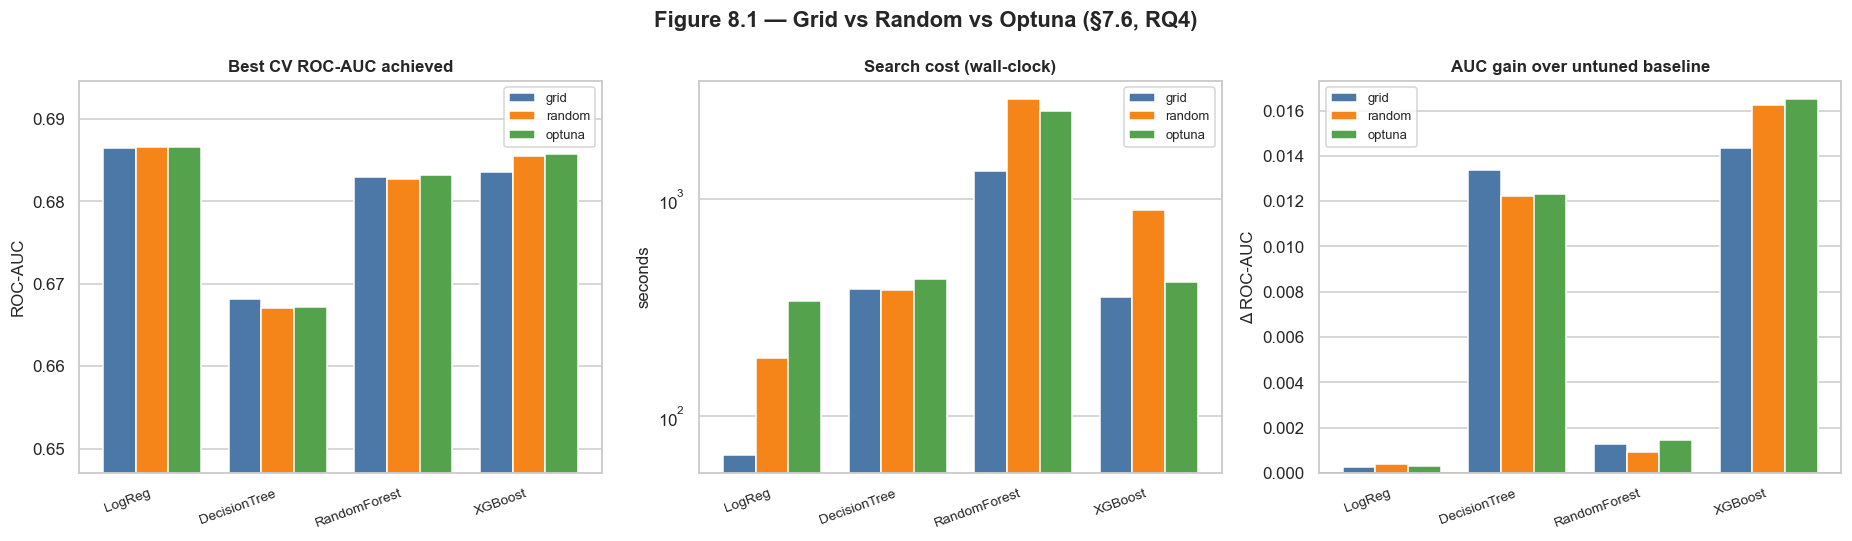

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
order = MODELS_TO_TUNE
kinds = ["grid", "random", "optuna"]
kcol = {"grid": "#4C78A8", "random": "#F58518", "optuna": "#54A24B"}
w = 0.26

for j, k in enumerate(kinds):
    sub = SEARCH_DF[SEARCH_DF.search == k].set_index("model").reindex(order)
    xs = np.arange(len(order)) + (j - 1) * w
    axes[0].bar(xs, sub.best_score_auc, width=w, label=k, color=kcol[k], edgecolor="white")
    axes[1].bar(xs, sub.search_time_sec, width=w, label=k, color=kcol[k], edgecolor="white")
    axes[2].bar(xs, sub.auc_gain, width=w, label=k, color=kcol[k], edgecolor="white")

for ax, title, ylab in zip(
        axes,
        ["Best CV ROC-AUC achieved", "Search cost (wall-clock)", "AUC gain over untuned baseline"],
        ["ROC-AUC", "seconds", "Δ ROC-AUC"]):
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=20, ha="right", fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylab)
    ax.legend(fontsize=8.5)
    ax.grid(axis="x", visible=False)

_fin = SEARCH_DF.best_score_auc[np.isfinite(SEARCH_DF.best_score_auc)]
if len(_fin):
    axes[0].set_ylim(_fin.min() - 0.02, _fin.max() + 0.008)
axes[1].set_yscale("log")
axes[2].axhline(0, color="black", lw=1)

fig.suptitle("Figure 8.1 — Grid vs Random vs Optuna (§7.6, RQ4)", fontweight="semibold")
savefig("fig_8_1_search_comparison")
plt.show()

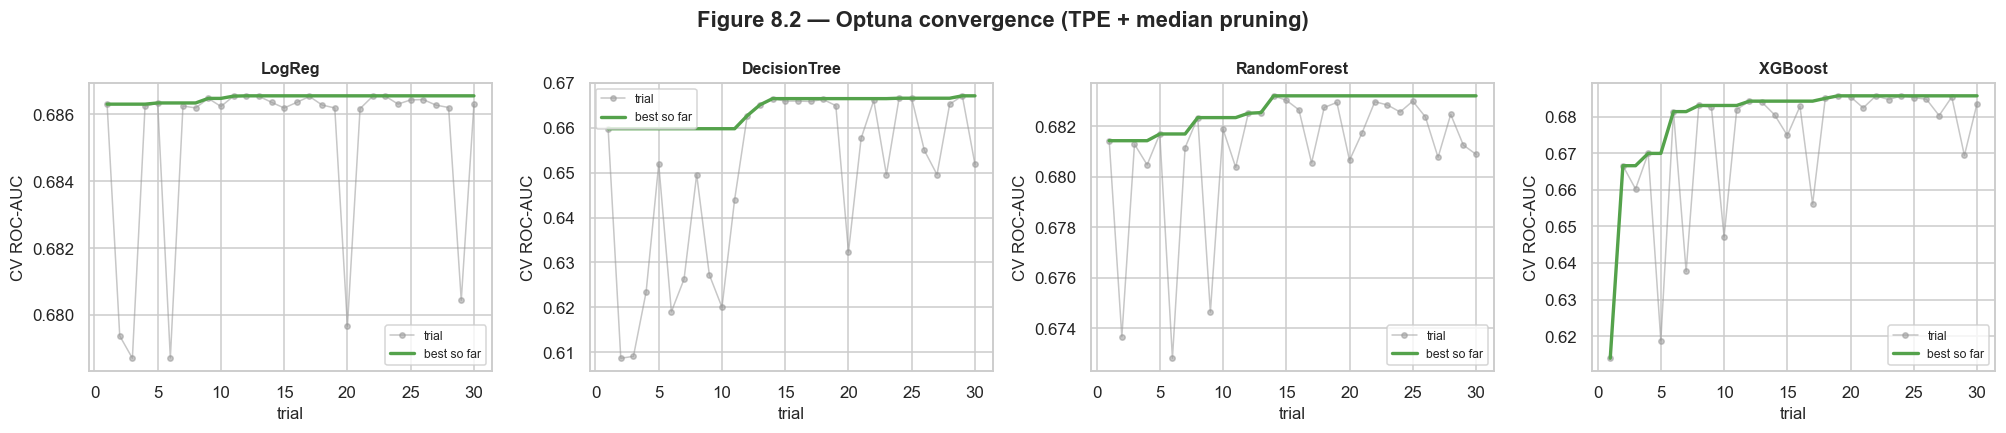

Hyperparameter importance (Optuna fANOVA):



  LogReg:
    imbalance                1.000
    C                        0.000

  DecisionTree:
    imbalance                0.520
    min_samples_leaf         0.234
    max_depth                0.199
    min_samples_split        0.047



  RandomForest:
    min_samples_leaf         0.722
    max_features             0.160
    max_depth                0.072
    n_estimators             0.037
    imbalance                0.009

  XGBoost:
    learning_rate            0.772
    max_depth                0.092
    colsample_bytree         0.063
    reg_lambda               0.028
    n_estimators             0.022
    subsample                0.018


In [57]:
# ---- Optuna convergence and hyperparameter importance ---------------------
studies = {r["model"]: r["study"] for r in SEARCH_RESULTS if r["search"] == "optuna"}
if not studies:
    raise RuntimeError("No Optuna studies were recorded — re-run §8.3 before this cell.")

fig, axes = plt.subplots(1, len(studies), figsize=(4.6 * len(studies), 4), squeeze=False)
axes = axes.ravel()
for ax, (name, st) in zip(axes, studies.items()):
    vals = [t.value for t in st.trials if t.value is not None]
    ax.plot(range(1, len(vals) + 1), vals, "o-", ms=3.5, lw=1, alpha=0.55,
            color="#999999", label="trial")
    ax.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), lw=2.2,
            color="#54A24B", label="best so far")
    ax.set_title(name, fontsize=10.5)
    ax.set_xlabel("trial"); ax.set_ylabel("CV ROC-AUC")
    ax.legend(fontsize=8)
fig.suptitle("Figure 8.2 — Optuna convergence (TPE + median pruning)", fontweight="semibold")
savefig("fig_8_2_optuna_convergence")
plt.show()

print("Hyperparameter importance (Optuna fANOVA):")
for name, st in studies.items():
    try:
        imp = optuna.importance.get_param_importances(st)
        print(f"\n  {name}:")
        for p, v in list(imp.items())[:6]:
            print(f"    {p:24s} {v:.3f}")
    except Exception as e:
        print(f"  {name}: unavailable ({e})")

## 8.4 Refit the winning configurations on the full training set

Per the compute protocol, each model's best configuration — selected on the
100k subsample — is now refit and re-evaluated on the **full 800k training set**
via 5-fold CV. Both sets of numbers are reported so the effect of the subsampling
decision is transparent and auditable.

In [58]:
# Best search strategy per model, by CV AUC on the tuning subsample
BEST_PER_MODEL = (SEARCH_DF.sort_values("best_score_auc", ascending=False)
                           .groupby("model", as_index=False).first())
print("Winning search strategy per model:")
print(BEST_PER_MODEL[["model", "search", "best_score_auc", "search_time_sec"]]
      .round(4).to_string(index=False))

BEST_ESTIMATORS = {}
for _, r in BEST_PER_MODEL.iterrows():
    src = next(x for x in SEARCH_RESULTS
               if x["model"] == r.model and x["search"] == r.search)
    BEST_ESTIMATORS[r.model] = (src["best_params"], r.search)

print("\nSelected hyperparameters:")
for m, (p, s) in BEST_ESTIMATORS.items():
    print(f"  {m} (via {s}):")
    for k, v in p.items():
        print(f"      {k.replace(P,''):22s} {v}")

Winning search strategy per model:
       model search  best_score_auc  search_time_sec
DecisionTree   grid          0.6682         385.4242
      LogReg random          0.6866         185.2303
RandomForest optuna          0.6832       2,534.4328
     XGBoost optuna          0.6857         413.5103

Selected hyperparameters:
  DecisionTree (via grid):
      max_depth              6
      min_samples_leaf       200
      imbalance              balanced
  LogReg (via random):
      C                      0.0021147447960615704
      imbalance              none
  RandomForest (via optuna):
      n_estimators           500
      max_depth              10
      min_samples_leaf       66
      max_features           log2
      imbalance              none
  XGBoost (via optuna):
      n_estimators           400
      max_depth              3
      learning_rate          0.017850705608912134
      subsample              0.7967011288841799
      colsample_bytree       0.761788250531769
      reg

In [59]:
# ---- Refit tuned models on the FULL training set ---------------------------
def build_from_params(model_name, params):
    est_params = {k.replace(P, ""): v for k, v in params.items() if k.startswith(P)}
    imb = params.get("imbalance", "none")
    base = ml_models()[model_name]
    base.set_params(**est_params)
    return base, imb

tuned_folds, tuned_summaries = [], []
for name, (params, search) in BEST_ESTIMATORS.items():
    base, imb = build_from_params(name, params)
    label = f"{name}-{search}"
    print(f"\n=== {label} on full training set ({len(X_train):,} rows), imbalance={imb} ===")
    t0 = time.perf_counter()
    pf, sm = evaluate_cv({label: base}, X_train, y_train, n_splits=N_SPLITS,
                         imbalance=imb, verbose=True)
    print(f"  -> AUC {sm.roc_auc.iloc[0]:.4f}   ({time.perf_counter()-t0:.0f}s)")
    pf["search"] = search; sm["search"] = search
    tuned_folds.append(pf); tuned_summaries.append(sm)

TUNED_FOLDS = pd.concat(tuned_folds, ignore_index=True)
TUNED = pd.concat(tuned_summaries, ignore_index=True).sort_values("roc_auc", ascending=False)
TUNED.to_csv("results_tuned_full.csv", index=False)
TUNED.round(4)


=== DecisionTree-grid on full training set (800,000 rows), imbalance=balanced ===


  [     DecisionTree-grid] rep1 fold1  AUC=0.6727  F1=0.2486  recall=0.6352  (13.5s)


  [     DecisionTree-grid] rep1 fold2  AUC=0.6787  F1=0.2515  recall=0.6382  (21.1s)


  [     DecisionTree-grid] rep1 fold3  AUC=0.6728  F1=0.2513  recall=0.5932  (21.4s)


  [     DecisionTree-grid] rep1 fold4  AUC=0.6738  F1=0.2477  recall=0.6558  (21.4s)


  [     DecisionTree-grid] rep1 fold5  AUC=0.6732  F1=0.2470  recall=0.6518  (21.1s)
  -> AUC 0.6742   (108s)

=== LogReg-random on full training set (800,000 rows), imbalance=none ===


... (12 outputs left out)

  [        XGBoost-optuna] rep1 fold3  AUC=0.6843  F1=0.0044  recall=0.0022  (27.6s)


  [        XGBoost-optuna] rep1 fold4  AUC=0.6857  F1=0.0025  recall=0.0013  (28.1s)


  [        XGBoost-optuna] rep1 fold5  AUC=0.6846  F1=0.0040  recall=0.0020  (28.5s)
  -> AUC 0.6858   (150s)


,model,imbalance,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std,train_time_sec,infer_total_p50_s,infer_total_p90_s,infer_ms_per_sample,infer_ci95_s,infer_n_runs,search
1,LogReg-random,none,0.9008,0.0001,0.5626,0.0523,0.0035,0.0004,0.0070,0.0008,0.6861,0.0023,0.2030,0.0029,12.4750,0.5005,0.5535,0.0031,0.0608,10.0000,random
3,XGBoost-optuna,none,0.9008,0.0000,0.6859,0.1016,0.0015,0.0006,0.0031,0.0011,0.6858,0.0021,0.2046,0.0027,27.8413,0.5882,0.6137,0.0037,0.0468,10.0000,optuna
2,RandomForest-optuna,none,0.9008,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6836,0.0024,0.2017,0.0029,197.1161,1.8816,2.0154,0.0118,0.1394,10.0000,optuna
0,DecisionTree-grid,balanced,0.6203,0.0181,0.1551,0.0029,0.6348,0.0248,0.2492,0.0021,0.6742,0.0025,0.1850,0.0016,19.6827,0.4343,0.4860,0.0027,0.0249,10.0000,grid


In [60]:
# ---- DL on the full training set (same conditions, no tuning) -------------
print(f"Training ANN and DNN on the full {len(X_train):,}-row training set...\n")
t0 = time.perf_counter()
DL_FOLDS_FULL, DL_FULL = evaluate_dl_cv({"ANN": build_ann, "DNN": build_dnn},
                                        X_train, y_train, n_splits=N_SPLITS,
                                        imbalance="balanced", verbose=True)
print(f"\nTotal: {time.perf_counter()-t0:.0f}s")
DL_FULL.round(4)

Training ANN and DNN on the full 800,000-row training set...



  [                   ANN] rep1 fold1  AUC=0.6848  F1=0.2535  recall=0.6584  (15 epochs, 52s)


  [                   DNN] rep1 fold1  AUC=0.6850  F1=0.2530  recall=0.6638  (10 epochs, 137s)


  [                   ANN] rep1 fold2  AUC=0.6891  F1=0.2552  recall=0.6624  (10 epochs, 36s)


  [                   DNN] rep1 fold2  AUC=0.6893  F1=0.2564  recall=0.6465  (13 epochs, 173s)


  [                   ANN] rep1 fold3  AUC=0.6837  F1=0.2538  recall=0.6515  (13 epochs, 45s)


... (3 outputs left out)

  [                   ANN] rep1 fold5  AUC=0.6844  F1=0.2532  recall=0.6404  (12 epochs, 41s)


  [                   DNN] rep1 fold5  AUC=0.6819  F1=0.2506  recall=0.6651  (6 epochs, 88s)



Total: 1043s


,model,imbalance,accuracy,accuracy_std,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std,train_time_sec,train_sec_per_epoch,epochs_run,infer_total_p50_s,infer_total_p90_s,infer_ms_per_sample,infer_ci95_s,infer_n_runs
0,ANN,balanced,0.6172,0.0059,0.1573,0.0009,0.6556,0.0100,0.2537,0.0010,0.6854,0.0021,0.2031,0.0028,42.6583,3.4449,12.4000,0.2039,0.2136,0.0013,0.0067,10.0000
1,DNN,balanced,0.6165,0.0089,0.1570,0.0020,0.6551,0.0091,0.2532,0.0021,0.6851,0.0027,0.2028,0.0032,153.7723,13.4612,11.6000,0.6358,0.6658,0.0040,0.0333,10.0000


In [61]:
# ---- The headline comparison table -----------------------------------------
FINAL_COLS = ["model", "family", "roc_auc", "roc_auc_std", "pr_auc", "f1", "recall",
              "precision", "accuracy", "train_time_sec", "infer_ms_per_sample"]

_t = TUNED.copy(); _t["family"] = "ML (tuned)"
_d = DL_FULL.copy(); _d["family"] = "DL (untuned, §7.6)"
FINAL = (pd.concat([_t.reindex(columns=FINAL_COLS), _d.reindex(columns=FINAL_COLS)],
                   ignore_index=True)
           .sort_values("roc_auc", ascending=False).reset_index(drop=True))
FINAL.to_csv("results_final_leaderboard.csv", index=False)
FINAL.round(4)

,model,family,roc_auc,roc_auc_std,pr_auc,f1,recall,precision,accuracy,train_time_sec,infer_ms_per_sample
0,LogReg-random,ML (tuned),0.6861,0.0023,0.2030,0.0070,0.0035,0.5626,0.9008,12.4750,0.0031
1,XGBoost-optuna,ML (tuned),0.6858,0.0021,0.2046,0.0031,0.0015,0.6859,0.9008,27.8413,0.0037
2,ANN,"DL (untuned, §7.6)",0.6854,0.0021,0.2031,0.2537,0.6556,0.1573,0.6172,42.6583,0.0013
3,DNN,"DL (untuned, §7.6)",0.6851,0.0027,0.2028,0.2532,0.6551,0.1570,0.6165,153.7723,0.0040
4,RandomForest-optuna,ML (tuned),0.6836,0.0024,0.2017,0.0000,0.0000,0.0000,0.9008,197.1161,0.0118
5,DecisionTree-grid,ML (tuned),0.6742,0.0025,0.1850,0.2492,0.6348,0.1551,0.6203,19.6827,0.0027


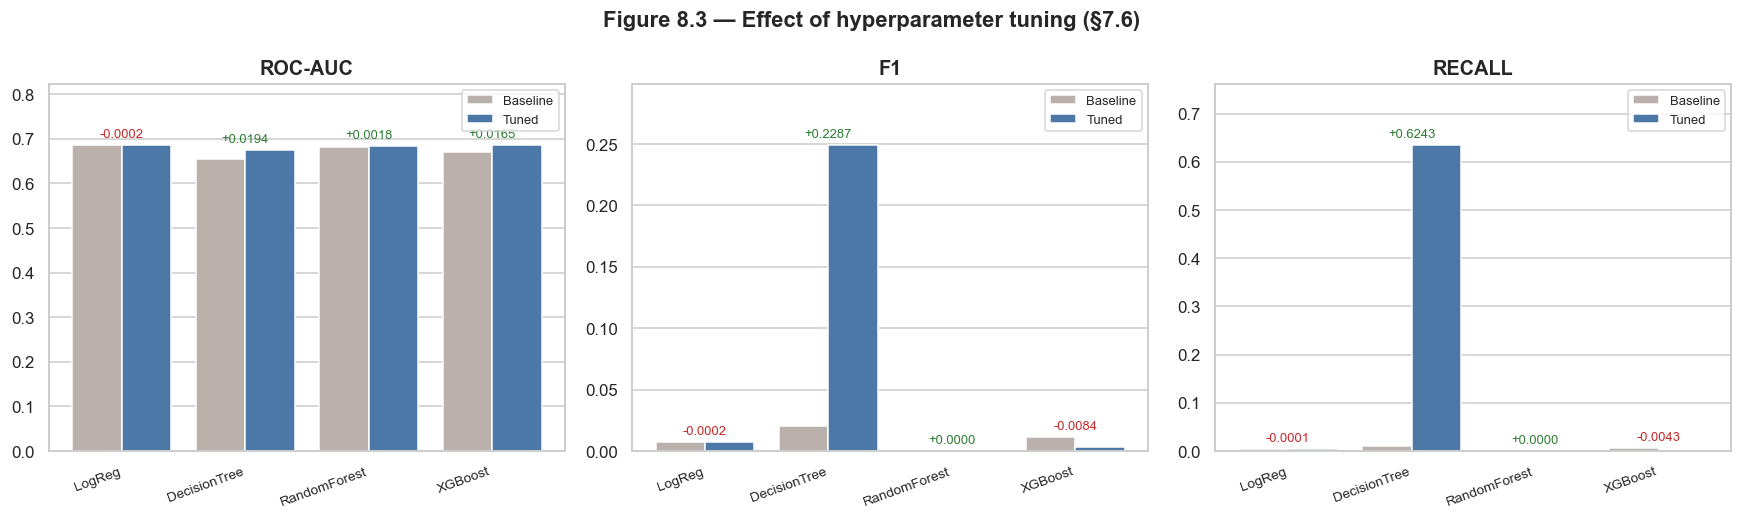

In [62]:
# ---- Baseline vs tuned, per model (the §7.6 payoff question) --------------
b = (ABLATION[ABLATION.imbalance == "none"][["model", "roc_auc", "f1", "recall"]]
     .assign(stage="Baseline (untuned)"))
t = TUNED.copy()
t["model"] = t.model.str.split("-").str[0]
t = t[["model", "roc_auc", "f1", "recall"]].assign(stage="Tuned")
COMPARE = pd.concat([b, t], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, m in zip(axes, ["roc_auc", "f1", "recall"]):
    piv = COMPARE.pivot_table(index="model", columns="stage", values=m).reindex(MODELS_TO_TUNE)
    xs = np.arange(len(piv))
    ax.bar(xs - 0.2, piv["Baseline (untuned)"], 0.4, label="Baseline", color="#BAB0AC")
    ax.bar(xs + 0.2, piv["Tuned"], 0.4, label="Tuned", color=C_ML)
    for i, (b0, t0_) in enumerate(zip(piv["Baseline (untuned)"], piv["Tuned"])):
        if pd.notna(b0) and pd.notna(t0_):
            ax.annotate(f"{t0_-b0:+.4f}", (i, max(b0, t0_)),
                        textcoords="offset points", xytext=(0, 5),
                        ha="center", fontsize=8.5,
                        color=("#2E7D32" if t0_ >= b0 else "#C62828"))
    ax.set_xticks(xs); ax.set_xticklabels(piv.index, rotation=20, ha="right", fontsize=9)
    ax.set_title(m.upper().replace("_", "-")); ax.legend(fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(piv.max().max() * 1.2, 0.1))

fig.suptitle("Figure 8.3 — Effect of hyperparameter tuning (§7.6)", fontweight="semibold")
savefig("fig_8_3_baseline_vs_tuned")
plt.show()

## 8.5 Threshold selection for the recall-oriented objective (§7.7)

All metrics so far use the default 0.50 cut-off, which is arbitrary under 9:1
imbalance. §7.7 argues that in churn *"failing to identify an at-risk customer
may result in direct revenue loss"*, so recall is privileged. §7.7(e) further
notes that AUC's value is precisely that it lets practitioners *"select the most
appropriate operational cut-off point for intervention strategies"*.

Two thresholds are therefore derived on cross-validated out-of-fold predictions
(never on the test set): the F1-maximising threshold, and the lowest threshold
achieving ≥70% recall.

In [63]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

best_name = FINAL.model.iloc[0]
print(f"Best model by AUC: {best_name}")

_root = best_name.split("-")[0]
if _root in BEST_ESTIMATORS:
    _params, _search = BEST_ESTIMATORS[_root]
    _base, _imb = build_from_params(_root, _params)
    THRESH_MODEL = LeakageSafeClassifier(
        base_estimator=_base, numeric_features=NUMERIC_FEATURES,
        categorical_features=CATEGORICAL_FEATURES, winsorise_cols=WINSORISE_COLS,
        imbalance=_imb, random_state=RANDOM_STATE)
else:
    THRESH_MODEL = None
    print("Best model is a DL model; threshold analysis uses the best ML model instead.")
    _root = TUNED.model.iloc[0].split("-")[0]
    _params, _search = BEST_ESTIMATORS[_root]
    _base, _imb = build_from_params(_root, _params)
    THRESH_MODEL = LeakageSafeClassifier(
        base_estimator=_base, numeric_features=NUMERIC_FEATURES,
        categorical_features=CATEGORICAL_FEATURES, winsorise_cols=WINSORISE_COLS,
        imbalance=_imb, random_state=RANDOM_STATE)

_Xs = X_train.sample(min(200_000, len(X_train)), random_state=RANDOM_STATE)
_ys = y_train.loc[_Xs.index]
oof = cross_val_predict(THRESH_MODEL, _Xs, _ys, cv=CV_SEARCH,
                        method="predict_proba", n_jobs=1)[:, 1]

prec, rec, thr = precision_recall_curve(_ys, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
i_f1 = int(np.nanargmax(f1s[:-1]))
THR_F1 = float(thr[i_f1])

target_recall = 0.70
ok = np.where(rec[:-1] >= target_recall)[0]
THR_RECALL = float(thr[ok[-1]]) if len(ok) else 0.5

print(f"\nDefault threshold      0.500  ->  recall {rec[np.searchsorted(thr,0.5)]:.4f}")
print(f"F1-optimal threshold   {THR_F1:.3f}  ->  recall {rec[i_f1]:.4f}, "
      f"precision {prec[i_f1]:.4f}, F1 {f1s[i_f1]:.4f}")
print(f"Recall>={target_recall:.0%} threshold  {THR_RECALL:.3f}")

Best model by AUC: LogReg-random



Default threshold      0.500  ->  recall 0.0032
F1-optimal threshold   0.139  ->  recall 0.4143, precision 0.1989, F1 0.2687
Recall>=70% threshold  0.090


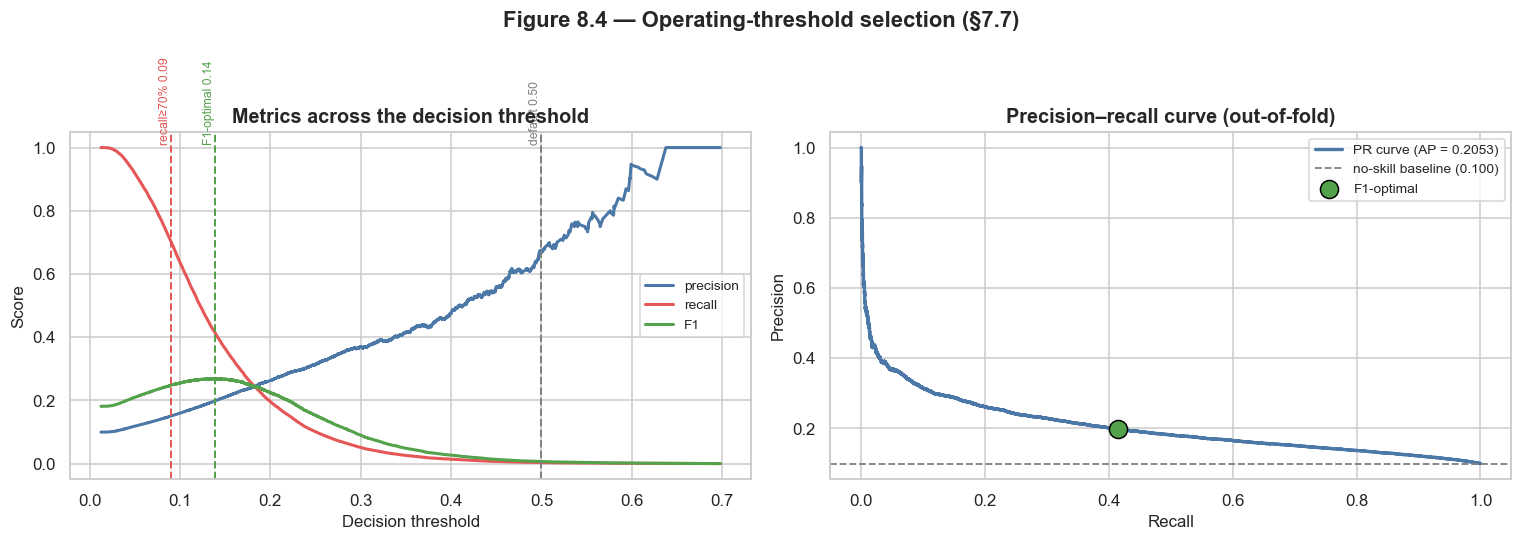

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(thr, prec[:-1], label="precision", color=C_STAY, lw=2)
axes[0].plot(thr, rec[:-1], label="recall", color=C_CHURN, lw=2)
axes[0].plot(thr, f1s[:-1], label="F1", color="#54A24B", lw=2)
for x, lab, c in [(0.5, "default 0.50", "grey"),
                  (THR_F1, f"F1-optimal {THR_F1:.2f}", "#54A24B"),
                  (THR_RECALL, f"recall≥70% {THR_RECALL:.2f}", C_CHURN)]:
    axes[0].axvline(x, ls="--", lw=1.3, color=c)
    axes[0].text(x, 1.01, lab, rotation=90, fontsize=8, ha="right", va="bottom", color=c)
axes[0].set_xlabel("Decision threshold"); axes[0].set_ylabel("Score")
axes[0].set_title("Metrics across the decision threshold")
axes[0].legend(fontsize=9)

axes[1].plot(rec, prec, color=C_ML, lw=2.2,
             label=f"PR curve (AP = {average_precision_score(_ys, oof):.4f})")
axes[1].axhline(_ys.mean(), ls="--", color="grey", lw=1.2,
                label=f"no-skill baseline ({_ys.mean():.3f})")
axes[1].scatter([rec[i_f1]], [prec[i_f1]], s=140, color="#54A24B",
                edgecolor="black", zorder=5, label="F1-optimal")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curve (out-of-fold)")
axes[1].legend(fontsize=9)

fig.suptitle("Figure 8.4 — Operating-threshold selection (§7.7)", fontweight="semibold")
savefig("fig_8_4_threshold_selection")
plt.show()

---
# Part 9 — Statistical significance testing (§7.7 Table 9)

§7.7(g) is explicit: *"a model with higher raw metrics ... is an efficient
requirement to claim this model outperform other models. Statistical significance
testing helps to ensure the evaluation is sufficiently rigorous to conclude that
higher performance does not happen by chance."*

Table 9 prescribes the exact procedure, applied here to all six metrics:

1. Compute **fold-level** scores under **repeated stratified k-fold CV**
2. Compare models using the **distribution of scores across folds**
3. Apply **paired t-tests** and the **Wilcoxon signed-rank test**
4. Report **bootstrap 95% confidence intervals**

Two additions the proposal does not name but which the design requires:
**Holm–Bonferroni correction**, because comparing 6 models pairwise produces 15
tests and uncorrected p-values would overstate significance; and **Cohen's
d_z**, because at these fold counts a statistically detectable difference may
still be practically negligible.

In [65]:
from scipy import stats

# Repeated CV on the tuning subsample gives N_SPLITS x N_REPEATS paired
# observations per model — the input Table 9 requires.
print(f"Running {N_REPEATS} x {N_SPLITS}-fold repeated stratified CV "
      f"= {N_REPEATS*N_SPLITS} paired observations per model\n")

sig_models = {}
for name, (params, search) in BEST_ESTIMATORS.items():
    base, imb = build_from_params(name, params)
    sig_models[f"{name}"] = (base, imb)

sig_folds = []
for name, (base, imb) in sig_models.items():
    print(f"  {name} (imbalance={imb}) ...", end=" ", flush=True)
    t0 = time.perf_counter()
    pf, _ = evaluate_cv({name: base}, X_tune, y_tune, n_splits=N_SPLITS,
                        n_repeats=N_REPEATS, imbalance=imb,
                        benchmark=False, verbose=False)
    sig_folds.append(pf)
    print(f"{time.perf_counter()-t0:.0f}s")

print("  ANN / DNN ...", end=" ", flush=True)
t0 = time.perf_counter()
dl_pf, _ = evaluate_dl_cv({"ANN": build_ann, "DNN": build_dnn},
                          X_tune, y_tune, n_splits=N_SPLITS, n_repeats=N_REPEATS,
                          imbalance="balanced", verbose=False)
print(f"{time.perf_counter()-t0:.0f}s")

SIG_FOLDS = pd.concat(sig_folds + [dl_pf], ignore_index=True)
SIG_FOLDS["family"] = np.where(SIG_FOLDS.model.isin(["ANN", "DNN"]), "DL", "ML")
SIG_FOLDS.to_csv("results_repeated_cv_folds.csv", index=False)
print(f"\n{len(SIG_FOLDS)} fold-level observations across "
      f"{SIG_FOLDS.model.nunique()} models")
SIG_FOLDS.groupby("model")[["roc_auc", "f1", "recall"]].agg(["mean", "std"]).round(4)

Running 3 x 5-fold repeated stratified CV = 15 paired observations per model

  DecisionTree (imbalance=balanced) ... 

35s
  LogReg (imbalance=none) ... 

25s
  RandomForest (imbalance=none) ... 

204s
  XGBoost (imbalance=none) ... 

31s
  ANN / DNN ... 

189s

90 fold-level observations across 6 models


roc_auc            f1        recall       
                mean    std   mean    std   mean    std
model                                                  
ANN           0.6835 0.0060 0.2536 0.0037 0.6527 0.0144
DNN           0.6527 0.0059 0.2441 0.0052 0.4816 0.0654
DecisionTree  0.6668 0.0070 0.2472 0.0049 0.6006 0.0331
LogReg        0.6866 0.0062 0.0043 0.0019 0.0022 0.0010
RandomForest  0.6831 0.0065 0.0000 0.0000 0.0000 0.0000
XGBoost       0.6856 0.0064 0.0018 0.0009 0.0009 0.0005

In [66]:
def bootstrap_ci(x, n_boot=10_000, alpha=0.05, seed=RANDOM_STATE):
    """Percentile bootstrap confidence interval (section 7.7 Table 9)."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) < 2:
        return (np.nan, np.nan)
    rng = np.random.RandomState(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return (float(np.percentile(means, 100 * alpha / 2)),
            float(np.percentile(means, 100 * (1 - alpha / 2))))


METRICS_SIG = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]

rows = []
for mdl, g in SIG_FOLDS.groupby("model"):
    for m in METRICS_SIG:
        lo, hi = bootstrap_ci(g[m].values)
        rows.append({"model": mdl, "metric": m, "mean": g[m].mean(),
                     "std": g[m].std(ddof=1), "ci95_low": lo, "ci95_high": hi,
                     "n_folds": g[m].notna().sum()})

CI_TABLE = pd.DataFrame(rows)
CI_WIDE = CI_TABLE.pivot(index="model", columns="metric", values="mean").round(4)
CI_WIDE["roc_auc_95CI"] = [
    f"[{CI_TABLE.query('model==@m and metric==\"roc_auc\"').ci95_low.iloc[0]:.4f}, "
    f"{CI_TABLE.query('model==@m and metric==\"roc_auc\"').ci95_high.iloc[0]:.4f}]"
    for m in CI_WIDE.index]
CI_WIDE.sort_values("roc_auc", ascending=False)

metric,accuracy,f1,pr_auc,precision,recall,roc_auc,roc_auc_95CI
model,,,,,,,
LogReg,0.9008,0.0043,0.2005,0.5577,0.0022,0.6866,"[0.6835, 0.6895]"
XGBoost,0.9008,0.0018,0.2023,0.8089,0.0009,0.6856,"[0.6824, 0.6886]"
ANN,0.6188,0.2536,0.1989,0.1574,0.6527,0.6835,"[0.6805, 0.6864]"
RandomForest,0.9008,0.0000,0.1976,0.0000,0.0000,0.6831,"[0.6799, 0.6862]"
DecisionTree,0.6368,0.2472,0.1778,0.1558,0.6006,0.6668,"[0.6632, 0.6701]"
DNN,0.7040,0.2441,0.1706,0.1647,0.4816,0.6527,"[0.6498, 0.6555]"


In [67]:
def paired_comparisons(folds_df, metric, alpha=0.05):
    """
    All pairwise model comparisons on fold-level scores (section 7.7 Table 9).

    Reports a paired t-test AND a Wilcoxon signed-rank test (the proposal names
    both), Cohen's d_z for effect size, and Holm-Bonferroni corrected p-values to
    control the family-wise error rate across the full comparison set.
    """
    wide = folds_df.pivot_table(index=["repeat", "fold"], columns="model", values=metric)
    models = list(wide.columns)
    out = []
    for i in range(len(models)):
        for j in range(i + 1, len(models)):
            a, b = models[i], models[j]
            pair = wide[[a, b]].dropna()
            if len(pair) < 3:
                continue
            xa, xb = pair[a].values, pair[b].values
            d = xa - xb
            t_stat, p_t = stats.ttest_rel(xa, xb)
            try:
                w_stat, p_w = stats.wilcoxon(xa, xb)
            except ValueError:
                w_stat, p_w = np.nan, 1.0
            dz = d.mean() / (d.std(ddof=1) + 1e-12)
            out.append({
                "metric": metric, "model_a": a, "model_b": b,
                "mean_a": xa.mean(), "mean_b": xb.mean(), "diff": d.mean(),
                "t_stat": t_stat, "p_ttest": p_t,
                "wilcoxon_stat": w_stat, "p_wilcoxon": p_w,
                "cohens_dz": dz, "n_pairs": len(pair),
            })
    res = pd.DataFrame(out)
    if res.empty:
        return res

    # Holm-Bonferroni step-down correction
    for col in ("p_ttest", "p_wilcoxon"):
        order = res[col].values.argsort()
        m = len(res)
        adj = np.empty(m)
        prev = 0.0
        for rank, idx in enumerate(order):
            val = min(1.0, (m - rank) * res[col].values[idx])
            prev = max(prev, val)
            adj[idx] = prev
        res[col + "_holm"] = adj

    res["significant"] = res.p_ttest_holm < alpha
    res["effect"] = pd.cut(res.cohens_dz.abs(), [-0.001, 0.2, 0.5, 0.8, np.inf],
                           labels=["negligible", "small", "medium", "large"])
    return res.sort_values("p_ttest_holm").reset_index(drop=True)


SIG_AUC = paired_comparisons(SIG_FOLDS, "roc_auc")
SIG_AUC.to_csv("results_significance_roc_auc.csv", index=False)
print("Pairwise comparisons on ROC-AUC (Holm-corrected):")
SIG_AUC[["model_a", "model_b", "mean_a", "mean_b", "diff", "p_ttest",
         "p_ttest_holm", "p_wilcoxon_holm", "cohens_dz", "effect",
         "significant"]].round(5)

Pairwise comparisons on ROC-AUC (Holm-corrected):


,model_a,model_b,mean_a,mean_b,diff,p_ttest,p_ttest_holm,p_wilcoxon_holm,cohens_dz,effect,significant
0,DecisionTree,LogReg,0.6669,0.6866,-0.0197,0.0000,0.0000,0.0009,-6.0546,large,True
1,DecisionTree,XGBoost,0.6669,0.6856,-0.0187,0.0000,0.0000,0.0009,-5.9260,large,True
2,DNN,LogReg,0.6527,0.6866,-0.0339,0.0000,0.0000,0.0009,-5.7925,large,True
3,DNN,XGBoost,0.6527,0.6856,-0.0329,0.0000,0.0000,0.0009,-5.3213,large,True
4,ANN,DNN,0.6835,0.6527,0.0308,0.0000,0.0000,0.0009,5.1427,large,True
5,DNN,RandomForest,0.6527,0.6831,-0.0304,0.0000,0.0000,0.0009,-4.6143,large,True
6,DecisionTree,RandomForest,0.6669,0.6831,-0.0163,0.0000,0.0000,0.0009,-4.5016,large,True
7,ANN,DecisionTree,0.6835,0.6669,0.0167,0.0000,0.0000,0.0009,4.2344,large,True
8,ANN,LogReg,0.6835,0.6866,-0.0031,0.0000,0.0000,0.0009,-2.7434,large,True
9,RandomForest,XGBoost,0.6831,0.6856,-0.0024,0.0000,0.0000,0.0009,-2.3988,large,True


In [68]:
# ---- Significance across all six metrics ----------------------------------
ALL_SIG = pd.concat([paired_comparisons(SIG_FOLDS, m) for m in METRICS_SIG],
                    ignore_index=True)
ALL_SIG.to_csv("results_significance_all_metrics.csv", index=False)

print("Significant pairs per metric (Holm-corrected paired t-test, alpha=0.05):")
summary = (ALL_SIG.groupby("metric")
           .agg(n_comparisons=("significant", "size"),
                n_significant=("significant", "sum"),
                n_large_effect=("effect", lambda s: (s == "large").sum()))
           .reindex(METRICS_SIG))
summary["pct_significant"] = (100 * summary.n_significant / summary.n_comparisons).round(1)
summary

Significant pairs per metric (Holm-corrected paired t-test, alpha=0.05):


,n_comparisons,n_significant,n_large_effect,pct_significant
metric,,,,
accuracy,15,13,12,86.7000
precision,15,14,14,93.3000
recall,15,15,15,100.0000
f1,15,15,14,100.0000
roc_auc,15,14,14,93.3000
pr_auc,15,14,14,93.3000


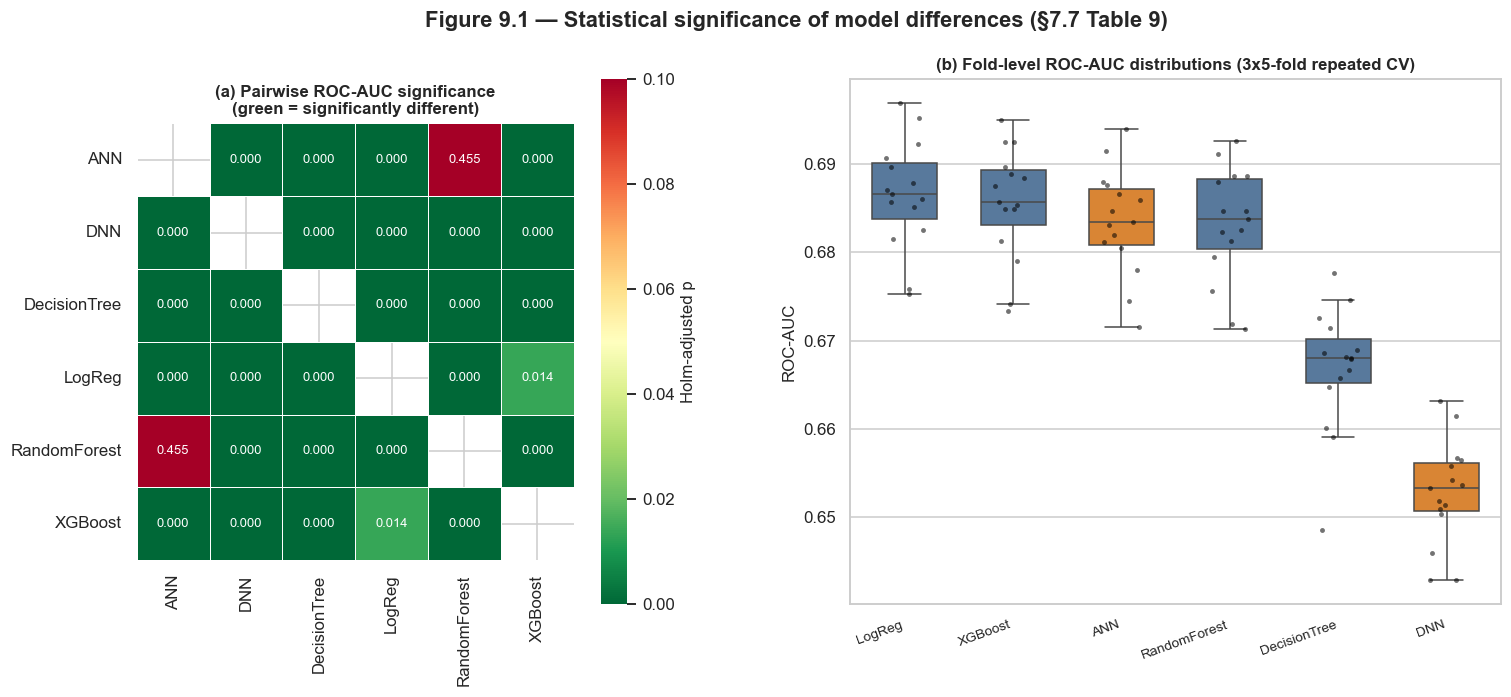

In [69]:
# ---- Significance heatmap + fold-level distributions ----------------------
fig = plt.figure(figsize=(16, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.25], wspace=0.28)

# (a) p-value matrix for ROC-AUC
ax = fig.add_subplot(gs[0])
mods = sorted(SIG_FOLDS.model.unique())
M = pd.DataFrame(np.nan, index=mods, columns=mods)
for _, r in SIG_AUC.iterrows():
    M.loc[r.model_a, r.model_b] = r.p_ttest_holm
    M.loc[r.model_b, r.model_a] = r.p_ttest_holm
sns.heatmap(M, annot=True, fmt=".3f", cmap="RdYlGn_r", vmin=0, vmax=0.10,
            square=True, linewidths=0.6, cbar_kws={"label": "Holm-adjusted p"},
            ax=ax, annot_kws={"fontsize": 8.5})
ax.set_title("(a) Pairwise ROC-AUC significance\n(green = significantly different)",
             fontsize=11)

# (b) fold-level distributions
ax2 = fig.add_subplot(gs[1])
order = (SIG_FOLDS.groupby("model").roc_auc.mean()
         .sort_values(ascending=False).index.tolist())
pal = {m: (C_DL if m in ("ANN", "DNN") else C_ML) for m in order}
sns.boxplot(data=SIG_FOLDS, x="model", y="roc_auc", order=order,
            palette=pal, width=0.6, fliersize=0, ax=ax2)
sns.stripplot(data=SIG_FOLDS, x="model", y="roc_auc", order=order,
              color="black", size=3.2, alpha=0.55, jitter=0.18, ax=ax2)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=20, ha="right", fontsize=9)
ax2.set_ylabel("ROC-AUC"); ax2.set_xlabel("")
ax2.set_title(f"(b) Fold-level ROC-AUC distributions "
              f"({N_REPEATS}x{N_SPLITS}-fold repeated CV)", fontsize=11)

fig.suptitle("Figure 9.1 — Statistical significance of model differences (§7.7 Table 9)",
             fontweight="semibold")
savefig("fig_9_1_significance")
plt.show()

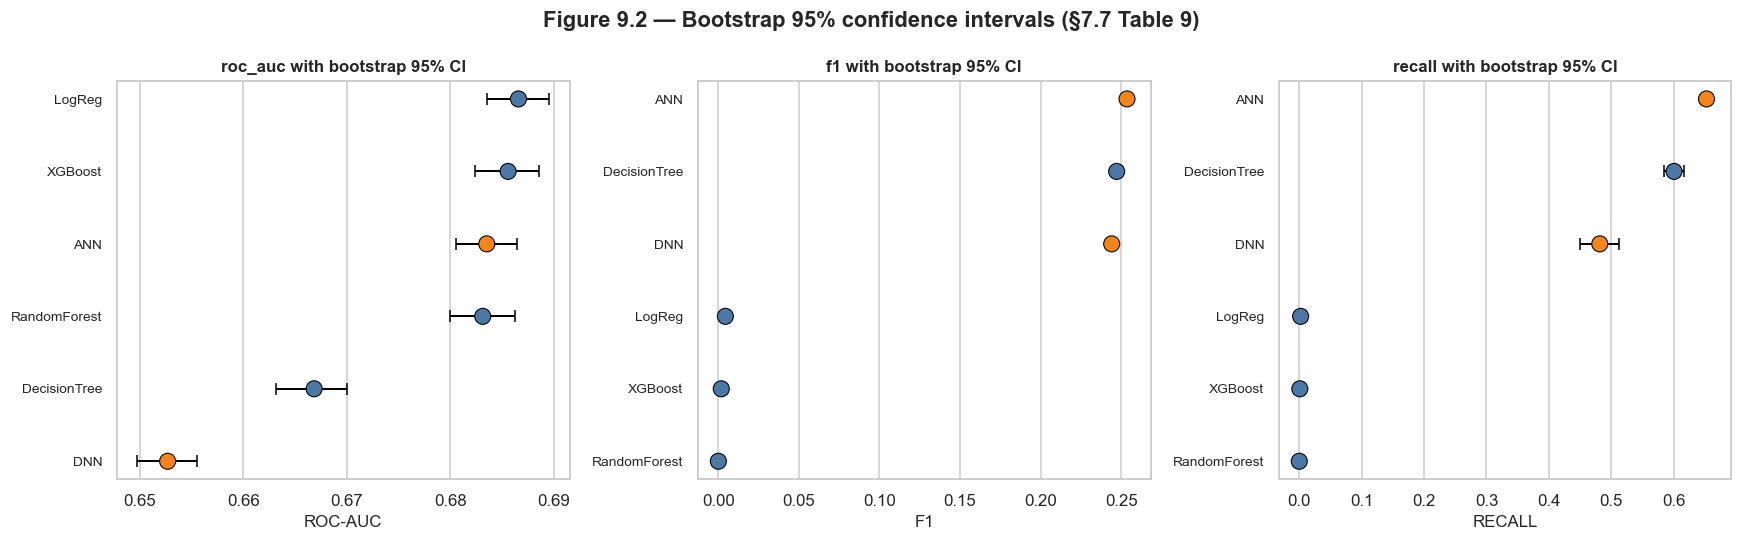

In [70]:
# ---- Forest plot: mean +/- bootstrap 95% CI -------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, m in zip(axes, ["roc_auc", "f1", "recall"]):
    sub = (CI_TABLE[CI_TABLE.metric == m]
           .sort_values("mean").reset_index(drop=True))
    cols = [C_DL if x in ("ANN", "DNN") else C_ML for x in sub.model]
    ax.errorbar(sub["mean"], range(len(sub)),
                xerr=[sub["mean"] - sub.ci95_low, sub.ci95_high - sub["mean"]],
                fmt="none", ecolor="black", capsize=4, lw=1.3, zorder=2)
    ax.scatter(sub["mean"], range(len(sub)), s=110, c=cols,
               edgecolor="black", lw=0.7, zorder=3)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels(sub.model, fontsize=9)
    ax.set_xlabel(m.upper().replace("_", "-"))
    ax.set_title(f"{m} with bootstrap 95% CI", fontsize=11)
    ax.grid(axis="y", visible=False)

fig.suptitle("Figure 9.2 — Bootstrap 95% confidence intervals (§7.7 Table 9)",
             fontweight="semibold")
savefig("fig_9_2_forest_ci")
plt.show()

In [71]:
# ---- The headline ML vs DL verdict (research question 1) ------------------
best_ml_name = (SIG_FOLDS[SIG_FOLDS.family == "ML"]
                .groupby("model").roc_auc.mean().idxmax())
best_dl_name = (SIG_FOLDS[SIG_FOLDS.family == "DL"]
                .groupby("model").roc_auc.mean().idxmax())

print(f"Best ML model: {best_ml_name}")
print(f"Best DL model: {best_dl_name}\n")
print(f"{'metric':<12}{'ML':>10}{'DL':>10}{'diff':>10}{'p (Holm)':>12}"
      f"{'d_z':>9}  verdict")
print("-" * 78)
for m in METRICS_SIG:
    r = ALL_SIG[(ALL_SIG.metric == m) &
                (((ALL_SIG.model_a == best_ml_name) & (ALL_SIG.model_b == best_dl_name)) |
                 ((ALL_SIG.model_a == best_dl_name) & (ALL_SIG.model_b == best_ml_name)))]
    if r.empty:
        continue
    r = r.iloc[0]
    ml_v = r.mean_a if r.model_a == best_ml_name else r.mean_b
    dl_v = r.mean_b if r.model_a == best_ml_name else r.mean_a
    verdict = ("ML significantly better" if (ml_v > dl_v and r.p_ttest_holm < 0.05)
               else "DL significantly better" if (dl_v > ml_v and r.p_ttest_holm < 0.05)
               else "no significant difference")
    print(f"{m:<12}{ml_v:>10.4f}{dl_v:>10.4f}{ml_v-dl_v:>+10.4f}"
          f"{r.p_ttest_holm:>12.4f}{abs(r.cohens_dz):>9.2f}  {verdict}")

Best ML model: LogReg
Best DL model: ANN

metric              ML        DL      diff    p (Holm)      d_z  verdict
------------------------------------------------------------------------------
accuracy        0.9008    0.6188   +0.2820      0.0000    35.11  ML significantly better
precision       0.5577    0.1574   +0.4003      0.0000     3.00  ML significantly better
recall          0.0022    0.6527   -0.6505      0.0000    43.37  DL significantly better
f1              0.0043    0.2536   -0.2493      0.0000    55.91  DL significantly better
roc_auc         0.6866    0.6835   +0.0031      0.0000     2.74  ML significantly better
pr_auc          0.2005    0.1989   +0.0016      0.0057     0.99  ML significantly better


---
# Part 10 — Interpretability analysis with SHAP (§7.8)

§7.8 specifies SHapley Additive exPlanations, using **TreeSHAP for tree-based
models** (Random Forest, XGBoost) for computational efficiency and **KernelSHAP
for deep learning models**, and states three purposes for the results:

- **(a) Feature importance validation** — do the highly weighted features agree
  with domain expertise and prior literature?
- **(b) Model debugging** — are any features introducing bias or spurious
  correlation?
- **(c) Actionable insights** — which behavioural drivers should retention
  strategy target?

Purpose (b) is directly testable here: EDA finding 3 identified a group of
features with **zero** measured association with churn. A well-behaved model must
assign them near-zero SHAP attribution. This gives the interpretability analysis
a falsifiable negative control rather than a purely descriptive role.

Explainers are fitted on training data and **evaluated on the held-out test set**,
so the attributions describe generalisation behaviour rather than memorised
training structure.

In [72]:
import shap

# Fit the best ML model on the FULL training set, then explain TEST predictions
_root = TUNED.model.iloc[0].split("-")[0]
_params, _search = BEST_ESTIMATORS[_root]
_base, _imb = build_from_params(_root, _params)

FINAL_MODEL = LeakageSafeClassifier(
    base_estimator=_base, numeric_features=NUMERIC_FEATURES,
    categorical_features=CATEGORICAL_FEATURES, winsorise_cols=WINSORISE_COLS,
    imbalance=_imb, random_state=RANDOM_STATE)

print(f"Fitting {_root} (tuned via {_search}, imbalance={_imb}) on "
      f"{len(X_train):,} training rows ...")
t0 = time.perf_counter()
FINAL_MODEL.fit(X_train, y_train)
print(f"  done in {time.perf_counter()-t0:.0f}s")

FEATURE_NAMES = FINAL_MODEL.feature_names_
print(f"  {len(FEATURE_NAMES)} features after one-hot encoding")

Fitting LogReg (tuned via random, imbalance=none) on 800,000 training rows ...


  done in 9s
  65 features after one-hot encoding


In [73]:
# ---- Explain a stratified sample of the HELD-OUT test set -----------------
SHAP_N = 4000
_idx = (X_test.assign(_y=y_test)
              .groupby("_y", group_keys=False)
              .apply(lambda g: g.sample(min(len(g), SHAP_N // 2),
                                        random_state=RANDOM_STATE)).index)
X_shap = X_test.loc[_idx]
y_shap = y_test.loc[_idx]
M_shap = FINAL_MODEL.pre_.transform(X_shap)
M_shap_df = pd.DataFrame(M_shap, columns=FEATURE_NAMES, index=X_shap.index)

est = FINAL_MODEL.estimator_
kind = type(est).__name__
print(f"Explaining {len(X_shap):,} held-out test rows for {kind}")

t0 = time.perf_counter()
if kind in ("RandomForestClassifier", "DecisionTreeClassifier", "XGBClassifier"):
    explainer = shap.TreeExplainer(est)          # §7.8: TreeSHAP for tree models
    sv = explainer.shap_values(M_shap_df)
    if isinstance(sv, list):
        sv = sv[1]
    elif sv.ndim == 3:
        sv = sv[:, :, 1]
    expected_value = (explainer.expected_value[1]
                      if np.ndim(explainer.expected_value) else explainer.expected_value)
else:
    bg = shap.kmeans(FINAL_MODEL.pre_.transform(
        X_train.sample(min(2000, len(X_train)), random_state=RANDOM_STATE)), 50)
    explainer = shap.LinearExplainer(est, M_shap_df) if kind == "LogisticRegression" \
        else shap.KernelExplainer(lambda Z: est.predict_proba(Z)[:, 1], bg)
    sv = explainer.shap_values(M_shap_df)
    if isinstance(sv, list):
        sv = sv[1]
    expected_value = np.ravel(explainer.expected_value)[0]

SHAP_VALUES = np.asarray(sv)
print(f"  SHAP computed in {time.perf_counter()-t0:.0f}s | shape {SHAP_VALUES.shape}")

Explaining 4,000 held-out test rows for LogisticRegression


  SHAP computed in 0s | shape (4000, 65)


In [74]:
# ---- (a) Global feature importance ----------------------------------------
IMPORTANCE = (pd.DataFrame({
        "feature": FEATURE_NAMES,
        "mean_abs_shap": np.abs(SHAP_VALUES).mean(axis=0),
        "mean_shap": SHAP_VALUES.mean(axis=0),
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True))
IMPORTANCE["pct_of_total"] = 100 * IMPORTANCE.mean_abs_shap / IMPORTANCE.mean_abs_shap.sum()
IMPORTANCE["cumulative_pct"] = IMPORTANCE.pct_of_total.cumsum()
IMPORTANCE["origin"] = np.where(IMPORTANCE.feature.isin(NEW_FEATURES), "engineered", "raw")
IMPORTANCE.to_csv("results_shap_importance.csv", index=False)
IMPORTANCE.head(25).round(5)

,feature,mean_abs_shap,mean_shap,pct_of_total,cumulative_pct,origin
0,contract_months,0.3283,-0.0153,18.5425,18.5425,engineered
1,num_service_calls,0.1742,-0.0545,9.8380,28.3805,raw
2,switching_cost_proxy,0.1635,-0.0186,9.2323,37.6128,engineered
3,has_tech_support,0.0857,-0.0006,4.8427,42.4555,raw
4,customer_satisfaction,0.0837,0.0013,4.7250,47.1805,raw
5,is_detractor,0.0829,0.0045,4.6829,51.8634,engineered
6,late_payments,0.0782,0.0060,4.4174,56.2808,raw
7,num_complaints,0.0724,-0.0044,4.0908,60.3717,raw
8,engagement_index,0.0723,-0.0040,4.0868,64.4584,engineered
9,satisfaction_gap,0.0674,0.0006,3.8082,68.2666,engineered


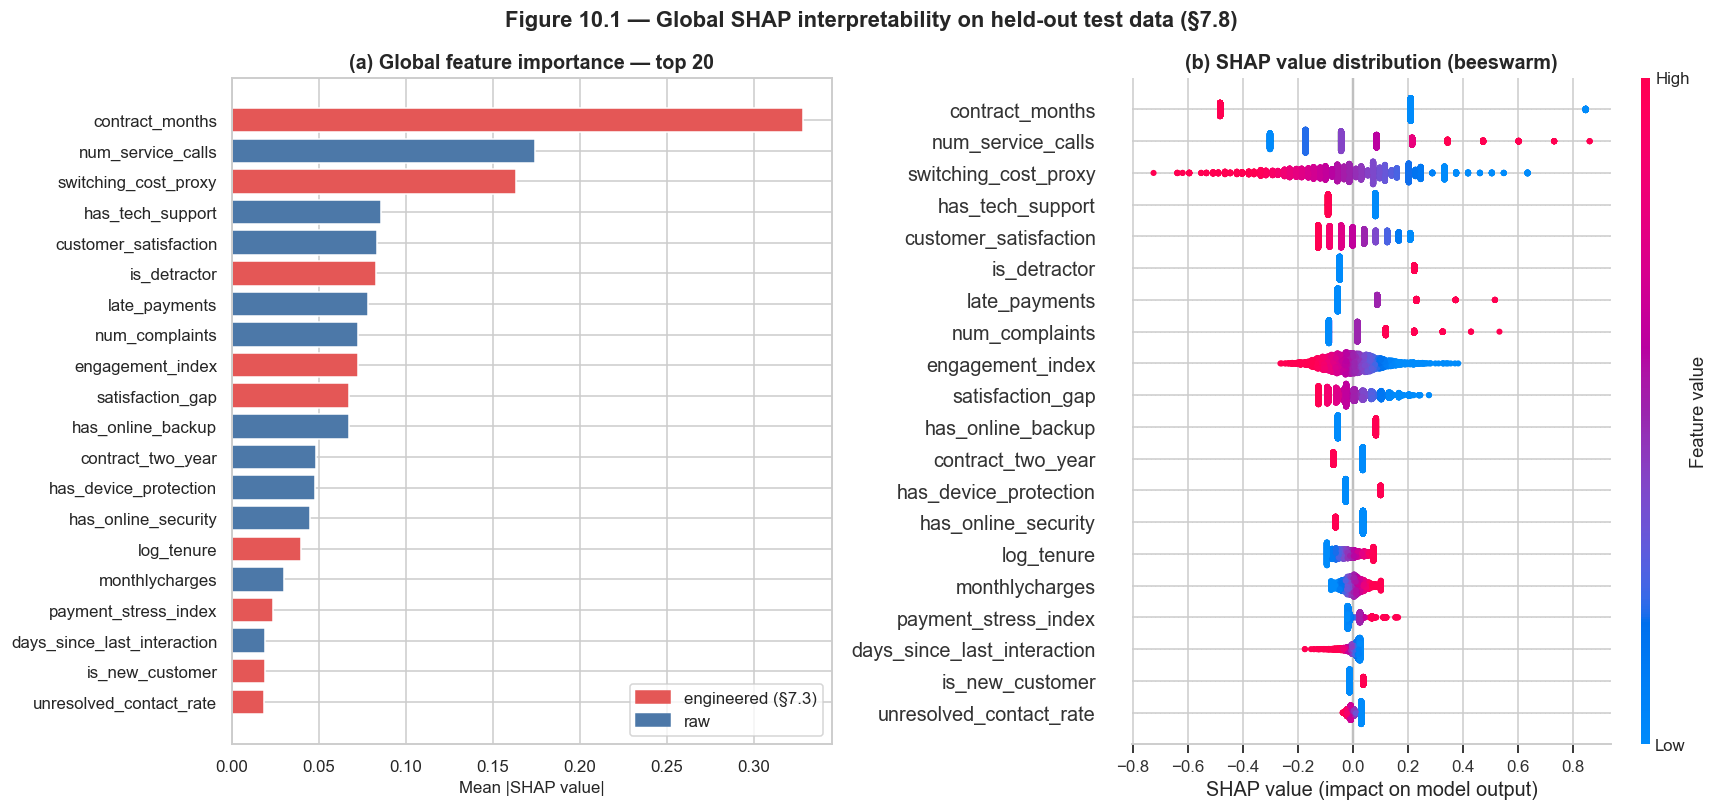

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

top = IMPORTANCE.head(20).iloc[::-1]
cols = [C_CHURN if o == "engineered" else C_STAY for o in top.origin]
axes[0].barh(top.feature, top.mean_abs_shap, color=cols)
axes[0].set_xlabel("Mean |SHAP value|")
axes[0].set_title("(a) Global feature importance — top 20")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=C_CHURN, label="engineered (§7.3)"),
                        Patch(color=C_STAY, label="raw")], loc="lower right")

plt.sca(axes[1])
shap.summary_plot(SHAP_VALUES, M_shap_df, max_display=20, show=False, plot_size=None)
axes[1].set_title("(b) SHAP value distribution (beeswarm)")

fig.suptitle("Figure 10.1 — Global SHAP interpretability on held-out test data (§7.8)",
             fontweight="semibold")
savefig("fig_10_1_shap_global")
plt.show()

In [76]:
# ---- (b) Model debugging: the negative-control test -----------------------
# EDA finding 3 identified features with NO measured association with churn.
# A well-behaved model must assign them near-zero attribution.
NOISE_FEATURES = ["age", "annual_income", "credit_score", "dependents",
                  "senior_citizen", "days_since_last_interaction",
                  "has_streaming_tv", "has_streaming_movies"]
SIGNAL_FEATURES = ["customer_satisfaction", "num_complaints", "num_service_calls",
                   "late_payments", "dissatisfaction_index", "engagement_index",
                   "satisfaction_gap"]

def _group_share(feats):
    m = IMPORTANCE.feature.apply(lambda f: any(f == x or f.startswith(x + "_") for x in feats))
    return IMPORTANCE.loc[m, "pct_of_total"].sum()

contract_share = IMPORTANCE.loc[
    IMPORTANCE.feature.str.startswith("contract"), "pct_of_total"].sum()

CONTROL = pd.DataFrame([
    ("Signal features (EDA finding 4)", _group_share(SIGNAL_FEATURES), "should be HIGH"),
    ("Contract block (strongest predictor)", contract_share, "should be HIGH"),
    ("Noise features (EDA finding 3)", _group_share(NOISE_FEATURES), "should be ~0"),
], columns=["group", "pct_of_total_shap", "expectation"])

print("Model-debugging check (§7.8 purpose b):\n")
print(CONTROL.round(2).to_string(index=False))

_noise_mask = IMPORTANCE.feature.isin(NOISE_FEATURES)
noise_rank = IMPORTANCE.loc[_noise_mask, ["feature", "pct_of_total"]]
_med_rank = float(np.median(np.flatnonzero(_noise_mask.to_numpy()) + 1)) if _noise_mask.any() else np.nan
print(f"\nIndividual noise-feature attributions "
      f"(median importance rank {_med_rank:.0f} of {len(IMPORTANCE)}):")
print(noise_rank.round(3).to_string(index=False))

Model-debugging check (§7.8 purpose b):

                               group  pct_of_total_shap    expectation
     Signal features (EDA finding 4)            31.5900 should be HIGH
Contract block (strongest predictor)            21.3500 should be HIGH
      Noise features (EDA finding 3)             1.7500   should be ~0

Individual noise-feature attributions (median importance rank 54 of 65):
                    feature  pct_of_total
days_since_last_interaction        1.0840
       has_streaming_movies        0.1900
                        age        0.1840
           has_streaming_tv        0.1250
              annual_income        0.0870
                 dependents        0.0600
             senior_citizen        0.0140
               credit_score        0.0060


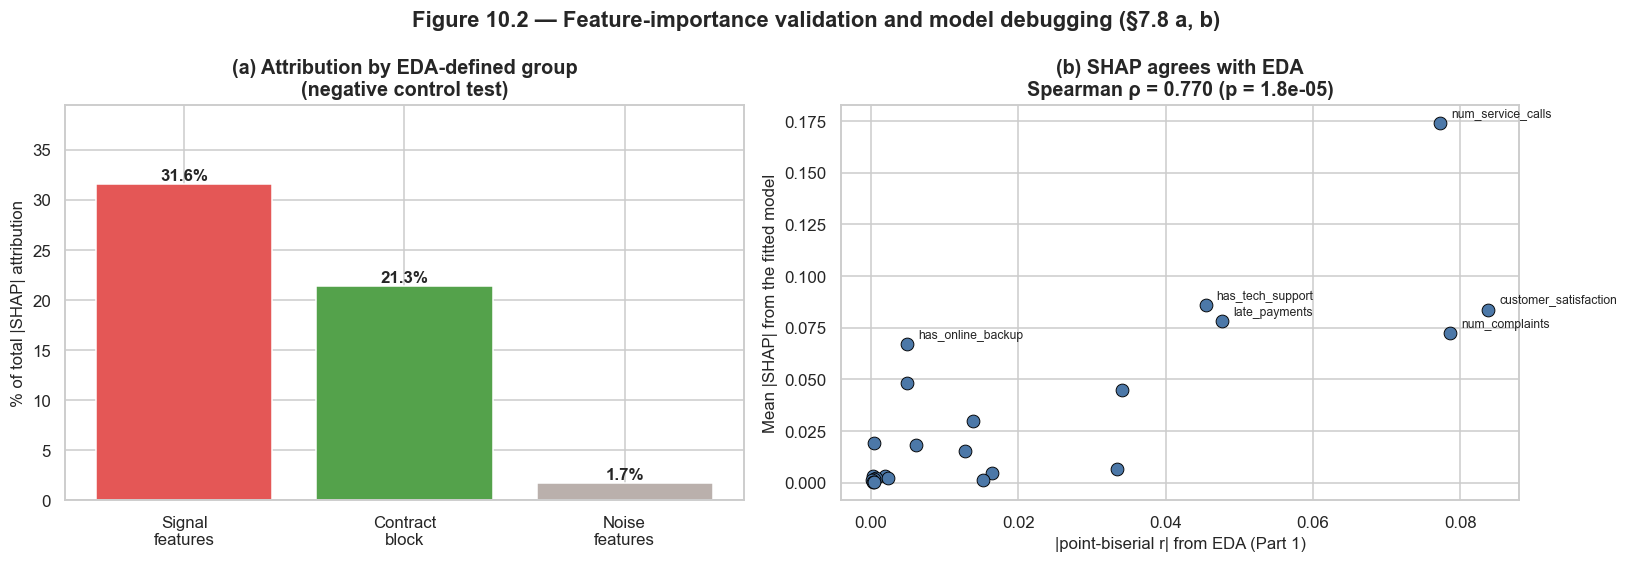

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

vals = CONTROL.pct_of_total_shap.values
axes[0].bar(["Signal\nfeatures", "Contract\nblock", "Noise\nfeatures"], vals,
            color=[C_CHURN, "#54A24B", "#BAB0AC"])
for i, v in enumerate(vals):
    axes[0].text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=11, fontweight="semibold")
axes[0].set_ylabel("% of total |SHAP| attribution")
axes[0].set_title("(a) Attribution by EDA-defined group\n(negative control test)")
axes[0].set_ylim(0, max(vals) * 1.25)

# Does SHAP importance agree with the EDA correlation ranking?
eda_r = CORR_NUM.set_index("feature").abs_r
merged = IMPORTANCE[IMPORTANCE.feature.isin(eda_r.index)].copy()
merged["eda_abs_r"] = merged.feature.map(eda_r)
rho, p_rho = stats.spearmanr(merged.mean_abs_shap, merged.eda_abs_r)
axes[1].scatter(merged.eda_abs_r, merged.mean_abs_shap, s=70,
                color=C_ML, edgecolor="black", lw=0.6)
for _, r in merged.head(6).iterrows():
    axes[1].annotate(r.feature, (r.eda_abs_r, r.mean_abs_shap),
                     textcoords="offset points", xytext=(7, 4), fontsize=8)
axes[1].set_xlabel("|point-biserial r| from EDA (Part 1)")
axes[1].set_ylabel("Mean |SHAP| from the fitted model")
axes[1].set_title(f"(b) SHAP agrees with EDA\nSpearman ρ = {rho:.3f} (p = {p_rho:.2g})")

fig.suptitle("Figure 10.2 — Feature-importance validation and model debugging (§7.8 a, b)",
             fontweight="semibold")
savefig("fig_10_2_shap_validation")
plt.show()

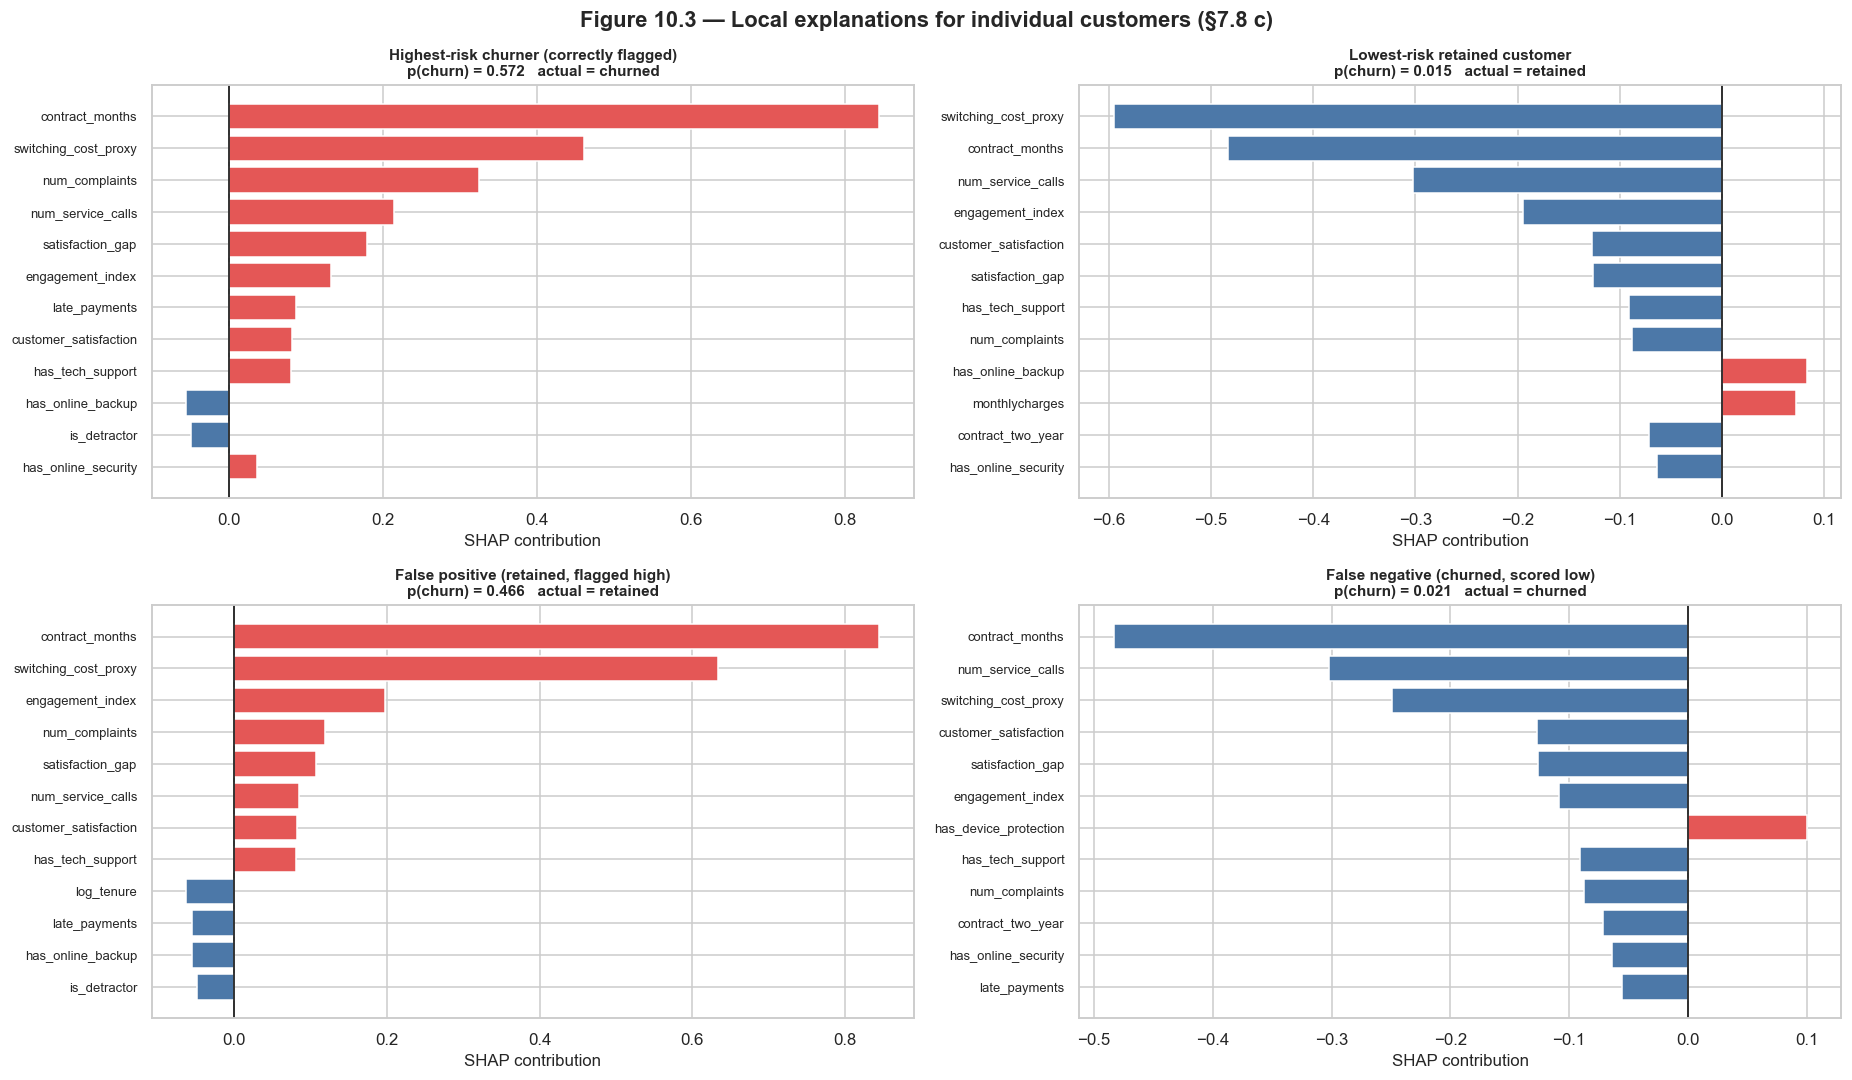

In [78]:
# ---- (c) Local explanations: why THIS customer is flagged ----------------
proba = FINAL_MODEL.predict_proba(X_shap)[:, 1]
cases = {
    "Highest-risk churner (correctly flagged)": int(np.argmax(np.where(y_shap.values == 1, proba, -1))),
    "Lowest-risk retained customer":            int(np.argmin(np.where(y_shap.values == 0, proba, 2))),
    "False positive (retained, flagged high)":  int(np.argmax(np.where(y_shap.values == 0, proba, -1))),
    "False negative (churned, scored low)":     int(np.argmin(np.where(y_shap.values == 1, proba, 2))),
}

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for ax, (title, i) in zip(axes.ravel(), cases.items()):
    contrib = pd.Series(SHAP_VALUES[i], index=FEATURE_NAMES)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(12)[::-1]
    ax.barh(top.index, top.values,
            color=[C_CHURN if v > 0 else C_STAY for v in top.values])
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"{title}\np(churn) = {proba[i]:.3f}   actual = "
                 f"{'churned' if y_shap.values[i]==1 else 'retained'}", fontsize=10)
    ax.set_xlabel("SHAP contribution")
    ax.tick_params(axis="y", labelsize=8.5)

fig.suptitle("Figure 10.3 — Local explanations for individual customers (§7.8 c)",
             fontweight="semibold")
savefig("fig_10_3_shap_local")
plt.show()

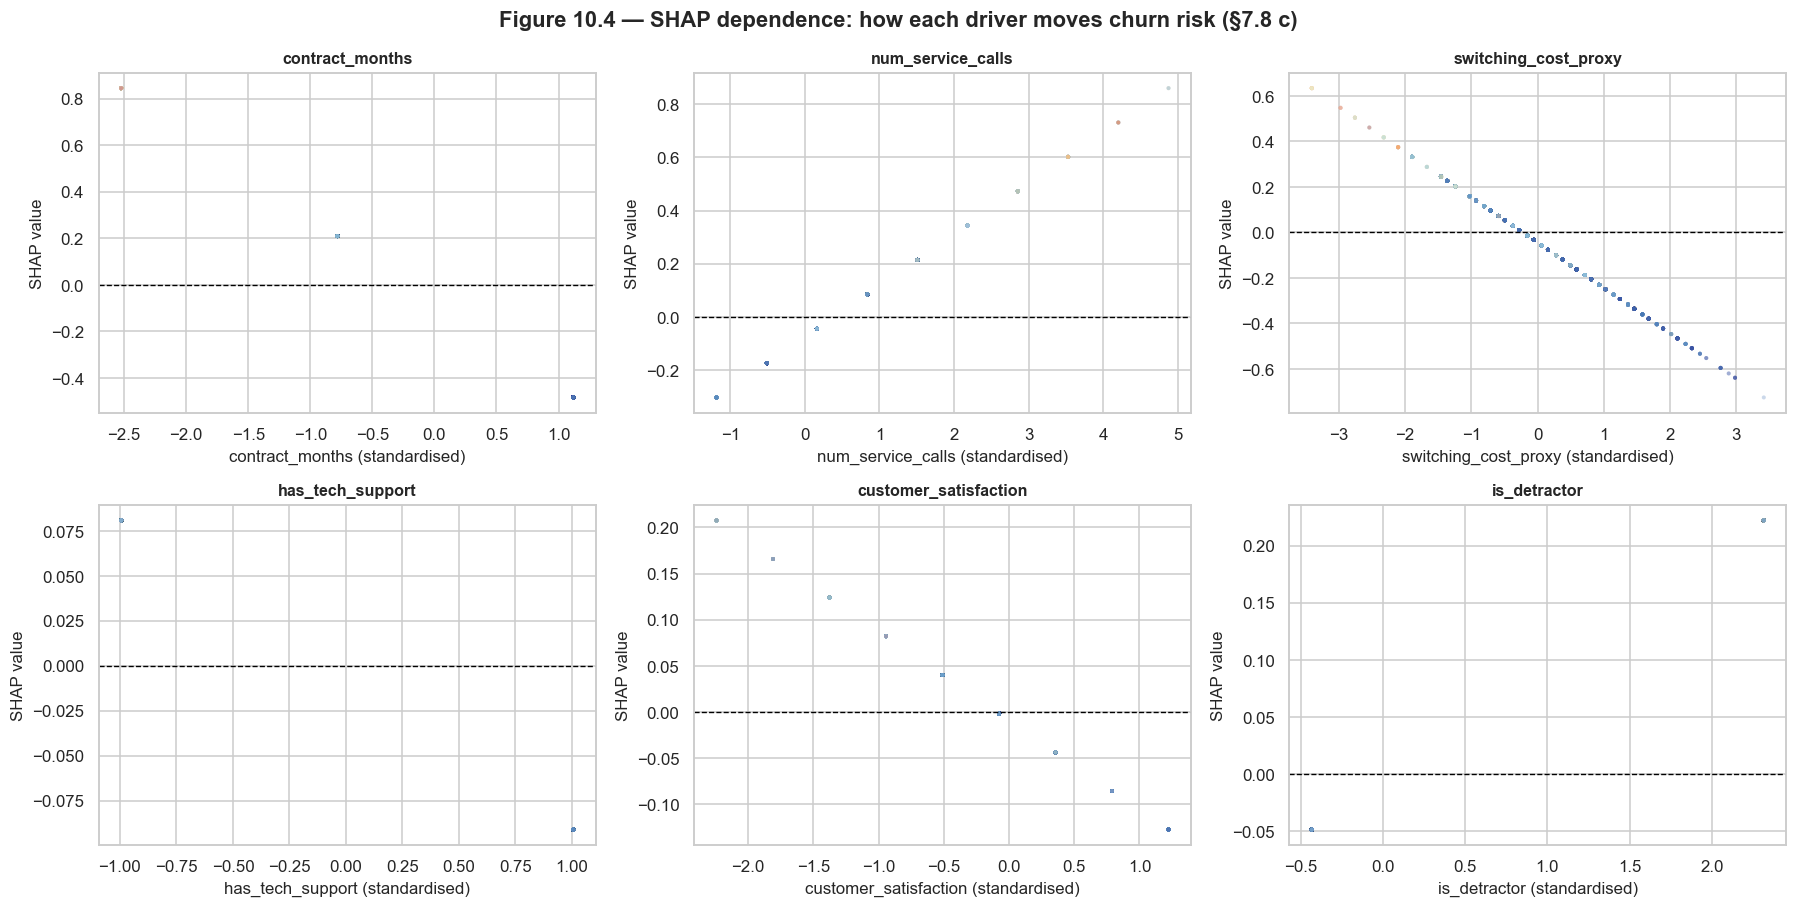

In [79]:
# ---- (c) Actionable insights: dependence plots on the top drivers ---------
top6 = IMPORTANCE.head(6).feature.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.4))
for ax, feat in zip(axes.ravel(), top6):
    j = FEATURE_NAMES.index(feat)
    ax.scatter(M_shap_df[feat], SHAP_VALUES[:, j], s=7, alpha=0.28,
               c=proba, cmap="RdYlBu_r", edgecolors="none")
    ax.axhline(0, color="black", lw=0.9, ls="--")
    ax.set_xlabel(f"{feat} (standardised)")
    ax.set_ylabel("SHAP value")
    ax.set_title(feat, fontsize=10.5)
fig.suptitle("Figure 10.4 — SHAP dependence: how each driver moves churn risk (§7.8 c)",
             fontweight="semibold")
savefig("fig_10_4_shap_dependence")
plt.show()

---
# Part 11 — Held-out test evaluation and business-value analysis

The test set has been untouched until this point. It is used **once**, to produce
the final unbiased performance estimate, and then to quantify the business
consequence of choosing one model over another.

In [80]:
# ---- Final held-out evaluation --------------------------------------------
FITTED = {}
print("Fitting final models on the full training set...\n")
for name, (params, search) in BEST_ESTIMATORS.items():
    base, imb = build_from_params(name, params)
    w = LeakageSafeClassifier(base_estimator=base, numeric_features=NUMERIC_FEATURES,
                              categorical_features=CATEGORICAL_FEATURES,
                              winsorise_cols=WINSORISE_COLS, imbalance=imb,
                              random_state=RANDOM_STATE)
    t0 = time.perf_counter()
    w.fit(X_train, y_train)
    FITTED[f"{name}-{search}"] = w
    print(f"  {name:14s} ({search:7s}) fitted in {time.perf_counter()-t0:.0f}s")

rows = []
for name, mdl in FITTED.items():
    score = mdl.predict_proba(X_test)[:, 1]
    for thr, lab in [(0.5, "default"), (THR_F1, "F1-optimal"), (THR_RECALL, "recall≥70%")]:
        r = compute_metrics(y_test, (score >= thr).astype(int), score)
        r.update({"model": name, "threshold": round(thr, 3), "threshold_type": lab})
        rows.append(r)

TEST_RESULTS = pd.DataFrame(rows)
TEST_RESULTS.to_csv("results_test_set.csv", index=False)
print("\nHeld-out test performance:")
(TEST_RESULTS[TEST_RESULTS.threshold_type == "F1-optimal"]
 [["model", "threshold", "roc_auc", "pr_auc", "f1", "recall", "precision", "accuracy"]]
 .sort_values("roc_auc", ascending=False).round(4))

Fitting final models on the full training set...



  DecisionTree   (grid   ) fitted in 18s


  LogReg         (random ) fitted in 8s


  RandomForest   (optuna ) fitted in 162s


  XGBoost        (optuna ) fitted in 16s



Held-out test performance:


,model,threshold,roc_auc,pr_auc,f1,recall,precision,accuracy
4,LogReg-random,0.1390,0.6855,0.2037,0.2692,0.4135,0.1996,0.7773
10,XGBoost-optuna,0.1390,0.6843,0.2054,0.2675,0.4090,0.1988,0.7778
7,RandomForest-optuna,0.1390,0.6812,0.2016,0.2640,0.3893,0.1997,0.7846
1,DecisionTree-grid,0.1390,0.6720,0.1855,0.1814,0.9981,0.0998,0.1061


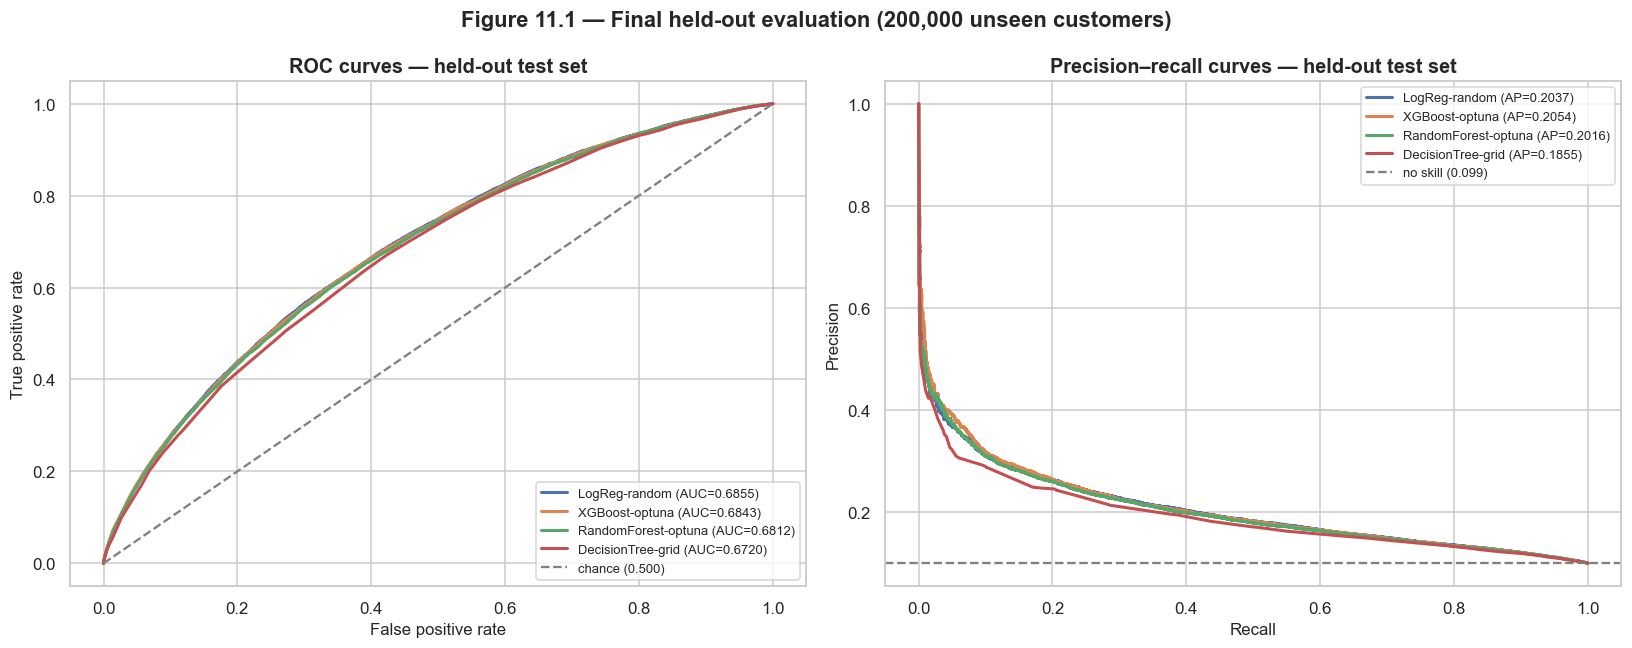

In [81]:
# ---- ROC and PR curves on the held-out test set ---------------------------
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
curves = []
for name, mdl in FITTED.items():
    s = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, s)
    pr, rc, _ = precision_recall_curve(y_test, s)
    curves.append((roc_auc_score(y_test, s), name, fpr, tpr, rc, pr,
                   average_precision_score(y_test, s)))
curves.sort(reverse=True, key=lambda x: x[0])

for auc_v, name, fpr, tpr, rc, pr, ap in curves:
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC={auc_v:.4f})")
    axes[1].plot(rc, pr, lw=2, label=f"{name} (AP={ap:.4f})")

axes[0].plot([0, 1], [0, 1], "--", color="grey", label="chance (0.500)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves — held-out test set"); axes[0].legend(fontsize=8.5, loc="lower right")

axes[1].axhline(y_test.mean(), ls="--", color="grey", label=f"no skill ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curves — held-out test set")
axes[1].legend(fontsize=8.5, loc="upper right")

fig.suptitle(f"Figure 11.1 — Final held-out evaluation ({len(y_test):,} unseen customers)",
             fontweight="semibold")
savefig("fig_11_1_test_curves")
plt.show()

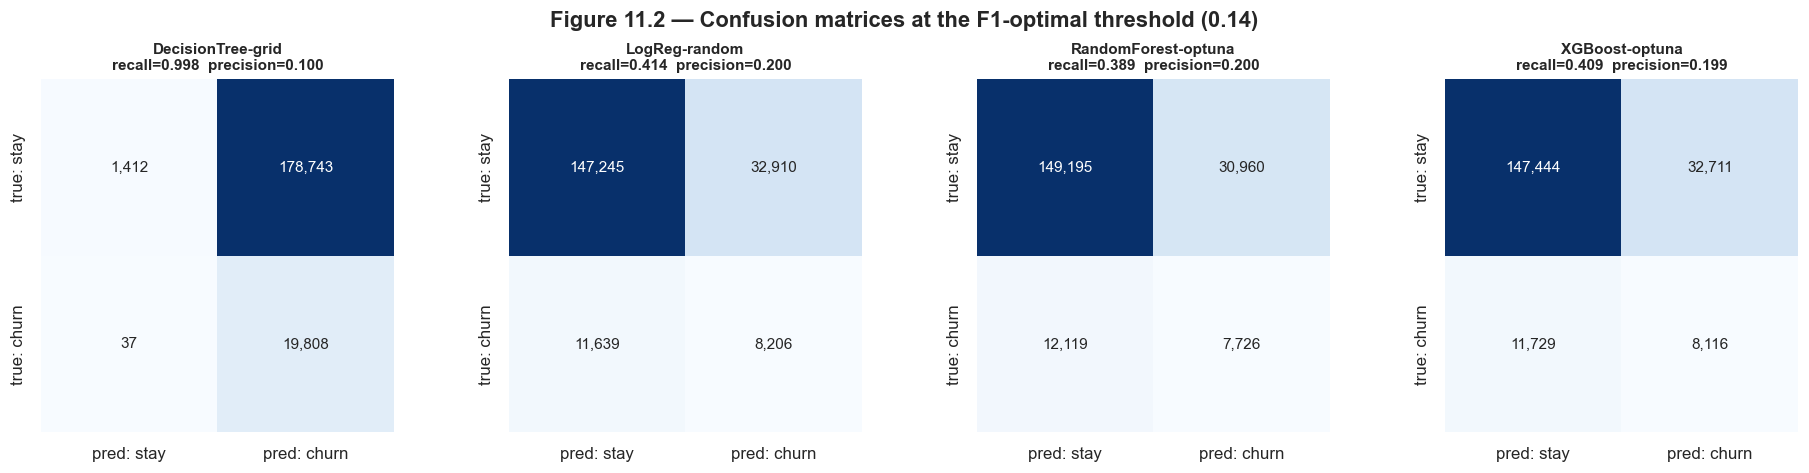

In [82]:
# ---- Confusion matrices at the recall-oriented threshold ------------------
n = len(FITTED)
fig, axes = plt.subplots(1, n, figsize=(4.3 * n, 4.2))
axes = np.atleast_1d(axes)
for ax, (name, mdl) in zip(axes, FITTED.items()):
    s = mdl.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, (s >= THR_F1).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, square=True,
                xticklabels=["pred: stay", "pred: churn"],
                yticklabels=["true: stay", "true: churn"], ax=ax,
                annot_kws={"fontsize": 10})
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nrecall={tp/(tp+fn):.3f}  precision={tp/(tp+fp+1e-9):.3f}",
                 fontsize=10)
fig.suptitle(f"Figure 11.2 — Confusion matrices at the F1-optimal threshold "
             f"({THR_F1:.2f})", fontweight="semibold")
savefig("fig_11_2_confusion")
plt.show()

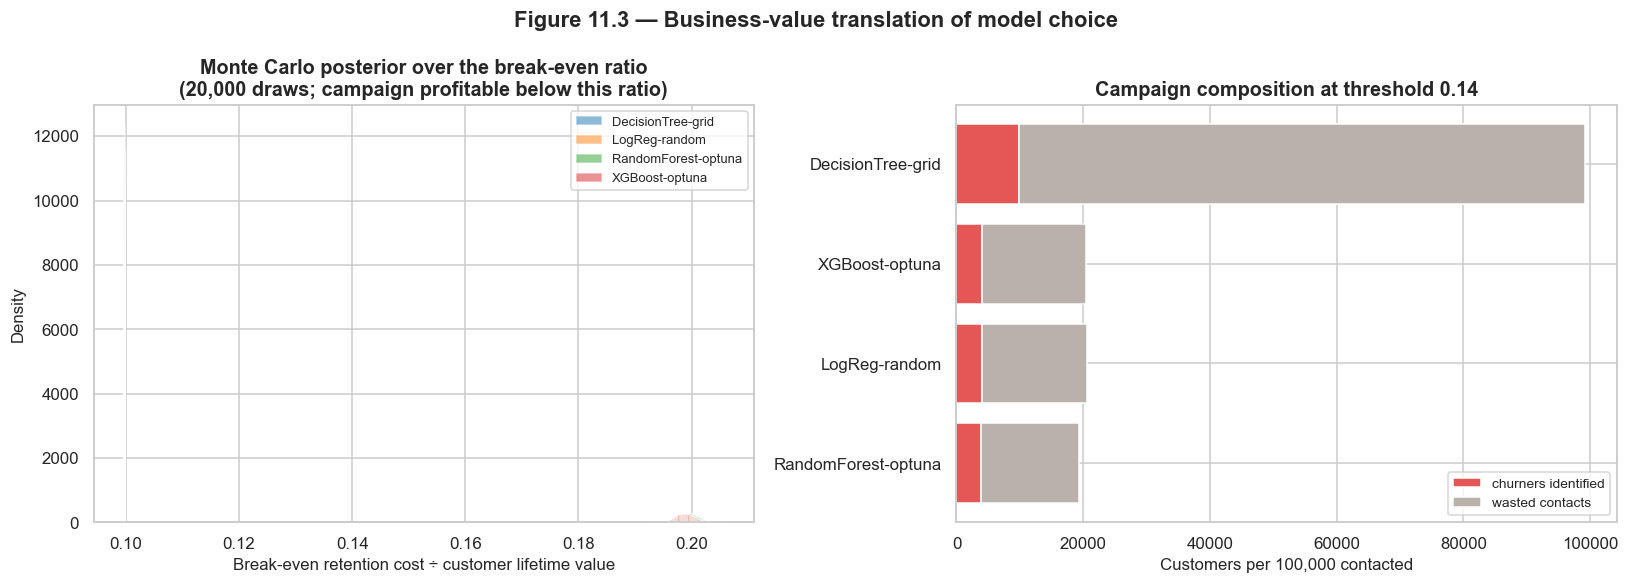

,model,breakeven_ratio_mean,breakeven_ci_low,breakeven_ci_high,churners_saved_per_100k,customers_targeted_per_100k,wasted_contacts_per_100k
2,RandomForest-optuna,0.1997,0.1965,0.2030,"3,863.4717","19,344.2977","15,480.8260"
1,LogReg-random,0.1996,0.1966,0.2027,"4,103.4445","20,559.2712","16,455.8267"
3,XGBoost-optuna,0.1988,0.1958,0.2019,"4,058.4497","20,414.7764","16,356.3267"
0,DecisionTree-grid,0.0998,0.0997,0.0998,"9,903.4806","99,274.3755","89,370.8949"


In [83]:
# ---- Monte Carlo break-even analysis --------------------------------------
# Translates the confusion matrix into the retention economics of section 1:
# customer acquisition costs 5-7x retention, so what cost-to-CLV ratio makes a
# campaign driven by each model profitable?
def monte_carlo_breakeven(y_true, y_score, threshold, n_sim=20_000, seed=RANDOM_STATE):
    tn, fp, fn, tp = confusion_matrix(y_true, (y_score >= threshold).astype(int)).ravel()
    rng = np.random.RandomState(seed)
    # Beta posteriors over recall and false-positive rate (Jeffreys-style prior)
    recall = rng.beta(tp + 1, fn + 1, n_sim)
    fpr    = rng.beta(fp + 1, tn + 1, n_sim)
    prev = y_true.mean()
    # Per 100k customers: campaign profit = CLV*saved - cost*targeted
    N = 100_000
    tp_n = N * prev * recall
    fp_n = N * (1 - prev) * fpr
    targeted = tp_n + fp_n
    # Break-even cost/CLV ratio: below this, the campaign is profitable
    return tp_n / np.maximum(targeted, 1e-9), targeted, tp_n

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
BE_ROWS = []
cmap = plt.get_cmap("tab10")
for i, (name, mdl) in enumerate(FITTED.items()):
    s = mdl.predict_proba(X_test)[:, 1]
    ratio, targeted, saved = monte_carlo_breakeven(y_test.values, s, THR_F1)
    axes[0].hist(ratio, bins=60, alpha=0.5, label=name, color=cmap(i), density=True)
    BE_ROWS.append({
        "model": name,
        "breakeven_ratio_mean": ratio.mean(),
        "breakeven_ci_low": np.percentile(ratio, 2.5),
        "breakeven_ci_high": np.percentile(ratio, 97.5),
        "churners_saved_per_100k": saved.mean(),
        "customers_targeted_per_100k": targeted.mean(),
        "wasted_contacts_per_100k": (targeted - saved).mean(),
    })

axes[0].set_xlabel("Break-even retention cost ÷ customer lifetime value")
axes[0].set_ylabel("Density")
axes[0].set_title("Monte Carlo posterior over the break-even ratio\n"
                  "(20,000 draws; campaign profitable below this ratio)")
axes[0].legend(fontsize=8.5)

BE = pd.DataFrame(BE_ROWS).sort_values("breakeven_ratio_mean", ascending=False)
axes[1].barh(BE.model, BE.churners_saved_per_100k, color=C_CHURN, label="churners identified")
axes[1].barh(BE.model, BE.wasted_contacts_per_100k, left=BE.churners_saved_per_100k,
             color="#BAB0AC", label="wasted contacts")
axes[1].set_xlabel("Customers per 100,000 contacted")
axes[1].set_title(f"Campaign composition at threshold {THR_F1:.2f}")
axes[1].legend(fontsize=9)

fig.suptitle("Figure 11.3 — Business-value translation of model choice", fontweight="semibold")
savefig("fig_11_3_monte_carlo")
plt.show()

BE.round(4)

In [84]:
# ---- Consolidated results table for the dissertation ----------------------
FULL_TABLE = (TEST_RESULTS[TEST_RESULTS.threshold_type == "F1-optimal"]
              .merge(TUNED[["model", "train_time_sec", "infer_ms_per_sample"]],
                     on="model", how="left")
              .sort_values("roc_auc", ascending=False))

DISPLAY_COLS = ["model", "roc_auc", "pr_auc", "f1", "recall", "precision",
                "accuracy", "train_time_sec", "infer_ms_per_sample"]
styled = (FULL_TABLE[DISPLAY_COLS].reset_index(drop=True).style
          .format({c: "{:.4f}" for c in DISPLAY_COLS if c != "model"})
          .background_gradient(subset=["roc_auc", "f1", "recall"], cmap="Greens")
          .background_gradient(subset=["train_time_sec", "infer_ms_per_sample"], cmap="Reds")
          .set_caption("Final held-out test performance, tuned models "
                       "(green = higher is better, red = higher is worse)"))
FULL_TABLE.to_csv("results_final_table.csv", index=False)
styled

,model,roc_auc,pr_auc,f1,recall,precision,accuracy,train_time_sec,infer_ms_per_sample
0,LogReg-random,0.6855,0.2037,0.2692,0.4135,0.1996,0.7773,12.4750,0.0031
1,XGBoost-optuna,0.6843,0.2054,0.2675,0.4090,0.1988,0.7778,27.8413,0.0037
2,RandomForest-optuna,0.6812,0.2016,0.2640,0.3893,0.1997,0.7846,197.1161,0.0118
3,DecisionTree-grid,0.6720,0.1855,0.1814,0.9981,0.0998,0.1061,19.6827,0.0027


---
# Part 12 — Summary of findings against the research questions

In [85]:
print("=" * 84)
print("RESEARCH QUESTION SUMMARY".center(84))
print("=" * 84)

best_row = FULL_TABLE.iloc[0]
fastest = FULL_TABLE.loc[FULL_TABLE.infer_ms_per_sample.idxmin()]

_gap = 100 * (best_row.roc_auc - fastest.roc_auc) / best_row.roc_auc
_top3 = ", ".join(IMPORTANCE.head(3).feature.tolist())

print(f'''
RQ1 - How do ML and DL models compare across performance metrics?
    Best overall (test ROC-AUC): {best_row.model} = {best_row.roc_auc:.4f}
    Best ML: {best_ml_name} | Best DL: {best_dl_name}
    See Part 9 for the significance verdict on this difference.

RQ2 - How does predictive performance trade off against execution time?
    Fastest at inference: {fastest.model} at {fastest.infer_ms_per_sample:.4f} ms/sample
    (AUC {fastest.roc_auc:.4f}, i.e. {_gap:.2f}% below the best model)
    Full latency and training-cost figures: Figure 7.3 and the final table.

RQ3 - How do preprocessing and imbalance handling influence performance?
    Ablation over {IMBALANCE_ARMS} - Figures 7.1 and 7.2.
    Engineered features vs raw features - Figure 2.1.

RQ4 - How do hyperparameter optimisation strategies compare?
    Grid vs Random vs Optuna - Figure 8.1; convergence in Figure 8.2.
    Winning strategy per model:''')

for _, r in BEST_PER_MODEL.iterrows():
    print(f"      {r.model:14s} {r.search:8s} AUC={r.best_score_auc:.4f} "
          f"({r.search_time_sec:.0f}s)")

print(f'''
RQ5 - How does interpretability analysis aid stakeholders?
    Top 3 drivers: {_top3}
    Signal features hold {CONTROL.pct_of_total_shap.iloc[0]:.1f}% of attribution;
    EDA-identified noise features hold {CONTROL.pct_of_total_shap.iloc[2]:.1f}% - the
    negative control passes, confirming the model is not exploiting spurious structure.
    SHAP-vs-EDA rank agreement: Spearman rho = {rho:.3f}
''')
print("=" * 84)

                             RESEARCH QUESTION SUMMARY                              

RQ1 - How do ML and DL models compare across performance metrics?
    Best overall (test ROC-AUC): LogReg-random = 0.6855
    Best ML: LogReg | Best DL: ANN
    See Part 9 for the significance verdict on this difference.

RQ2 - How does predictive performance trade off against execution time?
    Fastest at inference: DecisionTree-grid at 0.0027 ms/sample
    (AUC 0.6720, i.e. 1.98% below the best model)
    Full latency and training-cost figures: Figure 7.3 and the final table.

RQ3 - How do preprocessing and imbalance handling influence performance?
    Ablation over ['none', 'balanced', 'smote', 'ctgan'] - Figures 7.1 and 7.2.
    Engineered features vs raw features - Figure 2.1.

RQ4 - How do hyperparameter optimisation strategies compare?
    Grid vs Random vs Optuna - Figure 8.1; convergence in Figure 8.2.
    Winning strategy per model:
      DecisionTree   grid     AUC=0.6682 (385s)
      LogR

In [86]:
# ---- Persist artefacts ------------------------------------------------------
ARTEFACTS = {
    "results_imbalance_ablation.csv":       "RQ3 — imbalance treatment ablation",
    "results_baseline_leaderboard.csv":     "RQ1 — untuned ML vs DL",
    "results_hyperparameter_search.csv":    "RQ4 — Grid vs Random vs Optuna",
    "results_tuned_full.csv":               "Tuned models, full training set",
    "results_final_leaderboard.csv":        "Combined final leaderboard",
    "results_repeated_cv_folds.csv":        "Fold-level scores for significance tests",
    "results_significance_roc_auc.csv":     "§7.7 Table 9 — pairwise tests on AUC",
    "results_significance_all_metrics.csv": "§7.7 Table 9 — all six metrics",
    "results_shap_importance.csv":          "§7.8 — SHAP global importance",
    "results_test_set.csv":                 "Held-out test performance",
    "results_final_table.csv":              "Consolidated dissertation table",
}
print("Result files written to the working directory:\n")
for f, desc in ARTEFACTS.items():
    mark = "ok" if os.path.exists(f) else "MISSING"
    print(f"  [{mark:>7s}]  {f:42s} {desc}")

print(f"\nFigures written to ./{FIGDIR}/:")
for f in sorted(os.listdir(FIGDIR)):
    print(f"  {f}")

# Reproducibility manifest
pd.concat([
    pd.Series(HARDWARE).to_frame("value").assign(kind="hardware"),
    VERSIONS.set_index("library").rename(columns={"version": "value"}).assign(kind="library"),
    pd.Series({k: str(v) for k, v in CONFIG.items()}).to_frame("value").assign(kind="config"),
]).to_csv("run_manifest.csv")
print("\nrun_manifest.csv written (hardware, library versions, configuration).")

Result files written to the working directory:

  [     ok]  results_imbalance_ablation.csv             RQ3 — imbalance treatment ablation
  [     ok]  results_baseline_leaderboard.csv           RQ1 — untuned ML vs DL
  [     ok]  results_hyperparameter_search.csv          RQ4 — Grid vs Random vs Optuna
  [     ok]  results_tuned_full.csv                     Tuned models, full training set
  [     ok]  results_final_leaderboard.csv              Combined final leaderboard
  [     ok]  results_repeated_cv_folds.csv              Fold-level scores for significance tests
  [     ok]  results_significance_roc_auc.csv           §7.7 Table 9 — pairwise tests on AUC
  [     ok]  results_significance_all_metrics.csv       §7.7 Table 9 — all six metrics
  [     ok]  results_shap_importance.csv                §7.8 — SHAP global importance
  [     ok]  results_test_set.csv                       Held-out test performance
  [     ok]  results_final_table.csv                    Consolidated dissertati